# Southern Ocean air–sea CO₂ fluxes: observations, reconstructions and Global Carbon Budget benchmarks

This notebook produces the flux results of the manuscript *"The Southern Ocean CO₂ sink in an evolving observing system"*: main-text Figures 3–7, Tables 1 and 2, and Supplementary Tables S2–S4.

## Pipeline overview

1. **Inputs.** Six monthly, 1° × 1° pCO₂ data sets south of 30°S, restricted to 2004–2024:
   - three **observation-based (OBS)** data sets, made only of grid cells where pCO₂ was measured: SOCAT, BGC-Argo floats, and SOCAT + floats combined;
   - three **reconstructions (MODEL)**: the gap-filled MLP predictions trained on SOCAT only, on floats only, and on both (uncertainty-weighted).
2. **ERA5 fields.** Monthly ERA5 sea-level pressure is attached to every OBS grid cell (the MODEL tables already carry the same field). Monthly ERA5 10 m wind speed (si10) is attached to all six tables.
3. **Combined OBS.** SOCAT and float cells are merged. Where both exist in the same cell and month, their pCO₂ values are averaged with inverse-variance weights.
4. **pCO₂ → flux.** For every grid cell and month: atmospheric xCO₂ is converted to atmospheric pCO₂ (PyCO2SYS), the gas transfer velocity is computed from the squared ERA5 wind speed (Ho et al., 2006), and the bulk flux is calculated with pyseaflux.
5. **Spatial integration.** Fluxes are weighted by open-water fraction (1 − sea-ice fraction) and by grid-cell area, averaged, and scaled to the ocean area of the domain. Two domains are used: south of 30°S (comparable to the Global Carbon Budget) and the Fay & McKinley (2014) Southern Ocean biomes (comparable to Hauck et al., 2023a).
6. **Uncertainty.** All pCO₂ values are shifted by −1σ and +1σ and the fluxes recomputed. Half the difference gives the flux uncertainty.
7. **Benchmarks.** Global Carbon Budget fCO₂ products, ocean biogeochemical models (GOBMs, simulation A) and atmospheric inversions are extracted south of 30°S.
8. **Results.** Annual and seasonal flux time series, multi-year means with Monte Carlo uncertainty, linear trends and trend robustness tests.

## Conventions

- **Sign:** negative flux = ocean CO₂ uptake (sink); positive = outgassing.
- **Units:** Pg C yr⁻¹ for fluxes; Pg C yr⁻² or Pg C yr⁻¹ decade⁻¹ for trends.
- **Period:** 2004–2024 unless stated otherwise. 2003 is not used because it is only partly covered by the data; an annual mean built from part of a year would be biased by the seasonal cycle.
- **Grid:** 1° cells, identified by the floor of their latitude and longitude (the cell centred on −45.5°, 10.5° is cell (−46, 10)).
- **River flux:** no river adjustment is applied to any data set. All estimates are compared as net sea–air fluxes.

## Outputs

| Notebook section | Manuscript item | File |
|---|---|---|
| Annual OBS fluxes | Figure 3 | `Fig3.png` |
| Seasonal cycle of OBS fluxes | Figure 4 | `Fig4.png` |
| Annual fluxes vs. Global Carbon Budget | Figure 5 | `Fig5.png` |
| Multi-year mean fluxes | Figure 6, Table S2 | `Fig6.png` |
| Seasonal pCO₂ difference maps | Figure 7 | `Fig7.png` |
| Linear trends 2004–2024 | Table 1 | printed |
| Decadal trends, biome domain | Table 2 | printed |
| Trend robustness | Tables S3 and S4 | printed |

## 1. Set-up

### 1.1 Libraries, constants and input files

- `SOCAT_SIGMA = 5 µatm` is the uncertainty assigned to every SOCAT pCO₂ value.
- `WIND_COL = "si10"`: the wind speed used for gas transfer is ERA5 si10, the monthly mean of the instantaneous 10 m wind speed (file `SI10_PATH`).
- `WIND_SECOND_MOMENT_COL` names an optional column holding the monthly mean of the squared wind speed (⟨U²⟩). If a table has this column, it is used instead of si10² (see Section 1.6).
- The six input tables are listed in `PATHS`. The combined OBS table is not read from file: it is built from the SOCAT and float tables in Section 2.4.

In [35]:
import pandas as pd
import numpy as np
import pyseaflux
import PyCO2SYS as pyco2
import xarray as xr
from scipy.spatial import cKDTree
from functools import reduce

# ============================================================
# CONSTANTS / PATHS
# ============================================================
SOCAT_SIGMA = 5.0
# Optional column holding the monthly mean of the squared wind speed <U^2>
# (m2 s-2), e.g. computed from hourly or 6-hourly ERA5. If a table does not
# have it, the flux calculation uses (monthly wind speed)^2 instead.
WIND_SECOND_MOMENT_COL = "wind_speed_sq_mean"

# Wind speed used for the gas transfer velocity: ERA5 si10, the monthly mean
# of the instantaneous 10 m wind speed. The older 'wind_speed' column is the
# speed of the monthly-mean wind vector, sqrt(u10_mean^2 + v10_mean^2), which
# is always smaller because changes in wind direction cancel out.
WIND_COL = "si10"
SI10_PATH = "/remote/unity/bgc-output/DELAIGUE/GCB-LOV/data/ERA5/ERA5_monthly_1997_2025_u10_v10_msl_si10.nc"
SI10_NAMES = ["si10", "10m_wind_speed", "ws10", "wind_speed"]
AREA_CSV = "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/data/ocean_mask/ocean_area_south_of_30S.csv"
SIC_PATH = "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/data/fronts/sic_climatology_stats_sh_1991-2020.nc"
BIOME_PATH = "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/data/ocean_mask/Time_Varying_Biomes.nc"

PATHS = {
    "socat_obs": "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/MODEL_SOCAT_ONLY_OBS_v2/processing_steps/SOCATv2025_SO_feature_engineered_monthly_1deg_pCO2.csv",
    "socat_pred": "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/PREDICTION_MATRIX_v2/matrix_predictions/pco2_prediction_matrix_SOCAT_only_MCensemble.csv",
    "floats_obs": "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/MODEL_FLOATS_v2/processing_steps/BGC-Argo_SO_feature_engineered_monthly_1deg.csv",
    "floats_pred": "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/PREDICTION_MATRIX_v2/matrix_predictions/pco2_prediction_matrix_FLOATS_only_MCensemble.csv",
    # "combined_obs" is no longer read from pco2_all_splits_combined.csv: it is
    # rebuilt below from the two full gridded OBS files above (FIX 3).
    "combined_pred_weighted": "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/PREDICTION_MATRIX_v2/matrix_predictions/pco2_prediction_matrix_SOCAT_AND_FLOATS_weighted_MCensemble.csv",
}
# ERA5 monthly u10/v10/msl file -- the same file 1E_match_WIND.py used to put
# msl_atm on the prediction matrix (FIX 2).
ERA5_PATH = "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/data/wind/e4dde318f3aedf9d1177508c7662a49f.nc"
PA_PER_ATM = 101325.0

### 1.2 Grid-cell identifiers

Every latitude and longitude is assigned to a 1° grid cell by rounding **down** (`np.floor`). A cell centred on −0.5° belongs to cell −1, and a cell centred on +0.5° belongs to cell 0. Rounding toward zero (`astype(int)`) would put both of these cells in cell 0 and merge them. Longitudes are converted to the range −180° to 180° before binning.

In [36]:
# ============================================================
# GRID BINNING (FIX 4)
# ============================================================
# Every lat/lon -> 1-degree bin assignment in this cell goes through this
# helper. np.floor maps a cell centre x.5 to the bin x for both signs
# (-0.5 -> -1, 0.5 -> 0). The previous .astype(int) truncates toward zero, so
# the two cells either side of 0 deg longitude (-0.5 and 0.5) were merged into
# one bin, and the same happened for any non-centred coordinate near 0.
def to_bin(values):
    return np.floor(np.asarray(values, dtype=float)).astype(int)

def wrap_lon(lon):
    """Longitude to [-180, 180)."""
    lon = np.asarray(lon, dtype=float)
    return ((lon + 180.0) % 360.0) - 180.0

### 1.3 Sea-ice fraction

Air–sea exchange only happens over open water. The monthly sea-ice concentration climatology (DMI, 1991–2020) is mapped onto the 1° grid by taking the nearest sea-ice grid point to each 1° cell centre (nearest neighbour on the sphere). The result is a table of ice fraction (0–1) for every grid cell and calendar month. It is used in Section 1.4 to weight each cell's flux by its open-water fraction.

In [37]:
# ============================================================
# SEA ICE FRACTION (DMI Southern Hemisphere SIC climatology, 1991-2020)
# ============================================================
def _latlon_to_xyz(lat, lon):
    lat_r, lon_r = np.radians(lat), np.radians(lon)
    return np.column_stack([
        np.cos(lat_r) * np.cos(lon_r),
        np.cos(lat_r) * np.sin(lon_r),
        np.sin(lat_r),
    ])

def build_ice_fraction_lookup(sic_path):
    seaice = xr.load_dataset(sic_path)
    ice_frac_clim = seaice["mmean"] / 100.0  # (month, yc, xc), 0-1 open/ice fraction

    src_lat = seaice["lat"].values.ravel()
    src_lon = seaice["lon"].values.ravel()
    tree = cKDTree(_latlon_to_xyz(src_lat, src_lon))

    target_lat_centers = np.arange(-89.5, -19.5 + 1, 1.0)
    target_lon_centers = np.arange(-179.5, 179.5 + 1, 1.0)
    tlat_grid, tlon_grid = np.meshgrid(target_lat_centers, target_lon_centers, indexing="ij")
    _, nn_idx = tree.query(_latlon_to_xyz(tlat_grid.ravel(), tlon_grid.ravel()), k=1)

    n_month = ice_frac_clim.shape[0]
    ice_frac_grid = np.full((n_month, target_lat_centers.size, target_lon_centers.size), np.nan)
    for m in range(n_month):
        ice_frac_grid[m] = ice_frac_clim.isel(month=m).values.ravel()[nn_idx].reshape(tlat_grid.shape)

    lat_bin_flat = to_bin(tlat_grid.ravel())
    lon_bin_flat = to_bin(tlon_grid.ravel())

    records = [
        pd.DataFrame({
            "lat_bin": lat_bin_flat,
            "lon_bin": lon_bin_flat,
            "month": m + 1,
            "ice_fraction": ice_frac_grid[m].ravel(),
        })
        for m in range(n_month)
    ]
    return pd.concat(records, ignore_index=True)

print("Building sea ice fraction lookup from DMI SIC climatology...")
ice_frac_lookup = build_ice_fraction_lookup(SIC_PATH)
print(f"Ice fraction lookup: {len(ice_frac_lookup):,} (lat_bin, lon_bin, month) rows")

Building sea ice fraction lookup from DMI SIC climatology...
Ice fraction lookup: 306,720 (lat_bin, lon_bin, month) rows


### 1.4 Grid-cell area and area-weighted mean

- The area of each 1° cell is computed from its latitude band on a sphere of radius 6,371 km and stored by latitude cell.
- `bin_flux` averages all rows that fall in the same grid cell and month.
- `area_weighted_monthly_mean` computes, for each month:

  mean flux = Σ (flux × cell area × open-water fraction) / Σ (cell area)

  The open-water fraction is applied only in the numerator. Ice-covered parts of a cell therefore contribute zero flux but still count as part of the domain area. Cells without an ice value are treated as ice-free.
- The sum runs only over the cells that have data in that month. For the OBS data sets, this means the mean of the sampled cells stands in for the whole domain. For the reconstructions, all cells are filled.

In [38]:
# ============================================================
# GRID / AREA WEIGHTING
# ============================================================
R = 6371000
DEG2RAD = np.pi / 180
lat_centers = np.arange(-89.5, 90.0, 1.0)          # -89.5 ... 89.5 (180 bands)
band_areas = 2 * np.pi * R**2 * (
    np.sin((lat_centers + 0.5) * DEG2RAD) - np.sin((lat_centers - 0.5) * DEG2RAD)
)
# Indexed by the floor bin of each band centre (-90 ... 89), consistent with
# to_bin(): the band centred on -45.5 is lat_bin -46. (The old index
# np.arange(-89, 90) matched the old truncation binning instead.)
cell_area_by_lat = pd.Series(band_areas / 360, index=to_bin(lat_centers))

def bin_flux(df, lat_col, lon_col, time_col, flux_col):
    out = df.copy()
    out["lat_bin"] = to_bin(out[lat_col])
    out["lon_bin"] = to_bin(wrap_lon(out[lon_col]))
    out["year"] = out[time_col].dt.year
    out["month"] = out[time_col].dt.month
    return (
        out.groupby(["lat_bin", "lon_bin", "year", "month"], as_index=False)[flux_col]
        .mean()
        .rename(columns={flux_col: "mean_flux"})
    )

def area_weighted_monthly_mean(binned):
    df = binned.merge(
        cell_area_by_lat.rename("cell_area_m2"),
        left_on="lat_bin",
        right_index=True,
        how="left",
    )
    df = df.merge(
        ice_frac_lookup,
        on=["lat_bin", "lon_bin", "month"],
        how="left",
    )
    df["open_weight"] = 1.0 - df["ice_fraction"].fillna(0.0)
    df["weighted_flux"] = df["mean_flux"] * df["cell_area_m2"] * df["open_weight"]
    out = (
        df.groupby(["year", "month"], as_index=False)
        .agg(
            total_flux=("weighted_flux", "sum"),
            total_area=("cell_area_m2", "sum"),
        )
    )
    out["aw_mean_flux"] = out["total_flux"] / out["total_area"]
    out["date"] = pd.to_datetime(dict(year=out["year"], month=out["month"], day=15))
    return out[["year", "month", "date", "aw_mean_flux"]]

### 1.5 Biome domain (Fay & McKinley, 2014)

The second domain keeps only the three Southern Ocean biomes (subtropical seasonally stratified, subpolar seasonally stratified and ice; biome codes 15, 16 and 17) from the `MeanBiomes` field. This domain lies roughly south of 35°S and matches the one used by Hauck et al. (2023a). Its total ocean area is the sum of the areas of its grid cells.

In [39]:
# ============================================================
# SOUTHERN OCEAN BIOME MASK (Fay & McKinley 2014, mean biomes)
# ============================================================
# Restricts to the SO STSS / SO SPSS / SO ICE biomes (codes 15, 16, 17),
# using the "MeanBiomes" product -- the typical/majority biome assignment
# per cell across 1998-2010 -- since your record (2004-2024) extends well
# past that product's own coverage window.
# Grid is an exact 1x1 match to the rest of this pipeline, so no
# regridding is needed, just a direct lat_bin/lon_bin filter.
SO_BIOME_CODES = {15, 16, 17}  # SO STSS, SO SPSS, SO ICE

def build_biome_lookup(biome_path, codes=SO_BIOME_CODES):
    biomes = xr.load_dataset(biome_path)
    so_mask = biomes["MeanBiomes"].isin(list(codes))
    lookup = so_mask.to_dataframe(name="in_so_biome").reset_index()
    lookup["lat_bin"] = to_bin(lookup["lat"])
    lookup["lon_bin"] = to_bin(wrap_lon(lookup["lon"]))
    lookup = lookup.loc[lookup["in_so_biome"], ["lat_bin", "lon_bin"]].drop_duplicates()
    return lookup.reset_index(drop=True)

print("Building Southern Ocean biome mask (Fay & McKinley 2014, MeanBiomes)...")
biome_cell_lookup = build_biome_lookup(BIOME_PATH)
print(f"Biome mask: {len(biome_cell_lookup):,} (lat_bin, lon_bin) cells")

BIOME_OCEAN_AREA_M2 = biome_cell_lookup["lat_bin"].map(cell_area_by_lat).sum()
print(f"Using BIOME_OCEAN_AREA_M2 (Fay & McKinley SO biomes) = {BIOME_OCEAN_AREA_M2:.3e} m²")

Building Southern Ocean biome mask (Fay & McKinley 2014, MeanBiomes)...
Biome mask: 11,460 (lat_bin, lon_bin) cells
Using BIOME_OCEAN_AREA_M2 (Fay & McKinley SO biomes) = 7.919e+13 m²


### 1.6 Flux formula (pCO₂ → air–sea flux)

For every row (grid cell and month):

1. **Atmospheric pCO₂.** The atmospheric mole fraction xCO₂ (ppm, dry air) is converted to pCO₂ (µatm) with PyCO2SYS, using the local temperature, salinity and ERA5 sea-level pressure. This accounts for the water-vapour correction at the sea surface.
2. **Gas transfer velocity.** k = 0.266 · ⟨U²⟩ · (Sc/600)^−0.5 (Ho et al., 2006), where Sc is the Schmidt number at the local temperature. `pyseaflux.k_Ho06` takes ⟨U²⟩ (in m² s⁻²) as input, not the wind speed. Here ⟨U²⟩ is approximated by si10², the square of the ERA5 monthly mean wind speed.
   - si10 is the average of the instantaneous wind speed. It is preferred over the speed of the monthly-mean wind vector, √(ū² + v̄²), which is much smaller because changes in wind direction during the month cancel out.
   - si10² is still slightly smaller than the true ⟨U²⟩, because squaring an average ignores the variability of the wind within the month (⟨U²⟩ = ⟨U⟩² + variance). The resulting k is therefore a slight underestimate.
   - If a column with the monthly mean of U² from hourly ERA5 is added to the tables (`WIND_SECOND_MOMENT_COL`), it is used automatically.
3. **Flux.** F = k · K₀ · (pCO₂,sea − pCO₂,air), with the CO₂ solubility K₀ from Weiss (1974). `pyseaflux.flux_bulk` returns F in g C m⁻² day⁻¹.

Rows without sea-level pressure would fall back to 1 atm. With ERA5 pressure attached to every row, this fallback is not used; it is kept only as a safeguard and is reported if triggered.

In [40]:
# ============================================================
# FLUX
# ============================================================
def flux_from_pco2(
    df,
    temp_col,
    sal_col,
    pco2_col,
    wind_col=WIND_COL,
    air_col="atm_co2",
):
    """
    Computes the sea-air CO2 flux (g C m-2 day-1; positive = outgassing,
    negative = uptake) from sea pCO2, atmospheric xCO2, temperature,
    salinity, wind and sea-level pressure.
    Atmospheric xCO2 (dry-air mole fraction, ppm) is converted to true
    atmospheric pCO2 (uatm) via a per-cell PyCO2SYS conversion using local
    temp/sal and real ERA5 sea-level pressure (msl_atm) -- Dickson et al.
    (2007) basis, the SeaFlux-standard approach (Fay et al., 2021).
    Validated against Peter Landschützer's independent reference pCO2
    product: RMSE 0.48 uatm, r=0.9995 once matched to the same xCO2 input.

    msl_atm is attached to every OBS row directly from the ERA5 file (see
    "ERA5 SEA-LEVEL PRESSURE" below), so all rows should have it. The
    pres_atm=1.0 fallback is kept only as a safeguard and is reported if it
    is ever used.
    """
    temp = df[temp_col].to_numpy()
    sal = df[sal_col].to_numpy()
    pco2_sw = df[pco2_col].to_numpy()
    wind = df[wind_col].to_numpy()
    xco2 = df[air_col].to_numpy()
    if "msl_atm" in df.columns:
        pres_atm = df["msl_atm"].fillna(1.0).to_numpy()
        n_fallback = df["msl_atm"].isna().sum()
        if n_fallback:
            print(f"  [flux_from_pco2] {n_fallback:,}/{len(df):,} rows "
                  f"({n_fallback/len(df):.1%}) missing msl_atm, using pres_atm=1.0 fallback")
    else:
        print(f"  [flux_from_pco2] WARNING: no msl_atm column, using pres_atm=1.0 for all {len(df):,} rows")
        pres_atm = np.full_like(xco2, 1.0, dtype=float)
    pres_hPa = pres_atm * 1013.25
    mask = np.isfinite(xco2) & np.isfinite(temp) & np.isfinite(sal) & np.isfinite(pres_atm)
    air = np.full_like(xco2, np.nan, dtype=float)
    results = pyco2.sys(
        par1=xco2[mask],
        par1_type=9,
        temperature=temp[mask],
        salinity=sal[mask],
        pressure=0.0,
        pressure_atmosphere=pres_atm[mask],
        opt_pH_scale=1,
        opt_k_carbonic=10,
        opt_k_bisulfate=1,
        opt_total_borate=1,
        opt_buffers_mode=0,
    )
    air[mask] = results["pCO2"]
    # Gas transfer velocity, Ho et al. (2006): k600 = 0.266 * <U^2>.
    # pyseaflux.k_Ho06 expects the SECOND MOMENT of the wind speed (<U^2>,
    # m2 s-2), not the wind speed (m s-1). Use a monthly-mean U^2 column if one
    # is available; otherwise square the monthly mean wind speed (si10).
    if WIND_SECOND_MOMENT_COL in df.columns:
        wind_u2 = df[WIND_SECOND_MOMENT_COL].to_numpy()
    else:
        wind_u2 = wind ** 2
    k_w = pyseaflux.gas_transfer_velocity.k_Ho06(wind_u2, temp)
    # flux_bulk already returns g C m-2 day-1 (it applies the molar mass of
    # carbon internally), so no further unit conversion is needed here.
    return pyseaflux.flux_calculations.flux_bulk(temp, sal, pco2_sw, air, pres_hPa, k_w)

### 1.7 Uncertainty bounds

To propagate pCO₂ uncertainty into the flux, two copies of each table are made: one with pCO₂ − 1σ and one with pCO₂ + 1σ in every cell. The flux is then recomputed for both copies.

- SOCAT OBS: σ = 5 µatm.
- Float OBS: σ = the per-profile pCO₂ uncertainty (`FLOATS_pco2_error_median`).
- Combined OBS: σ = the fused uncertainty from Section 2.4.
- Reconstructions: σ = the standard deviation of the Monte Carlo ensemble (10 architectures × 100 noise realizations) in each cell and month (`ensemble_pco2_std`).

All cells are shifted in the same direction at the same time, so the uncertainty is treated as fully correlated in space within a month.

In [41]:
# ============================================================
# UNCERTAINTY HELPERS
# ============================================================
def make_obs_bounds(df, value_col, sigma):
    low = df.copy()
    high = df.copy()
    if isinstance(sigma, str):
        sigma_values = df[sigma]
    elif np.isscalar(sigma):
        sigma_values = sigma
    else:
        raise TypeError("sigma must be either a numeric scalar or a column name")
    low[value_col] = low[value_col] - sigma_values
    high[value_col] = high[value_col] + sigma_values
    return low, high

def make_pred_bounds(df, pred_col="ensemble_pco2_pred", sigma_col="ensemble_pco2_std"):
    low = df.copy()
    high = df.copy()
    low[pred_col] = low[pred_col] - df[sigma_col]
    high[pred_col] = high[pred_col] + df[sigma_col]
    return low, high

### 1.8 From grid cells to domain totals

For each data set, the expensive flux calculation runs once per version (best estimate, −1σ, +1σ). Each version is then aggregated twice: once over all cells south of 30°S and once over the biome cells only.

1. Daily flux (g C m⁻² day⁻¹) × number of days in the month = monthly flux (g C m⁻² month⁻¹).
2. Area- and ice-weighted mean over the domain (Section 1.4).
3. × 12 months × domain ocean area / 10¹⁵ = flux in Pg C yr⁻¹ (an annualised rate for each month).
4. Annual σ: σ = (flux₊₁σ − flux₋₁σ) / 2 for each month, then averaged over the 12 months of each year.

In [42]:
# ============================================================
# SERIES PIPELINE
# ============================================================
def compute_row_flux(
    df,
    *,
    temp_col,
    sal_col,
    pco2_col,
    time_col="month_center",
):
    """Computes per-row monthly flux once (the expensive PyCO2SYS/flux_bulk step)."""
    out = df.copy()
    out["time"] = pd.to_datetime(out[time_col])
    out["flux_month"] = (
        flux_from_pco2(out, temp_col=temp_col, sal_col=sal_col, pco2_col=pco2_col)
        * out["time"].dt.days_in_month
    )
    return out

def series_from_row_flux(row_flux_df, *, lat_col, lon_col, series_name, biome_lookup=None):
    """Aggregates already-computed per-row flux into a monthly area-weighted series,
    optionally restricted to a biome cell lookup (lat_bin, lon_bin)."""
    binned = bin_flux(
        row_flux_df,
        lat_col=lat_col,
        lon_col=lon_col,
        time_col="time",
        flux_col="flux_month",
    )
    if biome_lookup is not None:
        binned = binned.merge(biome_lookup, on=["lat_bin", "lon_bin"], how="inner")
    out = area_weighted_monthly_mean(binned)
    return out.rename(columns={"aw_mean_flux": series_name})

def bounded_monthly_flux(
    base_df,
    low_df,
    high_df,
    *,
    temp_col,
    sal_col,
    pco2_col,
    lat_col,
    lon_col,
    prefix,
    time_col="month_center",
    biome_lookup=None,
):
    """Returns (full_domain_frames, biome_restricted_frames) for one series,
    computing the per-row flux only once per base/low/high."""
    base_rf = compute_row_flux(base_df, temp_col=temp_col, sal_col=sal_col, pco2_col=pco2_col, time_col=time_col)
    low_rf = compute_row_flux(low_df, temp_col=temp_col, sal_col=sal_col, pco2_col=pco2_col, time_col=time_col)
    high_rf = compute_row_flux(high_df, temp_col=temp_col, sal_col=sal_col, pco2_col=pco2_col, time_col=time_col)

    full_frames = [
        series_from_row_flux(base_rf, lat_col=lat_col, lon_col=lon_col, series_name=prefix),
        series_from_row_flux(low_rf, lat_col=lat_col, lon_col=lon_col, series_name=f"{prefix}_low"),
        series_from_row_flux(high_rf, lat_col=lat_col, lon_col=lon_col, series_name=f"{prefix}_high"),
    ]
    biome_frames = [
        series_from_row_flux(base_rf, lat_col=lat_col, lon_col=lon_col, series_name=prefix, biome_lookup=biome_lookup),
        series_from_row_flux(low_rf, lat_col=lat_col, lon_col=lon_col, series_name=f"{prefix}_low", biome_lookup=biome_lookup),
        series_from_row_flux(high_rf, lat_col=lat_col, lon_col=lon_col, series_name=f"{prefix}_high", biome_lookup=biome_lookup),
    ]
    return full_frames, biome_frames

def merge_on_date(frames):
    return reduce(
        lambda left, right: left.merge(right, on=["year", "month", "date"]),
        frames,
    )

def scale_flux_columns(df, ocean_area_m2, exclude=("year", "month", "date")):
    out = df.copy()
    flux_cols = [col for col in out.columns if col not in exclude]
    out[flux_cols] = out[flux_cols] * 12 * ocean_area_m2 / 1e15
    return out

def add_sigma_column(df, base_name):
    out = df.copy()
    out[f"{base_name}_sigma_PgC_yr"] = 0.5 * (
        out[f"{base_name}_high"] - out[f"{base_name}_low"]
    )
    return out

def yearly_summary(df, value_cols):
    return df.groupby("year", as_index=False)[value_cols].mean()

## 2. Input data

### 2.1 Load the tables and the domain area

- SOCAT OBS and float OBS: monthly 1° tables of measured pCO₂ with in situ temperature and salinity, wind speed and atmospheric xCO₂.
- Reconstructions: monthly 1° prediction matrices with the MC ensemble mean pCO₂ (`ensemble_pco2_pred`) and its standard deviation (`ensemble_pco2_std`).
- The ocean area south of 30°S comes from the GOAS shapefile (1.101 × 10¹⁴ m²).

In [43]:
# ============================================================
# LOAD DATA
# ============================================================
predictions_socat = pd.read_csv(PATHS["socat_pred"])
socat_df = pd.read_csv(PATHS["socat_obs"], low_memory=False)
predictions_floats = pd.read_csv(PATHS["floats_pred"])
floats_df = pd.read_csv(PATHS["floats_obs"], low_memory=False).rename(
    columns={"pco2": "FLOATS_pco2_median"}
)
predictions_combined_weighted = pd.read_csv(PATHS["combined_pred_weighted"])
# combined_df is built further down from socat_df + floats_df (FIX 3)

print("Loading ocean area south of 30°S...")
OCEAN_AREA_M2 = pd.read_csv(AREA_CSV)["ocean_area_m2"].iloc[0]
print(f"Using OCEAN_AREA_M2 = {OCEAN_AREA_M2:.3e} m²")

Loading ocean area south of 30°S...
Using OCEAN_AREA_M2 = 1.101e+14 m²


### 2.2 Restrict to 2004–2024

All five tables are cut to 2004–2024 before any calculation. The combined OBS table is built later from the already restricted SOCAT and float tables, so it covers the same period.

In [44]:
# ============================================================
# RESTRICT TO ANALYSIS WINDOW (2004-2024 inclusive)
# ============================================================
# Applied to all five raw tables (the combined OBS table is built from the
# already-restricted SOCAT and float tables) before any further processing, so we're
# not computing (and then discarding) flux for years outside the analysis
# period, and so the msl_atm match-rate diagnostics below reflect only
# the coverage gap that actually matters.
def restrict_to_analysis_window(df, time_col="month_center", year_min=2004, year_max=2024):
    out = df.copy()
    years = pd.to_datetime(out[time_col]).dt.year
    return out.loc[years.between(year_min, year_max)].reset_index(drop=True)

print("Restricting all tables to 2004-2024...")
for _name in ["predictions_socat", "socat_df", "predictions_floats", "floats_df",
              "predictions_combined_weighted"]:
    _n_before = len(globals()[_name])
    globals()[_name] = restrict_to_analysis_window(globals()[_name])
    _n_after = len(globals()[_name])
    print(f"  {_name:28s} {_n_before:,} -> {_n_after:,} rows")

Restricting all tables to 2004-2024...
  predictions_socat            2,760,918 -> 2,631,476 rows
  socat_df                     56,541 -> 50,823 rows
  predictions_floats           2,760,918 -> 2,631,476 rows
  floats_df                    35,463 -> 35,448 rows
  predictions_combined_weighted 2,760,918 -> 2,631,476 rows


### 2.3 ERA5 sea-level pressure and wind speed

**Sea-level pressure.** Sea-level pressure is needed to convert xCO₂ to pCO₂ and for the CO₂ solubility. It is read directly from the monthly ERA5 file used for the wind data and processed in the same way as for the prediction matrices:

1. keep native ERA5 points that fall in 1° cells south of 30°S, for 2004–2024;
2. assign each point to its 1° cell (floor of latitude and longitude);
3. take the median pressure of the points in each cell and month;
4. convert from Pa to atm (÷ 101,325).

The resulting values are attached to the SOCAT and float tables by grid cell, year and month. As a check, the pressure already stored in the three prediction matrices is compared with this lookup; the maximum difference should be close to zero.

**Wind speed (si10).** The ERA5 monthly mean 10 m wind speed is read from `SI10_PATH`, restricted to south of 30°S and 2004–2024, and averaged over the native ERA5 points in each 1° cell and month (cells defined by the floor of latitude and longitude, as everywhere else). It is attached to all six tables by grid cell, year and month. The printout compares the mean of si10 with the mean of the older `wind_speed` column (speed of the monthly-mean wind vector) for each table; the ratio ⟨si10²⟩/⟨wind_speed²⟩ shows how much larger the gas transfer velocity becomes with si10.

In [45]:
# ============================================================
# ERA5 SEA-LEVEL PRESSURE (FIX 2)
# ============================================================
# The OBS tables do not carry msl_atm. Previously it was borrowed from the
# prediction matrices, which left ~10% of SOCAT rows and ~18% of float rows
# without a match (they fell back to 1 atm). msl_atm is now taken straight
# from the ERA5 file, regridded exactly as in 1E_match_WIND.py (median of
# the native ERA5 points falling in each 1-degree cell, msl / 101325), so OBS
# and MODEL use the same pressure field and every OBS row gets a value.

def _bin_time(df, lat_col, lon_col, time_col="month_center"):
    out = df.copy()
    out["time"] = pd.to_datetime(out[time_col])
    out["lat_bin"] = to_bin(out[lat_col])
    out["lon_bin"] = to_bin(wrap_lon(out[lon_col]))
    out["year"] = out["time"].dt.year
    out["month"] = out["time"].dt.month
    return out

def build_era5_msl_lookup(path, lat_max=-30, year_min=2004, year_max=2024):
    ds = xr.open_dataset(path)
    if "valid_time" in ds.coords and "time" not in ds.coords:
        ds = ds.rename({"valid_time": "time"})
    if "lat" in ds.coords:
        ds = ds.rename({"lat": "latitude"})
    if "lon" in ds.coords:
        ds = ds.rename({"lon": "longitude"})
    msl = ds["msl"]
    # keep only native points that fall in bins <= lat_max (i.e. lat < lat_max + 1)
    msl = msl.isel(latitude=np.where(msl["latitude"].values < lat_max + 1)[0])
    years = msl["time"].dt.year.values
    msl = msl.isel(time=np.where((years >= year_min) & (years <= year_max))[0])

    frames = []
    for t in msl["time"].values:            # one month at a time to keep memory low
        m = msl.sel(time=t).to_dataframe(name="msl").reset_index()
        m = m.dropna(subset=["msl"])
        m["lat_bin"] = to_bin(m["latitude"])
        m["lon_bin"] = to_bin(wrap_lon(m["longitude"]))
        g = m.groupby(["lat_bin", "lon_bin"], as_index=False)["msl"].median()
        ts = pd.Timestamp(t)
        g["year"], g["month"] = ts.year, ts.month
        frames.append(g)
    lookup = pd.concat(frames, ignore_index=True)
    lookup["msl_atm"] = lookup["msl"] / PA_PER_ATM
    return lookup[["lat_bin", "lon_bin", "year", "month", "msl_atm"]]

print("Building ERA5 msl_atm lookup (1-degree, monthly, 2004-2024)...")
msl_lookup = build_era5_msl_lookup(ERA5_PATH)
assert not msl_lookup.duplicated(["lat_bin", "lon_bin", "year", "month"]).any()
print(f"ERA5 msl_atm lookup: {len(msl_lookup):,} (cell, month) rows, "
      f"range {msl_lookup['msl_atm'].min():.3f}-{msl_lookup['msl_atm'].max():.3f} atm")

def build_era5_si10_lookup(path, names=SI10_NAMES, lat_max=-30, year_min=2004, year_max=2024):
    """Monthly ERA5 si10 averaged onto the 1-degree cells (floor binning)."""
    ds = xr.open_dataset(path)
    var = next((n for n in names if n in ds.data_vars), None)
    if var is None:
        raise KeyError(f"None of {names} found in {path}. Available: {list(ds.data_vars)}")
    da = ds[var]
    rename = {}
    for std, cands in {"time": ["valid_time", "date"], "latitude": ["lat"], "longitude": ["lon"]}.items():
        for c in cands:
            if c in da.dims and std not in da.dims:
                rename[c] = std
    da = da.rename(rename)
    for d in [d for d in da.dims if d not in ("time", "latitude", "longitude")]:
        print(f"  collapsing extra ERA5 dimension '{d}' (NaN-aware mean)")
        da = da.mean(d, skipna=True)
    print(f"  using ERA5 variable '{var}' (units: {da.attrs.get('units', 'n/a')})")
    da = da.isel(latitude=np.where(da["latitude"].values < lat_max + 1)[0])
    years = da["time"].dt.year.values
    da = da.isel(time=np.where((years >= year_min) & (years <= year_max))[0])

    frames = []
    for t in da["time"].values:            # one month at a time to keep memory low
        m = da.sel(time=t).to_dataframe(name="si10").reset_index().dropna(subset=["si10"])
        m["lat_bin"] = to_bin(m["latitude"])
        m["lon_bin"] = to_bin(wrap_lon(m["longitude"]))
        g = m.groupby(["lat_bin", "lon_bin"], as_index=False)["si10"].mean()
        ts = pd.Timestamp(t)
        g["year"], g["month"] = ts.year, ts.month
        frames.append(g)
    return pd.concat(frames, ignore_index=True)[["lat_bin", "lon_bin", "year", "month", "si10"]]

print("Building ERA5 si10 lookup (1-degree, monthly, 2004-2024)...")
si10_lookup = build_era5_si10_lookup(SI10_PATH)
assert not si10_lookup.duplicated(["lat_bin", "lon_bin", "year", "month"]).any()
print(f"ERA5 si10 lookup: {len(si10_lookup):,} (cell, month) rows, "
      f"mean {si10_lookup['si10'].mean():.2f} m/s")

def attach_si10(df, lat_col, lon_col, time_col="month_center", name=""):
    binned = _bin_time(df, lat_col, lon_col, time_col)
    matched = binned.merge(si10_lookup, on=["lat_bin", "lon_bin", "year", "month"], how="left")
    assert len(matched) == len(df)
    out = df.drop(columns=["si10"], errors="ignore").copy()
    out["si10"] = matched["si10"].values
    print(f"  {name:14s} ERA5 si10 matched for {out['si10'].notna().mean():.2%} of rows "
          f"({out['si10'].isna().sum():,} rows missing -> NaN flux)")
    return out

def attach_msl_atm(df, lat_col, lon_col, time_col="month_center", name=""):
    binned = _bin_time(df, lat_col, lon_col, time_col)
    matched = binned.merge(msl_lookup, on=["lat_bin", "lon_bin", "year", "month"], how="left")
    assert len(matched) == len(df)
    out = df.copy()
    out = out.drop(columns=["msl_atm"], errors="ignore")
    out["msl_atm"] = matched["msl_atm"].values
    n_missing = out["msl_atm"].isna().sum()
    print(f"  {name:12s} ERA5 msl_atm matched for {out['msl_atm'].notna().mean():.2%} of rows "
          f"({n_missing:,} rows missing)")
    return out

print("Attaching ERA5 msl_atm to the OBS tables...")
socat_df = attach_msl_atm(socat_df, "lat_center", "lon_center", name="SOCAT")
floats_df = attach_msl_atm(floats_df, "lat_center", "lon_center", name="floats")

print("Attaching ERA5 si10 to all tables...")
socat_df = attach_si10(socat_df, "lat_center", "lon_center", name="SOCAT")
floats_df = attach_si10(floats_df, "lat_center", "lon_center", name="floats")
predictions_socat = attach_si10(predictions_socat, "latitude", "longitude", name="SOCAT_pred")
predictions_floats = attach_si10(predictions_floats, "lat_center", "lon_center", name="floats_pred")
predictions_combined_weighted = attach_si10(predictions_combined_weighted, "latitude", "longitude",
                                            name="combined_pred")

print("Wind speed comparison (wind_speed = speed of the monthly-mean vector; si10 = mean speed):")
for _name, _df in [("SOCAT", socat_df), ("floats", floats_df), ("SOCAT_pred", predictions_socat),
                   ("floats_pred", predictions_floats), ("combined_pred", predictions_combined_weighted)]:
    _ok = _df[["wind_speed", "si10"]].dropna()
    print(f"  {_name:14s} mean wind_speed={_ok['wind_speed'].mean():5.2f}  mean si10={_ok['si10'].mean():5.2f} m/s  "
          f"<si10^2>/<wind_speed^2>={(_ok['si10']**2).mean() / (_ok['wind_speed']**2).mean():.2f}")

# Sanity check: the prediction matrices got msl_atm from the same ERA5 file
# (1E_match_WIND.py), so they should agree with this lookup to rounding.
for _name, _df, _latc, _lonc in [
    ("SOCAT_pred", predictions_socat, "latitude", "longitude"),
    ("floats_pred", predictions_floats, "lat_center", "lon_center"),
    ("combined_pred", predictions_combined_weighted, "latitude", "longitude"),
]:
    _chk = _bin_time(_df, _latc, _lonc)[["lat_bin", "lon_bin", "year", "month", "msl_atm"]].merge(
        msl_lookup, on=["lat_bin", "lon_bin", "year", "month"], how="left", suffixes=("_pred", "_era5"))
    _d = (_chk["msl_atm_pred"] - _chk["msl_atm_era5"]).abs()
    print(f"  {_name:14s} max |msl_atm(pred) - msl_atm(ERA5)| = {_d.max():.2e} atm "
          f"({_chk['msl_atm_era5'].isna().sum():,} rows without ERA5 match)")

Building ERA5 msl_atm lookup (1-degree, monthly, 2004-2024)...
ERA5 msl_atm lookup: 5,533,920 (cell, month) rows, range 0.946-1.027 atm
Building ERA5 si10 lookup (1-degree, monthly, 2004-2024)...
  using ERA5 variable 'si10' (units: m s**-1)
ERA5 si10 lookup: 5,533,920 (cell, month) rows, mean 8.23 m/s
Attaching ERA5 msl_atm to the OBS tables...
  SOCAT        ERA5 msl_atm matched for 100.00% of rows (0 rows missing)
  floats       ERA5 msl_atm matched for 100.00% of rows (0 rows missing)
Attaching ERA5 si10 to all tables...
  SOCAT          ERA5 si10 matched for 100.00% of rows (0 rows missing -> NaN flux)
  floats         ERA5 si10 matched for 100.00% of rows (0 rows missing -> NaN flux)
  SOCAT_pred     ERA5 si10 matched for 100.00% of rows (0 rows missing -> NaN flux)
  floats_pred    ERA5 si10 matched for 100.00% of rows (0 rows missing -> NaN flux)
  combined_pred  ERA5 si10 matched for 100.00% of rows (0 rows missing -> NaN flux)
Wind speed comparison (wind_speed = speed of the 

### 2.4 Combined SOCAT + float observations

The combined OBS table is built from exactly the same SOCAT and float tables as the two single-platform OBS data sets, so the three OBS estimates are directly comparable. The method follows `1A_COMBINE_DFS_FROM_FLOATS_AND_SOCAT.py`:

1. Both tables are reduced to one row per grid cell and month and merged (all cells from either table are kept).
2. **Cells with both SOCAT and float data:** inverse-variance weighted mean,
   pCO₂ = (pCO₂,S/σ_S² + pCO₂,F/σ_F²) / (1/σ_S² + 1/σ_F²), with uncertainty σ = (1/σ_S² + 1/σ_F²)^−½.
3. **Cells with one source only:** that source's pCO₂ and σ.
4. Temperature, salinity, wind speed (including si10), xCO₂ and pressure are taken from SOCAT where available and from the floats otherwise.
5. `source_flag` records the origin of each cell: 0 = SOCAT only, 1 = floats only, 2 = both.

In [46]:
# ============================================================
# COMBINED OBS, REBUILT FROM THE FULL GRIDDED FILES (FIX 3)
# ============================================================
# pco2_all_splits_combined.csv only holds the train/validation/test splits
# used to train the combined model, so it was not the same set of
# observations as socat_df + floats_df. Here the combined OBS table is rebuilt
# from exactly those two tables with the same fusion as
# 1A_COMBINE_DFS_FROM_FLOATS_AND_SOCAT.py:
#   - outer merge on (1-degree cell, year, month)
#   - both present -> inverse-variance mean, sigma = sqrt(1 / (wS + wF))
#     (SOCAT sigma = SOCAT_SIGMA, float sigma = FLOATS_pco2_error_median)
#   - one present  -> that source's value and sigma
#   - T, S, wind, xCO2, msl: SOCAT value where available, else float value
# so SOCAT-only, float-only and combined OBS are built from the same data.

_KEYS = ["lat_bin", "lon_bin", "year", "month"]

def _to_cell_month(df, lat_col, lon_col, rename):
    out = _bin_time(df, lat_col, lon_col).rename(columns=rename)
    cols = _KEYS + list(rename.values())
    out = out[cols]
    n_dup = out.duplicated(_KEYS).sum()
    if n_dup:
        print(f"  note: {n_dup:,} duplicate (cell, month) rows averaged before fusion")
        out = out.groupby(_KEYS, as_index=False).mean()
    return out

_s = _to_cell_month(socat_df, "lat_center", "lon_center", {
    "pco2": "pco2_S", "SOCAT_temperature": "temperature_S", "SOCAT_salinity": "salinity_S",
    "wind_speed": "wind_speed_S", "si10": "si10_S", "atm_co2": "atm_co2_S", "msl_atm": "msl_atm_S"})
_s["sigma_S"] = SOCAT_SIGMA
_f = _to_cell_month(floats_df, "lat_center", "lon_center", {
    "FLOATS_pco2_median": "pco2_F", "FLOATS_pco2_error_median": "sigma_F",
    "FLOATS_temperature_median": "temperature_F", "FLOATS_salinity_median": "salinity_F",
    "wind_speed": "wind_speed_F", "si10": "si10_F", "atm_co2": "atm_co2_F", "msl_atm": "msl_atm_F"})

if WIND_SECOND_MOMENT_COL in socat_df.columns and WIND_SECOND_MOMENT_COL in floats_df.columns:
    _s = _s.merge(_to_cell_month(socat_df, "lat_center", "lon_center",
                                 {WIND_SECOND_MOMENT_COL: "u2_S"}), on=_KEYS, how="left")
    _f = _f.merge(_to_cell_month(floats_df, "lat_center", "lon_center",
                                 {WIND_SECOND_MOMENT_COL: "u2_F"}), on=_KEYS, how="left")

_m = _s.merge(_f, on=_KEYS, how="outer")
_hasS = _m["pco2_S"].notna()
_hasF = _m["pco2_F"].notna()
_both = _hasS & _hasF
_wS = 1.0 / _m["sigma_S"] ** 2
_wF = 1.0 / _m["sigma_F"] ** 2

_m["pco2"] = np.where(_both, (_m["pco2_S"] * _wS + _m["pco2_F"] * _wF) / (_wS + _wF),
                      np.where(_hasS, _m["pco2_S"], _m["pco2_F"]))
_m["uncertainty_pco2"] = np.where(_both, np.sqrt(1.0 / (_wS + _wF)),
                                  np.where(_hasS, _m["sigma_S"], _m["sigma_F"]))
_m["source_flag"] = np.select([_both, _hasS, _hasF], [2, 0, 1], default=-1)
for _v in ["temperature", "salinity", "wind_speed", "si10", "atm_co2", "msl_atm"]:
    _m[_v] = _m[f"{_v}_S"].combine_first(_m[f"{_v}_F"])

_m["latitude"] = _m["lat_bin"] + 0.5
_m["longitude"] = _m["lon_bin"] + 0.5
_m["month_center"] = pd.to_datetime(dict(year=_m["year"], month=_m["month"], day=1)) + pd.offsets.MonthEnd(0)

_out_cols = ["latitude", "longitude", "month_center", "temperature", "salinity",
             "pco2", "uncertainty_pco2", "source_flag", "wind_speed", "si10", "atm_co2", "msl_atm"]
if "u2_S" in _m.columns:
    _m[WIND_SECOND_MOMENT_COL] = _m["u2_S"].combine_first(_m["u2_F"])
    _out_cols.append(WIND_SECOND_MOMENT_COL)
combined_df = _m[_out_cols].reset_index(drop=True)

print(f"Combined OBS rebuilt: {len(combined_df):,} (cell, month) rows "
      f"from {_hasS.sum():,} SOCAT + {_hasF.sum():,} float cell-months")
print("  source_flag (0 = SOCAT, 1 = floats, 2 = both):")
print(combined_df["source_flag"].value_counts().sort_index().to_string())
print(f"  missing uncertainty_pco2: {combined_df['uncertainty_pco2'].isna().sum():,}, "
      f"missing msl_atm: {combined_df['msl_atm'].isna().sum():,}, "
      f"missing si10: {combined_df['si10'].isna().sum():,}")

print("Wind input for the gas transfer velocity:")
for _name, _df in [("SOCAT", socat_df), ("SOCAT_pred", predictions_socat),
                   ("floats", floats_df), ("floats_pred", predictions_floats),
                   ("combined", combined_df), ("combined_pred", predictions_combined_weighted)]:
    _src = (f"{WIND_SECOND_MOMENT_COL} (monthly <U^2>)" if WIND_SECOND_MOMENT_COL in _df.columns
            else f"{WIND_COL}^2 (square of the monthly mean wind speed)")
    print(f"  {_name:14s} {_src}")

Combined OBS rebuilt: 85,422 (cell, month) rows from 50,823 SOCAT + 35,448 float cell-months
  source_flag (0 = SOCAT, 1 = floats, 2 = both):
source_flag
0    49974
1    34599
2      849
  missing uncertainty_pco2: 0, missing msl_atm: 0, missing si10: 0
Wind input for the gas transfer velocity:
  SOCAT          si10^2 (square of the monthly mean wind speed)
  SOCAT_pred     si10^2 (square of the monthly mean wind speed)
  floats         si10^2 (square of the monthly mean wind speed)
  floats_pred    si10^2 (square of the monthly mean wind speed)
  combined       si10^2 (square of the monthly mean wind speed)
  combined_pred  si10^2 (square of the monthly mean wind speed)


## 3. Flux calculation

### 3.1 Build the ±1σ tables

The lower and upper pCO₂ versions of all six data sets are created here (see Section 1.7). The printout above lists which wind input each table uses for the gas transfer velocity.

In [47]:
# ============================================================
# BUILD UNCERTAINTY DATAFRAMES
# ============================================================
socat_df_low, socat_df_high = make_obs_bounds(socat_df, value_col="pco2", sigma=SOCAT_SIGMA)
floats_df_low, floats_df_high = make_obs_bounds(
    floats_df, value_col="FLOATS_pco2_median", sigma="FLOATS_pco2_error_median"
)
combined_df_low, combined_df_high = make_obs_bounds(
    combined_df, value_col="pco2", sigma="uncertainty_pco2"
)
pred_socat_low, pred_socat_high = make_pred_bounds(predictions_socat)
pred_floats_low, pred_floats_high = make_pred_bounds(predictions_floats)
pred_combined_weighted_low, pred_combined_weighted_high = make_pred_bounds(
    predictions_combined_weighted
)

### 3.2 Monthly flux series for all data sets

Each data set is passed through the steps of Section 1.8. Temperature and salinity inputs:

| Data set | pCO₂ | Temperature and salinity |
|---|---|---|
| SOCAT OBS | measured | SOCAT in situ |
| Float OBS | float-derived | float in situ |
| Combined OBS | fused | SOCAT in situ, else float in situ |
| SOCAT MODEL | MLP prediction | ARMOR3D (stored under the SOCAT column names) |
| Float MODEL | MLP prediction | ARMOR3D (stored under the float column names) |
| Combined MODEL | MLP prediction | ARMOR3D |

The monthly series are then converted to Pg C yr⁻¹ with the ocean area of each domain.

In [48]:
# ============================================================
# MONTHLY SERIES -- both domains, built from the same flux computation
# ============================================================
monthly_frames = []
biome_monthly_frames = []

for frames, biome_frames in [
    bounded_monthly_flux(
        socat_df, socat_df_low, socat_df_high,
        temp_col="SOCAT_temperature", sal_col="SOCAT_salinity", pco2_col="pco2",
        lat_col="lat_center", lon_col="lon_center", prefix="SOCAT",
        biome_lookup=biome_cell_lookup,
    ),
    bounded_monthly_flux(
        predictions_socat, pred_socat_low, pred_socat_high,
        temp_col="SOCAT_temperature", sal_col="SOCAT_salinity", pco2_col="ensemble_pco2_pred",
        lat_col="latitude", lon_col="longitude", prefix="SOCAT_predictions",
        biome_lookup=biome_cell_lookup,
    ),
    bounded_monthly_flux(
        floats_df, floats_df_low, floats_df_high,
        temp_col="FLOATS_temperature_median", sal_col="FLOATS_salinity_median", pco2_col="FLOATS_pco2_median",
        lat_col="lat_center", lon_col="lon_center", prefix="floats",
        biome_lookup=biome_cell_lookup,
    ),
    bounded_monthly_flux(
        predictions_floats, pred_floats_low, pred_floats_high,
        temp_col="FLOATS_temperature_median", sal_col="FLOATS_salinity_median", pco2_col="ensemble_pco2_pred",
        lat_col="lat_center", lon_col="lon_center", prefix="floats_predictions",
        biome_lookup=biome_cell_lookup,
    ),
    bounded_monthly_flux(
        combined_df, combined_df_low, combined_df_high,
        temp_col="temperature", sal_col="salinity", pco2_col="pco2",
        lat_col="latitude", lon_col="longitude", prefix="combined",
        biome_lookup=biome_cell_lookup,
    ),
    bounded_monthly_flux(
        predictions_combined_weighted, pred_combined_weighted_low, pred_combined_weighted_high,
        temp_col="ARMOR3D_temperature", sal_col="ARMOR3D_salinity", pco2_col="ensemble_pco2_pred",
        lat_col="latitude", lon_col="longitude", prefix="combined_predictions_weighted",
        biome_lookup=biome_cell_lookup,
    ),
]:
    monthly_frames += frames
    biome_monthly_frames += biome_frames

monthly_flux_summary = merge_on_date(monthly_frames)
monthly_flux_summary = scale_flux_columns(monthly_flux_summary, OCEAN_AREA_M2)

biomes_monthly_flux_summary = merge_on_date(biome_monthly_frames)
biomes_monthly_flux_summary = scale_flux_columns(biomes_monthly_flux_summary, BIOME_OCEAN_AREA_M2)

### 3.3 Monthly uncertainty

For every data set and month: σ = (flux₊₁σ − flux₋₁σ) / 2.

In [49]:
# ============================================================
# SIGMAS
# ============================================================
series_names = [
    "SOCAT", "SOCAT_predictions", "floats", "floats_predictions",
    "combined", "combined_predictions_weighted",
]
for name in series_names:
    monthly_flux_summary = add_sigma_column(monthly_flux_summary, name)
    biomes_monthly_flux_summary = add_sigma_column(biomes_monthly_flux_summary, name)

### 3.4 Annual means

Annual flux = mean of the 12 monthly values. Annual σ = mean of the 12 monthly σ values, which treats the uncertainty as fully correlated within a year. The printed values are the 2004–2024 averages for both domains.

In [50]:
# ============================================================
# YEARLY SUMMARIES
# ============================================================
yearly_cols = [
    "SOCAT", "SOCAT_sigma_PgC_yr",
    "SOCAT_predictions", "SOCAT_predictions_sigma_PgC_yr",
    "floats", "floats_sigma_PgC_yr",
    "floats_predictions", "floats_predictions_sigma_PgC_yr",
    "combined", "combined_sigma_PgC_yr",
    "combined_predictions_weighted", "combined_predictions_weighted_sigma_PgC_yr",
]

yearly_flux_summary = yearly_summary(monthly_flux_summary, yearly_cols)
biomes_yearly_flux_summary = yearly_summary(biomes_monthly_flux_summary, yearly_cols)

mask = yearly_flux_summary["year"].between(2004, 2024)
biomes_mask = biomes_yearly_flux_summary["year"].between(2004, 2024)

mean_vals = yearly_flux_summary.loc[mask].mean(numeric_only=True)
biomes_mean_vals = biomes_yearly_flux_summary.loc[biomes_mask].mean(numeric_only=True)

print("\n=== Mean values, 2004-2024 -- south of 30°S (GCB-comparable) ===")
print(mean_vals)

print("\n=== Mean values, 2004-2024 -- Fay & McKinley SO biomes (Hauck et al. 2023-comparable) ===")
print(biomes_mean_vals)


=== Mean values, 2004-2024 -- south of 30°S (GCB-comparable) ===
year                                          2014.000000
SOCAT                                           -1.626605
SOCAT_sigma_PgC_yr                               0.358118
SOCAT_predictions                               -1.578137
SOCAT_predictions_sigma_PgC_yr                   0.495076
floats                                          -0.974710
floats_sigma_PgC_yr                              2.144983
floats_predictions                              -1.005874
floats_predictions_sigma_PgC_yr                  0.457842
combined                                        -1.216712
combined_sigma_PgC_yr                            1.192641
combined_predictions_weighted                   -1.195256
combined_predictions_weighted_sigma_PgC_yr       0.610322
dtype: float64

=== Mean values, 2004-2024 -- Fay & McKinley SO biomes (Hauck et al. 2023-comparable) ===
year                                          2014.000000
SOCAT           

### 3.5 Check: sea-level pressure coverage

Confirms that every table has a sea-level pressure value in every row, so no row uses the 1 atm fallback.

In [51]:
for name, df in [("socat_obs", socat_df), ("socat_pred", predictions_socat),
                  ("floats_obs", floats_df), ("floats_pred", predictions_floats),
                  ("combined_obs", combined_df), ("combined_pred_weighted", predictions_combined_weighted)]:
    has_msl = "msl_atm" in df.columns
    frac_valid = df["msl_atm"].notna().mean() if has_msl else 0.0
    print(f"{name:25s} has msl_atm: {has_msl}  | non-null fraction: {frac_valid:.3f}")
    if has_msl and frac_valid < 1:
        print(f"{'':25s} WARNING: {df['msl_atm'].isna().sum():,} rows would use the 1-atm fallback")

socat_obs                 has msl_atm: True  | non-null fraction: 1.000
socat_pred                has msl_atm: True  | non-null fraction: 1.000
floats_obs                has msl_atm: True  | non-null fraction: 1.000
floats_pred               has msl_atm: True  | non-null fraction: 1.000
combined_obs              has msl_atm: True  | non-null fraction: 1.000
combined_pred_weighted    has msl_atm: True  | non-null fraction: 1.000


## 4. Observation-based fluxes

### 4.1 Annual fluxes (manuscript Figure 3)

Annual fluxes south of 30°S from the three OBS data sets. Shaded bands show ±1σ (annual σ from Section 3.4).

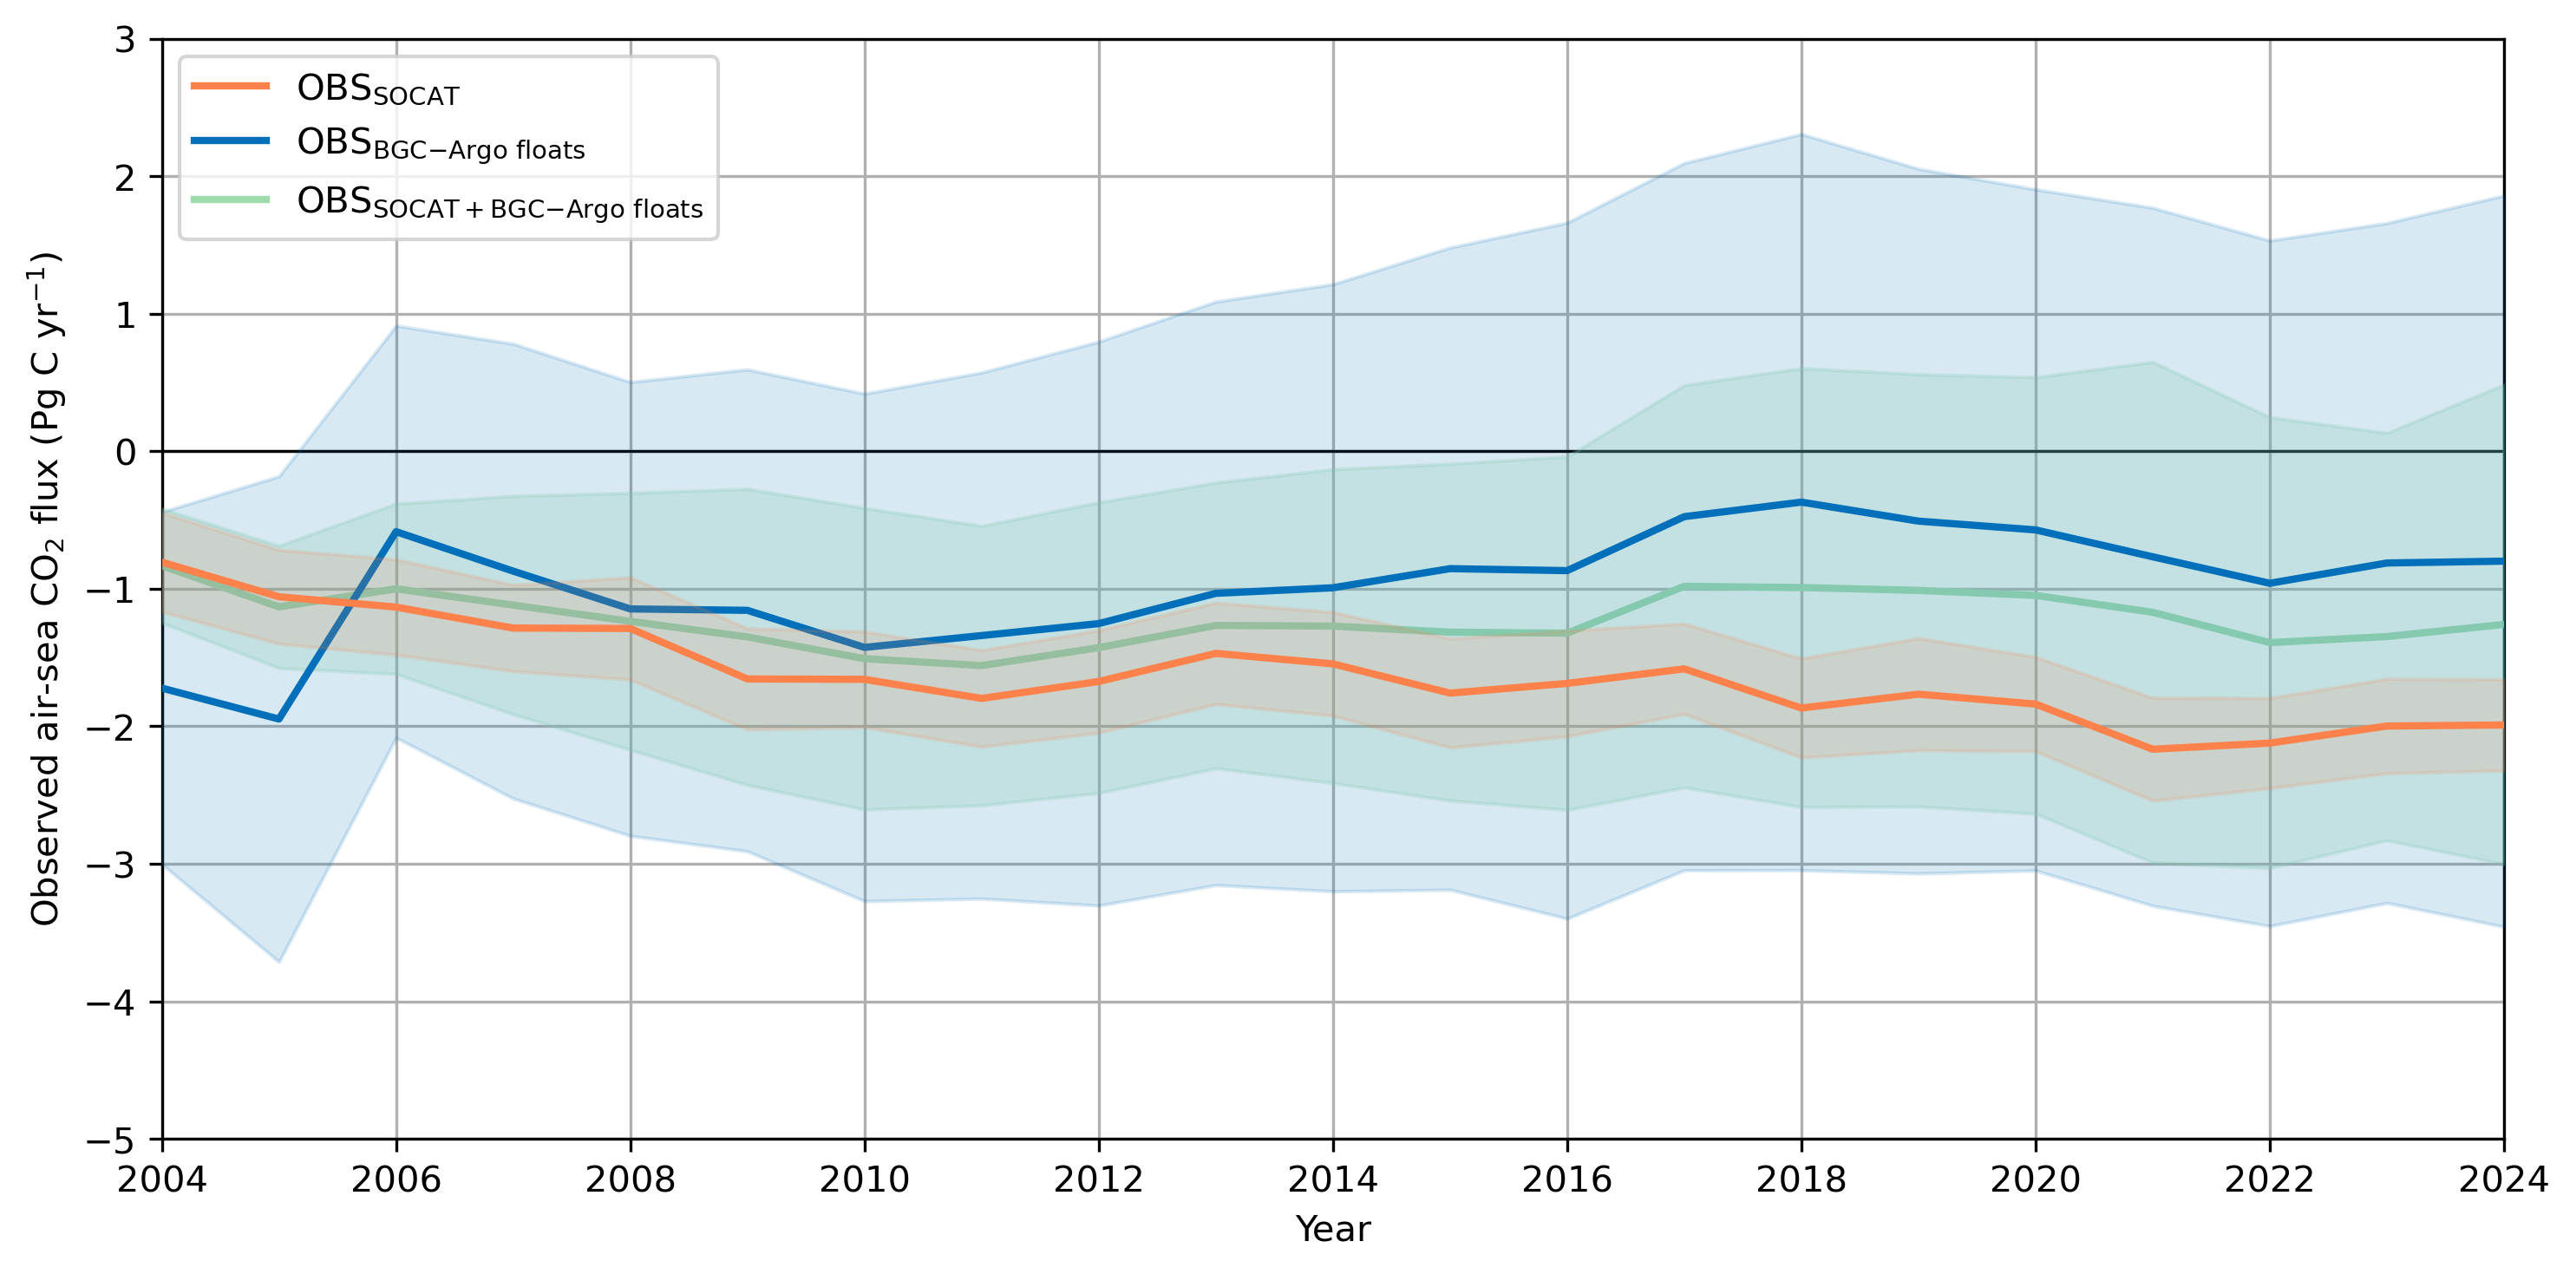

In [68]:
# ============================================================
# Figure 4. Annual air-sea CO2 fluxes with ±1 sigma uncertainty
# SOCAT, BGC-Argo floats, and combined product
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

FIG3_PATH = (
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/figs/"
    "Fig3.png"
)

YLIM = (-5, 3)

OBS_SERIES = [
    {
        "value": "SOCAT",
        "sigma": "SOCAT_sigma_PgC_yr",
        "label": r"OBS$_{\mathrm{SOCAT}}$",
        "plot_label": r"OBS$_{\mathrm{SOCAT}}$",
        "color": "#FC814A",
        "linestyle": "-",
        "alpha": 0.15,
        "zorder": 8,
    },
    {
        "value": "floats",
        "sigma": "floats_sigma_PgC_yr",
        "label": r"OBS$_{\mathrm{BGC{-}Argo\ floats}}$",
        "plot_label": r"OBS$_{\mathrm{BGC{-}Argo\ floats}}$",
        "color": "#016FB9",
        "linestyle": "-",
        "alpha": 0.15,
        "zorder": 6,
    },
    {
        "value": "combined",
        "sigma": "combined_sigma_PgC_yr",
        "label": r"OBS$_{\mathrm{SOCAT+BGC{-}Argo\ floats}}$",
        "plot_label": r"OBS$_{\mathrm{SOCAT+BGC{-}Argo\ floats}}$",
        "color": "#9DDBAD",
        "linestyle": "-",
        "alpha": 0.25,
        "zorder": 4,
    },
]


def add_year_center(df, year_col="year"):
    out = df.copy()
    out["year_center"] = pd.to_datetime(out[year_col].astype(str) + "-07-01")
    return out


def plot_with_uncertainty(ax, df, cfg, lw=2):
    df = df.sort_values("year")
    x = df["year"]
    y = df[cfg["value"]]
    s = df[cfg["sigma"]]

    line, = ax.plot(
        x,
        y,
        color=cfg["color"],
        linestyle=cfg["linestyle"],
        lw=lw,
        zorder=cfg["zorder"],
        label=cfg["plot_label"],
    )

    ax.fill_between(
        x,
        y - s,
        y + s,
        color=cfg["color"],
        alpha=cfg["alpha"],
        zorder=cfg["zorder"] - 1,
    )
    return line


def style_panel(ax, ylabel, panel_label=None, ylim=YLIM, xlabel=None):
    ax.set_ylabel(ylabel)
    if xlabel is not None:
        ax.set_xlabel(xlabel)

    ax.grid(True)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylim(*ylim)

    if panel_label:
        ax.text(
            0,
            1.08,
            panel_label,
            transform=ax.transAxes,
            fontsize=14,
            va="top",
            ha="left",
        )


# ------------------------------------------------------------
# Prepare plotting dataframe
# ------------------------------------------------------------

plot_df = yearly_flux_summary.loc[yearly_flux_summary["year"].between(2004, 2024)].copy()

# annual values plotted at their year; the lines run from 2004 to 2024
xmin, xmax = 2004, 2024

# ------------------------------------------------------------
# Build figure
# ------------------------------------------------------------

fig, ax1 = plt.subplots(
    1,
    1,
    figsize=(10, 5),
    dpi=300,
)

obs_lines = [
    plot_with_uncertainty(ax1, plot_df, cfg)
    for cfg in OBS_SERIES
]

style_panel(
    ax1,
    ylabel="Observed air-sea CO$_2$ flux (Pg C yr$^{-1}$)",
    xlabel="Year",
)

ax1.set_xlim(xmin, xmax)
ax1.set_xticks(range(2004, 2025, 2))

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

handles = [obs_lines[0], obs_lines[1], obs_lines[2]]

labels = [
    OBS_SERIES[0]["label"],
    OBS_SERIES[1]["label"],
    OBS_SERIES[2]["label"],
]

ax1.legend(
    handles,
    labels,
    loc="upper left",
    frameon=True,
)

fig.tight_layout()
fig.savefig(FIG3_PATH, dpi=300, bbox_inches="tight")
plt.show()

### 4.2 Mean seasonal cycle (manuscript Figure 4)

For each calendar month, the mean and standard deviation of the monthly fluxes across years (2004–2024) are computed for the three OBS data sets. The shaded band is this year-to-year standard deviation, not the propagated pCO₂ uncertainty. Seasons are austral: summer = December–February, autumn = March–May, winter = June–August, spring = September–November.

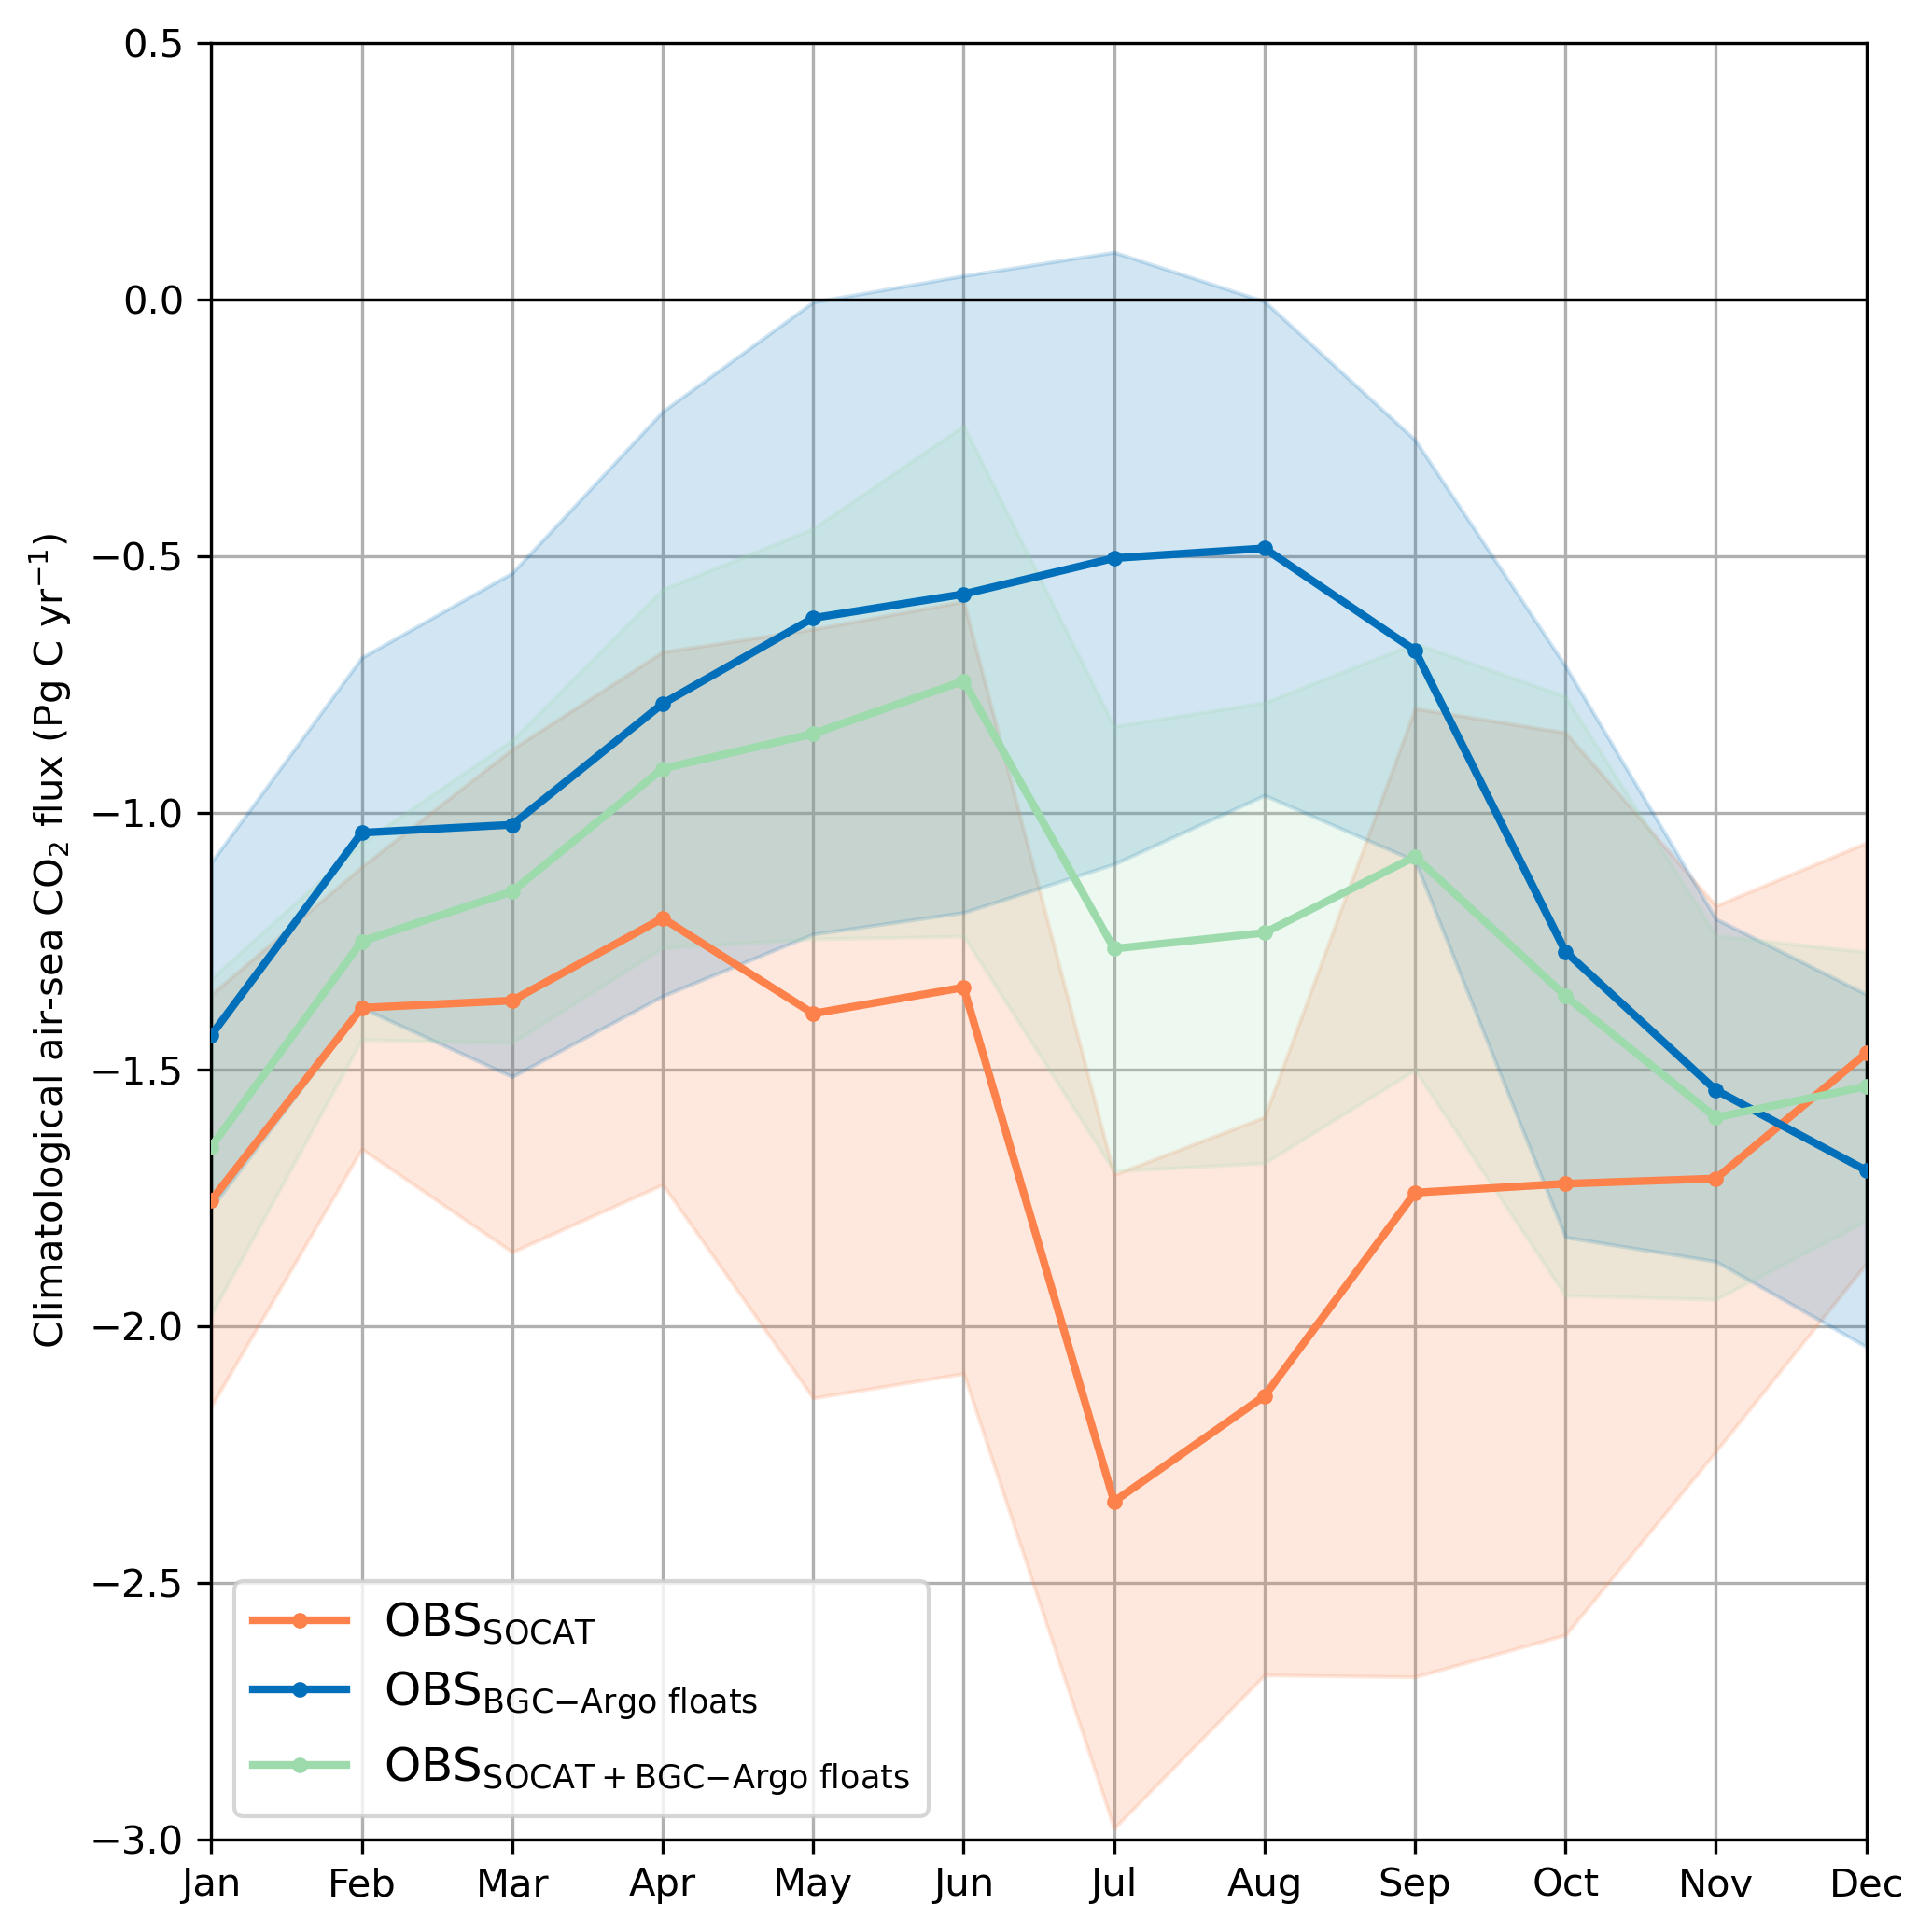

In [53]:
# ============================================================
# Figure 4b. Mean seasonal cycle of monthly air-sea CO2 flux
# SOCAT, BGC-Argo floats, and combined product -- south of 30°S only
#
# X-axis in standard Jan-Dec order. Because austral summer (DJF) spans
# the year boundary, it's drawn as two separate windows -- Jan-Feb and
# Dec -- both shaded/labeled "Summer", rather than one contiguous block.
#
# Band = ±1 standard deviation ACROSS YEARS at each calendar month --
# NOT the per-month flux-calculation (MC) uncertainty from cell 0.
# ============================================================

import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms

YEAR_MIN, YEAR_MAX = 2004, 2024
FIG_SEASONAL_PATH = (
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/figs/"
    "Fig4.png"
)

SERIES = [
    {"value": "SOCAT", "label": r"OBS$_{\mathrm{SOCAT}}$", "color": "#FC814A"},
    {"value": "floats", "label": r"OBS$_{\mathrm{BGC{-}Argo\ floats}}$", "color": "#016FB9"},
    {"value": "combined", "label": r"OBS$_{\mathrm{SOCAT+BGC{-}Argo\ floats}}$", "color": "#9DDBAD"},
]

# Standard Jan -> Dec order
MONTH_ORDER = list(range(1, 13))
MONTH_LABELS = [calendar.month_abbr[m] for m in MONTH_ORDER]

# Summer (DJF) wraps the year boundary, so it's split into two windows
SEASON_WINDOWS = [
    ("Summer", 1, 2),    # Jan, Feb
    ("Autumn", 3, 5),    # Mar, Apr, May
    ("Winter", 6, 8),    # Jun, Jul, Aug
    ("Spring", 9, 11),   # Sep, Oct, Nov
    ("Summer", 12, 12),  # Dec
]


def seasonal_cycle(df, year_min=YEAR_MIN, year_max=YEAR_MAX):
    sub = df.loc[df["year"].between(year_min, year_max)].copy()
    rows = []
    for cfg in SERIES:
        col = cfg["value"]
        g = sub.groupby("month")[col].agg(["mean", "std", "count"])
        g = g.reindex(range(1, 13))
        g["series"] = col
        rows.append(g)
    return pd.concat(rows)


def plot_seasonal_panel(ax, cycle_df):
    x = np.arange(1, 13)

    for cfg in SERIES:
        sub = cycle_df.loc[cycle_df["series"] == cfg["value"]].reindex(MONTH_ORDER)
        mean = sub["mean"].to_numpy()
        std = sub["std"].to_numpy()

        ax.plot(
            x,
            mean,
            color=cfg["color"],
            lw=2,
            marker="o",
            markersize=3,
            label=cfg["label"],
            zorder=3,
        )
        ax.fill_between(
            x,
            mean - std,
            mean + std,
            color=cfg["color"],
            alpha=0.18,
            zorder=2,
        )

    ax.axhline(0, color="k", lw=0.8, zorder=3)
    ax.grid(True, zorder=1)
    ax.set_xticks(x)
    ax.set_xticklabels(MONTH_LABELS)
    ax.set_xlim(1, 12)
    ax.set_ylim(-3, 0.5)

# ------------------------------------------------------------
# Build the seasonal cycle (south of 30°S only)
# ------------------------------------------------------------

cycle_30S = seasonal_cycle(monthly_flux_summary)

n_years = YEAR_MAX - YEAR_MIN + 1
counts_30S = cycle_30S.reset_index().pivot(index="month", columns="series", values="count")
counts_30S.index = [calendar.month_abbr[m] for m in range(1, 13)]

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 7), dpi=300)

plot_seasonal_panel(ax, cycle_30S)

ax.set_ylabel("Climatological air-sea CO$_2$ flux (Pg C yr$^{-1}$)")
ax.legend(loc="lower left", frameon=True, fontsize=12)

fig.tight_layout()
fig.savefig(FIG_SEASONAL_PATH, dpi=300, bbox_inches="tight")
plt.show()

In [54]:
# ============================================================
# Numbers behind Fig. 4: monthly climatological flux, 2004-2024
# (mean ± 1 SD across years, Pg C yr-1, south of 30°S)
# ============================================================
import calendar

_c = cycle_30S.reset_index().rename(columns={"index": "month"})
if "month" not in _c.columns:          # month is the index name in some pandas versions
    _c = cycle_30S.rename_axis("month").reset_index()

mean_tbl = _c.pivot(index="month", columns="series", values="mean")[["SOCAT", "floats", "combined"]]
std_tbl = _c.pivot(index="month", columns="series", values="std")[["SOCAT", "floats", "combined"]]

out = mean_tbl.round(2).astype(str) + " ± " + std_tbl.round(2).astype(str)
out["combined - SOCAT"] = (mean_tbl["combined"] - mean_tbl["SOCAT"]).round(2)
out["floats - SOCAT"] = (mean_tbl["floats"] - mean_tbl["SOCAT"]).round(2)
out.index = [calendar.month_abbr[m] for m in out.index]
print(out.to_string())

print("\nStrongest uptake (most negative) and weakest uptake per series:")
for col in ["SOCAT", "floats", "combined"]:
    s = mean_tbl[col]
    print(f"  {col:9s} strongest: {calendar.month_abbr[s.idxmin()]} ({s.min():.2f})  "
          f"weakest: {calendar.month_abbr[s.idxmax()]} ({s.max():.2f})  "
          f"amplitude: {s.max() - s.min():.2f} Pg C yr-1")

seasons = {"Summer (DJF)": [12, 1, 2], "Autumn (MAM)": [3, 4, 5],
           "Winter (JJA)": [6, 7, 8], "Spring (SON)": [9, 10, 11]}
print("\nSeasonal means (Pg C yr-1):")
print(pd.DataFrame({k: mean_tbl.loc[v].mean() for k, v in seasons.items()}).T.round(2).to_string())

series         SOCAT        floats      combined  combined - SOCAT  floats - SOCAT
Jan      -1.76 ± 0.4  -1.43 ± 0.34  -1.65 ± 0.33              0.10            0.32
Feb     -1.38 ± 0.27  -1.04 ± 0.34  -1.25 ± 0.19              0.13            0.34
Mar     -1.37 ± 0.49  -1.02 ± 0.49  -1.15 ± 0.29              0.21            0.34
Apr     -1.21 ± 0.52  -0.79 ± 0.57  -0.91 ± 0.35              0.29            0.42
May     -1.39 ± 0.75  -0.62 ± 0.62   -0.85 ± 0.4              0.54            0.77
Jun     -1.34 ± 0.75  -0.57 ± 0.62   -0.74 ± 0.5              0.60            0.77
Jul     -2.34 ± 0.64    -0.5 ± 0.6  -1.27 ± 0.43              1.08            1.84
Aug     -2.14 ± 0.54  -0.49 ± 0.48  -1.23 ± 0.45              0.90            1.65
Sep     -1.74 ± 0.94  -0.68 ± 0.41  -1.09 ± 0.42              0.65            1.06
Oct     -1.72 ± 0.88  -1.27 ± 0.56  -1.36 ± 0.58              0.37            0.45
Nov     -1.71 ± 0.53  -1.54 ± 0.33  -1.59 ± 0.35              0.12            0.17
Dec 

### 4.3 Uncertainty of observations vs. reconstructions

For each platform, the annual σ of the OBS estimate is compared with the annual σ of the matching reconstruction. The output gives the median and mean σ and the percentage change from OBS to MODEL. These numbers describe how much the reconstruction narrows (or widens) the uncertainty band relative to the raw observations.

In [55]:
import numpy as np
import pandas as pd

YEAR_MIN, YEAR_MAX = 2004, 2024

SIGMA_PAIRS = {
    "SOCAT: obs → model": (
        "SOCAT_sigma_PgC_yr",
        "SOCAT_predictions_sigma_PgC_yr",
    ),
    "FLOATS: obs → model": (
        "floats_sigma_PgC_yr",
        "floats_predictions_sigma_PgC_yr",
    ),
    "COMBINED (weighted): obs → model": (
        "combined_sigma_PgC_yr",
        "combined_predictions_weighted_sigma_PgC_yr",
    ),
}


def restrict_years(df, year_min=YEAR_MIN, year_max=YEAR_MAX):
    return df.loc[df["year"].between(year_min, year_max)].copy()


def clean_sigma_pair(df, obs_col, model_col):
    out = (
        df[["year", obs_col, model_col]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )
    return out.loc[(out[obs_col] > 0) & (out[model_col] >= 0)].copy()


def summarize_sigma_pair(df, label, obs_col, model_col):
    tmp = clean_sigma_pair(df, obs_col, model_col)

    sigma_obs = tmp[obs_col].to_numpy()
    sigma_mod = tmp[model_col].to_numpy()
    pct_change = 100.0 * (sigma_mod - sigma_obs) / sigma_obs

    return {
        "pair": label,
        "n_years": len(tmp),
        "median_sigma_obs": np.median(sigma_obs),
        "median_sigma_model": np.median(sigma_mod),
        "median_pct_change": np.median(pct_change),
        "mean_sigma_obs": np.mean(sigma_obs),
        "mean_sigma_model": np.mean(sigma_mod),
        "mean_pct_change": np.mean(pct_change),
    }


def build_sigma_summary(df, sigma_pairs):
    rows = [
        summarize_sigma_pair(df, label, obs_col, model_col)
        for label, (obs_col, model_col) in sigma_pairs.items()
    ]
    return pd.DataFrame(rows)


def print_sigma_summary(summary_df, year_min=YEAR_MIN, year_max=YEAR_MAX):
    print(f"\n=== Annual ±1σ envelope comparison ({year_min}–{year_max}) ===\n")

    for _, row in summary_df.iterrows():
        direction = "reduction" if row["median_pct_change"] < 0 else "increase"
        print(
            f"{row['pair']} (n={int(row['n_years'])}): "
            f"median σobs={row['median_sigma_obs']:.2f}, "
            f"median σmodel={row['median_sigma_model']:.2f} Pg C yr⁻¹; "
            f"median change={row['median_pct_change']:+.1f}% ({direction})"
        )

    print("\n--- Full table ---")
    print(summary_df.to_string(index=False))


# ============================================================
# RUN
# ============================================================

analysis_df = restrict_years(yearly_flux_summary, YEAR_MIN, YEAR_MAX)
paper = build_sigma_summary(analysis_df, SIGMA_PAIRS)

print_sigma_summary(paper, YEAR_MIN, YEAR_MAX)


=== Annual ±1σ envelope comparison (2004–2024) ===

SOCAT: obs → model (n=21): median σobs=0.36, median σmodel=0.47 Pg C yr⁻¹; median change=+33.9% (increase)
FLOATS: obs → model (n=21): median σobs=2.21, median σmodel=0.45 Pg C yr⁻¹; median change=-80.4% (reduction)
COMBINED (weighted): obs → model (n=21): median σobs=1.14, median σmodel=0.60 Pg C yr⁻¹; median change=-49.5% (reduction)

--- Full table ---
                            pair  n_years  median_sigma_obs  median_sigma_model  median_pct_change  mean_sigma_obs  mean_sigma_model  mean_pct_change
              SOCAT: obs → model       21          0.359973            0.471736          33.903652        0.358118          0.495076        39.177588
             FLOATS: obs → model       21          2.207210            0.452230         -80.436774        2.144983          0.457842       -77.504316
COMBINED (weighted): obs → model       21          1.141440            0.603835         -49.510826        1.192641          0.610322       

## 5. Global Carbon Budget benchmarks

### 5.1 fCO₂-based products

- The nine GCB fCO₂-based products are read from their individual files.
- The regional flux for the "South" region (index 3, south of 30°S) is extracted.
- Monthly products are averaged to annual means. JENA-MLS is already annual and is used as is.
- No river flux adjustment is added, so the products are compared with the other estimates as net sea–air fluxes.
- The sign is flipped so that negative values mean uptake.
- The ensemble mean is used as the benchmark, and the standard deviation across products as its spread.

In [56]:
import xarray as xr
import numpy as np
import pandas as pd
import glob

path_gcb = "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-OSSE/data/GCB/Ocean/"
fco2_files = sorted(glob.glob(path_gcb + "GCB-2025_dataprod_*.nc"))

south_list = []
product_names = []
bad_files = []

for f in fco2_files:
    try:
        ds = xr.open_dataset(f)

        if "fgco2_reg" not in ds:
            raise ValueError("fgco2_reg missing")

        # SOUTH = region index 3 (<30°S)
        south = ds["fgco2_reg"][:, 3].to_series()

        # =============== FIX FOR JENA-MLS VS MONTHLY PRODUCTS ===============
        if len(south) == len(ds["time"]):
            # Normal monthly product → resample
            south.index = pd.to_datetime(ds["time"].values)
            south_ann = south.resample("YE").mean()
        else:
            # Already annual (e.g. JENA-MLS)
            start_year = int(ds["time"].dt.year.min())
            years = np.arange(start_year, start_year + len(south))
            south_ann = south.copy()
            south_ann.index = pd.to_datetime(years, format="%Y")

        # =============== NO RIVER ADJUSTMENT (FIX 1) ====================
        # The GCB "South" river flux adjustment (+0.09 Pg C yr-1) is NOT
        # applied: our own SOCAT / float / combined fluxes are not
        # river-adjusted, and the inversions are used as
        # ocean_flux_NOT_adjusted, so the products are compared on the same
        # net (contemporary) flux basis.

        # =============== CONVERT TO SIGN CONVENTION ====================
        south_ann = -south_ann        # NEGATIVE = sink

        # =============== RESTRICT TO ANALYSIS PERIOD ===================
        south_ann = south_ann[
            (south_ann.index.year >= 2004) &
            (south_ann.index.year <= 2024)
        ]

        south_list.append(south_ann.values)
        product_names.append(ds.attrs.get("model_name", f.split("/")[-1]))

        print("Loaded:", f.split("/")[-1])

    except Exception as e:
        print("FAILED:", f.split("/")[-1])
        print("   Reason:", str(e))
        bad_files.append(f)

# ===================== BUILD FINAL DATASET =====================

years = south_ann.index.year

fco2_ds = xr.Dataset(
    data_vars=dict(
        fgco2_products=(["product", "year"], np.vstack(south_list))
    ),
    coords=dict(
        product=("product", product_names),
        year=("year", years)
    ),
    attrs=dict(
        description="GCB 2025 fCO2-based products, South <30°S, annual mean",
        time_period="2004–2024",
        units="Pg C yr-1",
        sign_convention="Negative = ocean CO2 sink",
        river_correction_applied="none (unadjusted net sea-air flux, consistent with this study's estimates)"
    )
)

print("\nFINAL DATASET READY")
print("Products:", len(product_names))
print("Years:", years[0], "→", years[-1])
print("Failed files:", bad_files)

Loaded: GCB-2025_dataprod_CMEMS-LSCE-FFNN_1990-2024.nc
Loaded: GCB-2025_dataprod_CSIR-ML6_1982-2024.nc
Loaded: GCB-2025_dataprod_JENA-MLS_1957-2024_v2.nc
Loaded: GCB-2025_dataprod_JMA-MLR_1985-2024_v2.nc
Loaded: GCB-2025_dataprod_LDEO-HPD_1959-2024.nc
Loaded: GCB-2025_dataprod_NIES-ML3_1982-2024.nc
Loaded: GCB-2025_dataprod_OceanSODA-ETHZv2_1982-2024.nc
Loaded: GCB-2025_dataprod_UExP-FNN-U_1980-2024_v2.nc
Loaded: GCB-2025_dataprod_VLIZ-SOMFFN_1982-2024.nc

FINAL DATASET READY
Products: 9
Years: 2004 → 2024
Failed files: []


### 5.2 Global ocean biogeochemical models (simulation A)

- The regional "South" flux (south of 30°S) is extracted for every model for 2004–2024.
- The sign is flipped so that negative values mean uptake.
- The ensemble mean and standard deviation across models are stored, together with the individual model series (`gobm_all`).
- GOBMs do not simulate riverine carbon, so they are not strictly equivalent to net sea–air fluxes.

In [57]:
gobm_file = "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-OSSE/data/GCB/Ocean/GCB2025_GOBMs_fgco2_timeseries_1959_2024.nc"
ds = xr.open_dataset(gobm_file)

# Extract actual year coordinate
year_vals = ds["years"].values   # shape (66,), values 1959..2024

# Add these as a coordinate to fgco2_A_regional
regA = ds["fgco2_A_regional"].assign_coords(year=("year", year_vals))

# Select South region
south = regA.sel(regions="South")   # dims: (models, year)

# Restrict to 2004–2024 using YEAR VALUES (not indices)
south = south.sel(year=slice(2004, 2024))

# Apply sign convention (negative = sink)
south = -south

# Compute ensemble mean + std
gobm_mean = south.mean("models")
gobm_std  = south.std("models")

# Build final dataset
gobm_ds = xr.Dataset(
    data_vars=dict(
        gobm_mean=("year", gobm_mean.values),
        gobm_std=("year", gobm_std.values),
        gobm_all=(["model", "year"], south.values)
    ),
    coords=dict(
        year=south.year.values,
        model=south.models.values
    ),
    attrs=dict(
        description="GCB2025 GOBM ensemble (Simulation A), South <30°S",
        period="2004–2024",
        units="Pg C yr-1",
        sign_convention="Negative = ocean CO2 sink"
    )
)

### 5.3 Atmospheric inversions

1. The ocean flux **without** river adjustment (`ocean_flux_NOT_adjusted`, Pg C m⁻² yr⁻¹, monthly) is read for each inversion.
2. Monthly flux × cell area × (days in month / 365.25) gives Pg C per month. These are summed over cells south of 30°S and over the 12 months to give Pg C yr⁻¹.
3. Inversions start in different years. A member is counted from the first year in which its regional flux exceeds 0.05 Pg C yr⁻¹ in absolute value. Earlier years are masked.
4. The ensemble mean and standard deviation are computed each year from the members active in that year (6 members in 2004–2009, 8 in 2010–2014, 14 from 2015).


Ensemble members:
 0  CarboScope
 1  NISMON-CO2
 2  CT-NOAA
 3  CTE
 4  MIROC
 5  UoE
 6  NISMON-CO2_GOSAT
 7  NTFVAR
 8  CAMS-Satellite
 9  CMS-Flux
10  COLA
11  GCASv2
12  GONGGA
13  THU

Detected start year per member (eps = 0.050 PgC/yr):
 0  CarboScope                 start_year=1976
 1  NISMON-CO2                 start_year=1990
 2  CT-NOAA                    start_year=2000
 3  CTE                        start_year=2001
 4  MIROC                      start_year=2001
 5  UoE                        start_year=2001
 6  NISMON-CO2_GOSAT           start_year=2010
 7  NTFVAR                     start_year=2010
 8  CAMS-Satellite             start_year=2015
 9  CMS-Flux                   start_year=2015
10  COLA                       start_year=2015
11  GCASv2                     start_year=2015
12  GONGGA                     start_year=2015
13  THU                        start_year=2015

Members contributing by year (after masking):
2004: 6
2005: 6
2006: 6
2007: 6
2008: 6
2009: 6
201

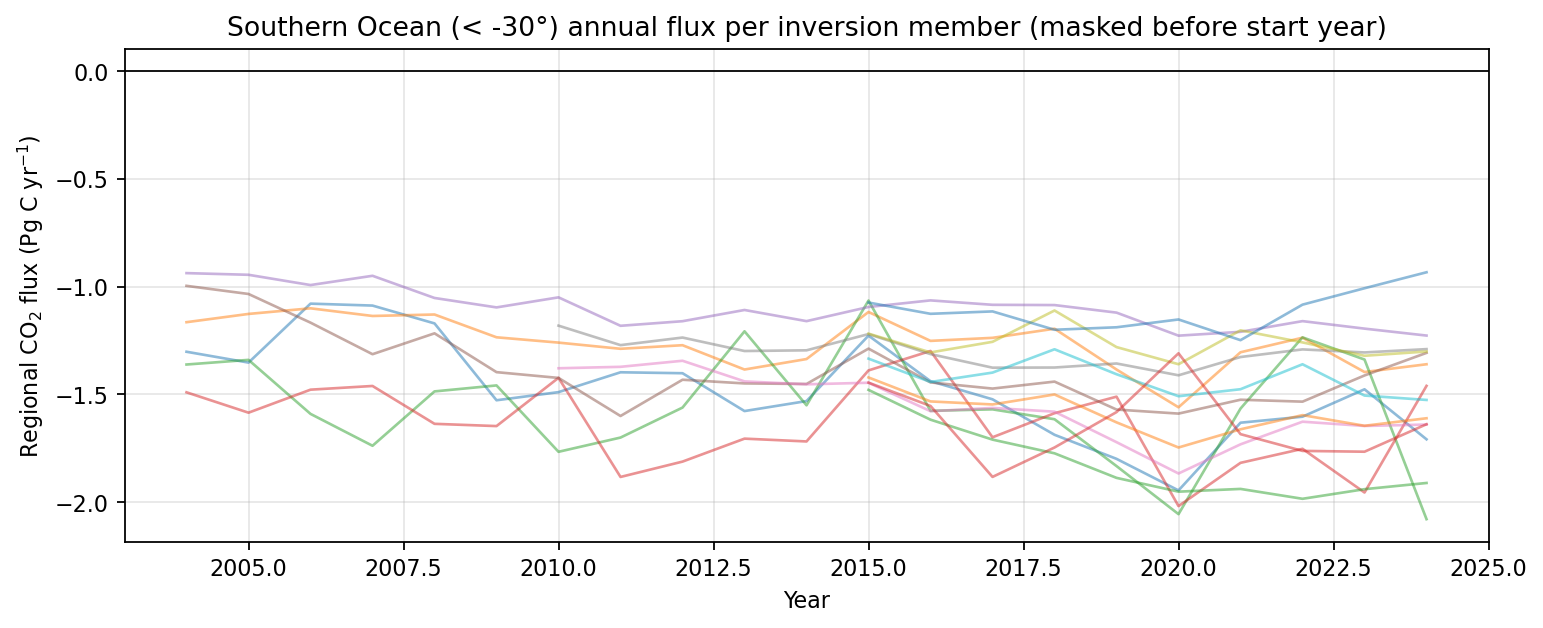

/tmp/ipykernel_3271598/3536058863.py:159: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="best")


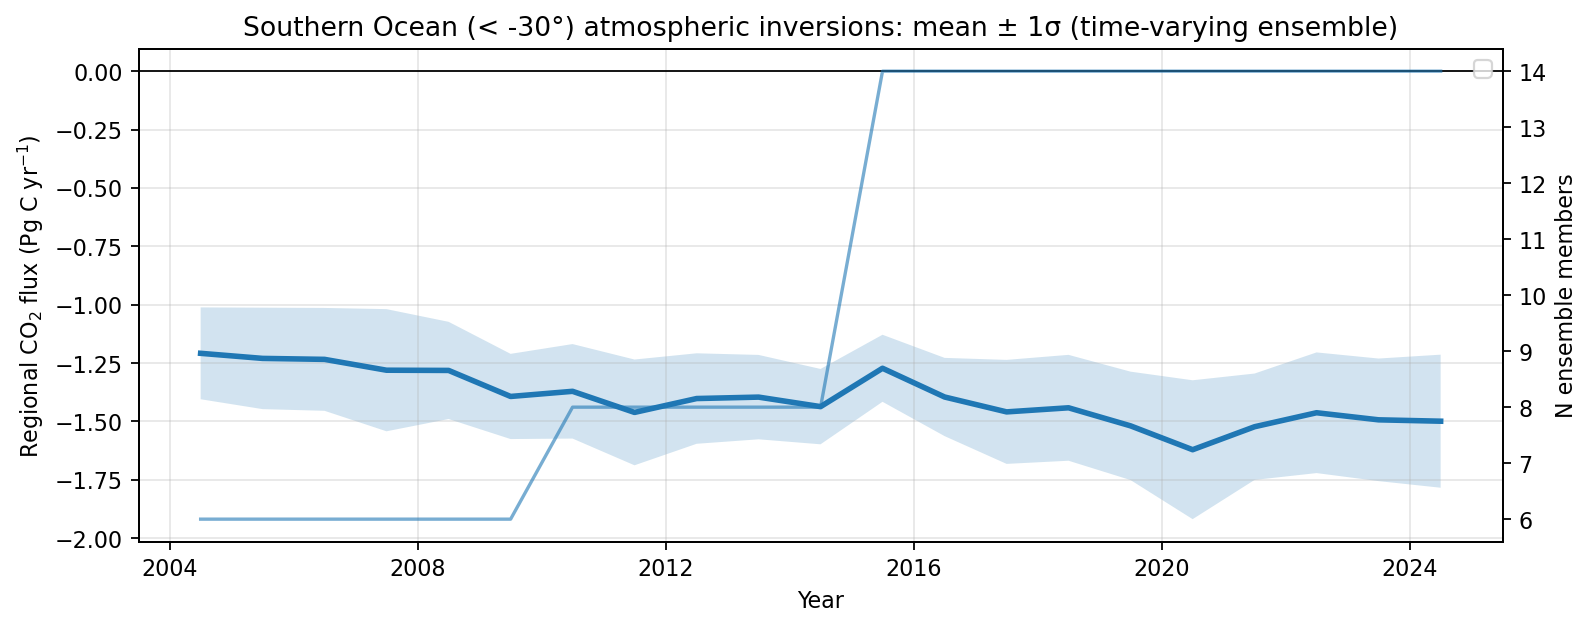


Ready for plotting:
inv_years shape: (21,)
inv_mean shape : (21,)
inv_std shape  : (21,)


In [58]:
# ============================================================
# GCB2025 Atmospheric inversions: Southern Ocean (< -30°S)
# Annual regional flux in PgC/yr, with a time-varying ensemble:
# each inversion member is included only from its first "active"
# year onward (detected from non-zero regional annual flux).
#
# Output sign convention: whatever the file provides.
# (For "uptake positive", flip sign at the end.)
# NO river adjustment applied to atmospheric inversions.
# ============================================================

import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------
# 1) Load dataset
# ----------------------------
inv_file = (
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-OSSE/data/GCB/Atmosphere/"
    "GCP2025_inversions_1x1_version1_0_20251031.nc"
)

ds = xr.open_dataset(inv_file, engine="h5netcdf")

# ----------------------------
# 2) Define region mask: lat < -30
# ----------------------------
mask_south = ds["latitude"] < -30

# ----------------------------
# 3) Convert monthly flux rate -> monthly PgC
#    f is [PgC m-2 yr-1] at monthly resolution
#    monthly PgC = f * area * (days_in_month / 365.25)
# ----------------------------
f = ds["ocean_flux_NOT_adjusted"]                  # (ensemble_member, time, lat, lon)
A = ds["cell_area"]                               # (lat, lon)
days = ds["time"].dt.days_in_month                # (time,)

f_month_PgC = f * A * (days / 365.25)

# ----------------------------
# 4) Integrate over region -> PgC/month
# ----------------------------
south_month_PgC = f_month_PgC.where(mask_south).sum(
    dim=("latitude", "longitude"),
    skipna=True
)

# ----------------------------
# 5) Aggregate to annual PgC/yr
# ----------------------------
south_annual_PgCyr = south_month_PgC.groupby("time.year").sum("time")
south_annual_PgCyr = south_annual_PgCyr.rename({"year": "year"})  # explicit

# ----------------------------
# 6) Decode inversion member names (optional but useful)
# ----------------------------
member_names = [
    "".join(ds["ensemble_member_name"].sel(ensemble_member=i).values)
    for i in ds["ensemble_member"].values
]
print("\nEnsemble members:")
for i, n in enumerate(member_names):
    print(f"{i:2d}  {n}")

# ----------------------------
# 7) Time-varying ensemble inclusion:
#    For each member, find first year when |annual flux| > eps.
#    Mask that member before that year, then compute mean/std.
# ----------------------------
eps = 0.05  # PgC/yr threshold to detect "active" (tune if needed)

member_ann = south_annual_PgCyr  # (ensemble_member, year)

active = np.abs(member_ann) > eps  # True where member-year is "active"

# idxmax gives first coordinate of max (True > False); but if all False,
# idxmax returns the first year, so we must guard against "never active".
any_active = active.any(dim="year")

start_year = active.where(active).idxmax(dim="year")
start_year = start_year.where(any_active)  # members never active -> NaN

# Mask values prior to each member's start year
member_masked = member_ann.where(member_ann["year"] >= start_year)

# Ensemble stats ignoring NaNs
ens_mean = member_masked.mean("ensemble_member", skipna=True)
ens_std  = member_masked.std("ensemble_member", skipna=True)

# Number of contributing members each year
n_members = member_masked.notnull().sum("ensemble_member")

# ----------------------------
# 8) Restrict to comparison period
# ----------------------------
year_min, year_max = 2004, 2024
ens_mean = ens_mean.sel(year=slice(year_min, year_max))
ens_std  = ens_std.sel(year=slice(year_min, year_max))
n_members = n_members.sel(year=slice(year_min, year_max))

member_masked_period = member_masked.sel(year=slice(year_min, year_max))

# ----------------------------
# 9) Diagnostics: print start years and contributing count
# ----------------------------
print("\nDetected start year per member (eps = %.3f PgC/yr):" % eps)
for i, (n, y) in enumerate(zip(member_names, start_year.values)):
    y_str = "None" if np.isnan(y) else str(int(y))
    print(f"{i:2d}  {n:25s}  start_year={y_str}")

print("\nMembers contributing by year (after masking):")
for y, nm in zip(n_members["year"].values, n_members.values):
    print(f"{int(y)}: {int(nm)}")

# ----------------------------
# 10) Plot: (a) per-member (masked) (b) ensemble mean +/- 1σ
# ----------------------------
time = pd.to_datetime(ens_mean["year"].values.astype(str) + "-07-01")

plt.figure(figsize=(11, 4), dpi=160)
for i in member_masked_period["ensemble_member"].values:
    plt.plot(
        member_masked_period["year"].values,
        member_masked_period.sel(ensemble_member=i).values,
        alpha=0.5,
        lw=1.2
    )
plt.axhline(0, color="k", lw=0.8)
plt.title("Southern Ocean (< -30°) annual flux per inversion member (masked before start year)")
plt.xlabel("Year")
plt.ylabel("Regional CO$_2$ flux (Pg C yr$^{-1}$)")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(11, 4), dpi=160)
plt.plot(time, ens_mean.values, lw=2.5, label="Inversion ensemble mean")
plt.fill_between(
    time,
    (ens_mean - ens_std).values,
    (ens_mean + ens_std).values,
    alpha=0.2,
    label=r"$\pm 1\sigma$"
)
plt.axhline(0, color="k", lw=0.8)
plt.title("Southern Ocean (< -30°) atmospheric inversions: mean ± 1σ (time-varying ensemble)")
plt.xlabel("Year")
plt.ylabel("Regional CO$_2$ flux (Pg C yr$^{-1}$)")
plt.grid(True, alpha=0.3)

# Optional: show number of contributing members on a secondary axis
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(time, n_members.values, lw=1.5, alpha=0.6)
ax2.set_ylabel("N ensemble members")

plt.legend(loc="best")
plt.show()

# ----------------------------
# 11) Final outputs for main figure
# ----------------------------
# ens_mean: (year,) annual PgC/yr
# ens_std : (year,) annual PgC/yr
# n_members: (year,) number of active members
#
# Convert to arrays if needed:
inv_years = ens_mean["year"].values
inv_mean = ens_mean.values
inv_std  = ens_std.values

print("\nReady for plotting:")
print("inv_years shape:", inv_years.shape)
print("inv_mean shape :", inv_mean.shape)
print("inv_std shape  :", inv_std.shape)

In [59]:
# ============================================================
# GCB2025 products used in each benchmark ensemble
# (south of 30°S, 2004–2024; negative = ocean sink)
# ============================================================
def _name(x):
    """Decode bytes / char arrays from netCDF into a clean string."""
    if isinstance(x, (bytes, np.bytes_)):
        x = x.decode()
    return str(x).strip()

def _report(title, names, values):
    """Print each member's 2004–2024 mean flux, then the ensemble summary."""
    names = [_name(n) for n in names]
    means = np.nanmean(values, axis=1)          # (member,) mean over years
    order = np.argsort(means)                   # strongest sink first
    print(f"\n=== {title}: {len(names)} members ===")
    for i in order:
        n_years = int(np.isfinite(values[i]).sum())
        print(f"  {names[i]:<30s} {means[i]:+.2f} Pg C yr-1  ({n_years} yr)")
    print(f"  {'Ensemble mean':<30s} {np.nanmean(means):+.2f} Pg C yr-1")
    print(f"  {'Range of members':<30s} {means.min():+.2f} to {means.max():+.2f} Pg C yr-1")

# --- fCO2-based products ---
_report(
    "GCB2025 fCO2-based products",
    fco2_ds["product"].values,
    fco2_ds["fgco2_products"].values,
)

# --- GOBMs (Simulation A) ---
_report(
    "GCB2025 GOBMs (Sim A)",
    gobm_ds["model"].values,
    gobm_ds["gobm_all"].values,
)

# --- Atmospheric inversions (members masked before their first active year) ---
inv_sel = member_masked.sel(year=slice(2004, 2024))
inv_vals = inv_sel.transpose("ensemble_member", "year").values
inv_active = np.isfinite(inv_vals).any(axis=1)        # members with ≥1 year in 2004–2024
_report(
    "GCB2025 atmospheric inversions",
    np.array(member_names)[inv_active],
    inv_vals[inv_active],
)
excluded = [n for n, a in zip(member_names, inv_active) if not a]
if excluded:
    print("  Not used in 2004–2024 (never active):", ", ".join(excluded))
n_per_year = np.isfinite(inv_vals).sum(axis=0)
print(f"  Members contributing per year: {n_per_year.min()}–{n_per_year.max()}")


=== GCB2025 fCO2-based products: 9 members ===
  JMA-MLR_1985-2024_v2           -1.65 Pg C yr-1  (21 yr)
  CSIR-ML6_1982-2024             -1.54 Pg C yr-1  (21 yr)
  UExP-FNN-U_1980-2024_v2        -1.50 Pg C yr-1  (21 yr)
  JENA-MLS_1957-2024             -1.48 Pg C yr-1  (21 yr)
  VLIZ-SOMFFN_1982-2024          -1.39 Pg C yr-1  (21 yr)
  NIES-ML3_1982-2024             -1.38 Pg C yr-1  (21 yr)
  OceanSODA-ETHZv2_1982-2024     -1.35 Pg C yr-1  (21 yr)
  LDEO-HPD_1959-2024             -1.29 Pg C yr-1  (21 yr)
  CMEMS-LSCE-FFNN_1990-2024      -1.25 Pg C yr-1  (21 yr)
  Ensemble mean                  -1.43 Pg C yr-1
  Range of members               -1.65 to -1.25 Pg C yr-1

=== GCB2025 GOBMs (Sim A): 9 members ===
  ACCESS                         -1.87 Pg C yr-1  (21 yr)
  NorESM                         -1.84 Pg C yr-1  (21 yr)
  FESOM                          -1.78 Pg C yr-1  (21 yr)
  MRI                            -1.31 Pg C yr-1  (21 yr)
  PlankTOM                       -1.25 Pg C yr-1 

## 6. Reconstructions compared with the Global Carbon Budget

### 6.1 Annual fluxes (manuscript Figure 5)

Annual fluxes south of 30°S from the three reconstructions (dashed) and the three GCB benchmarks (solid). Shaded bands: ±1σ propagated uncertainty for the reconstructions; spread across products, models or inversion members for the GCB estimates.


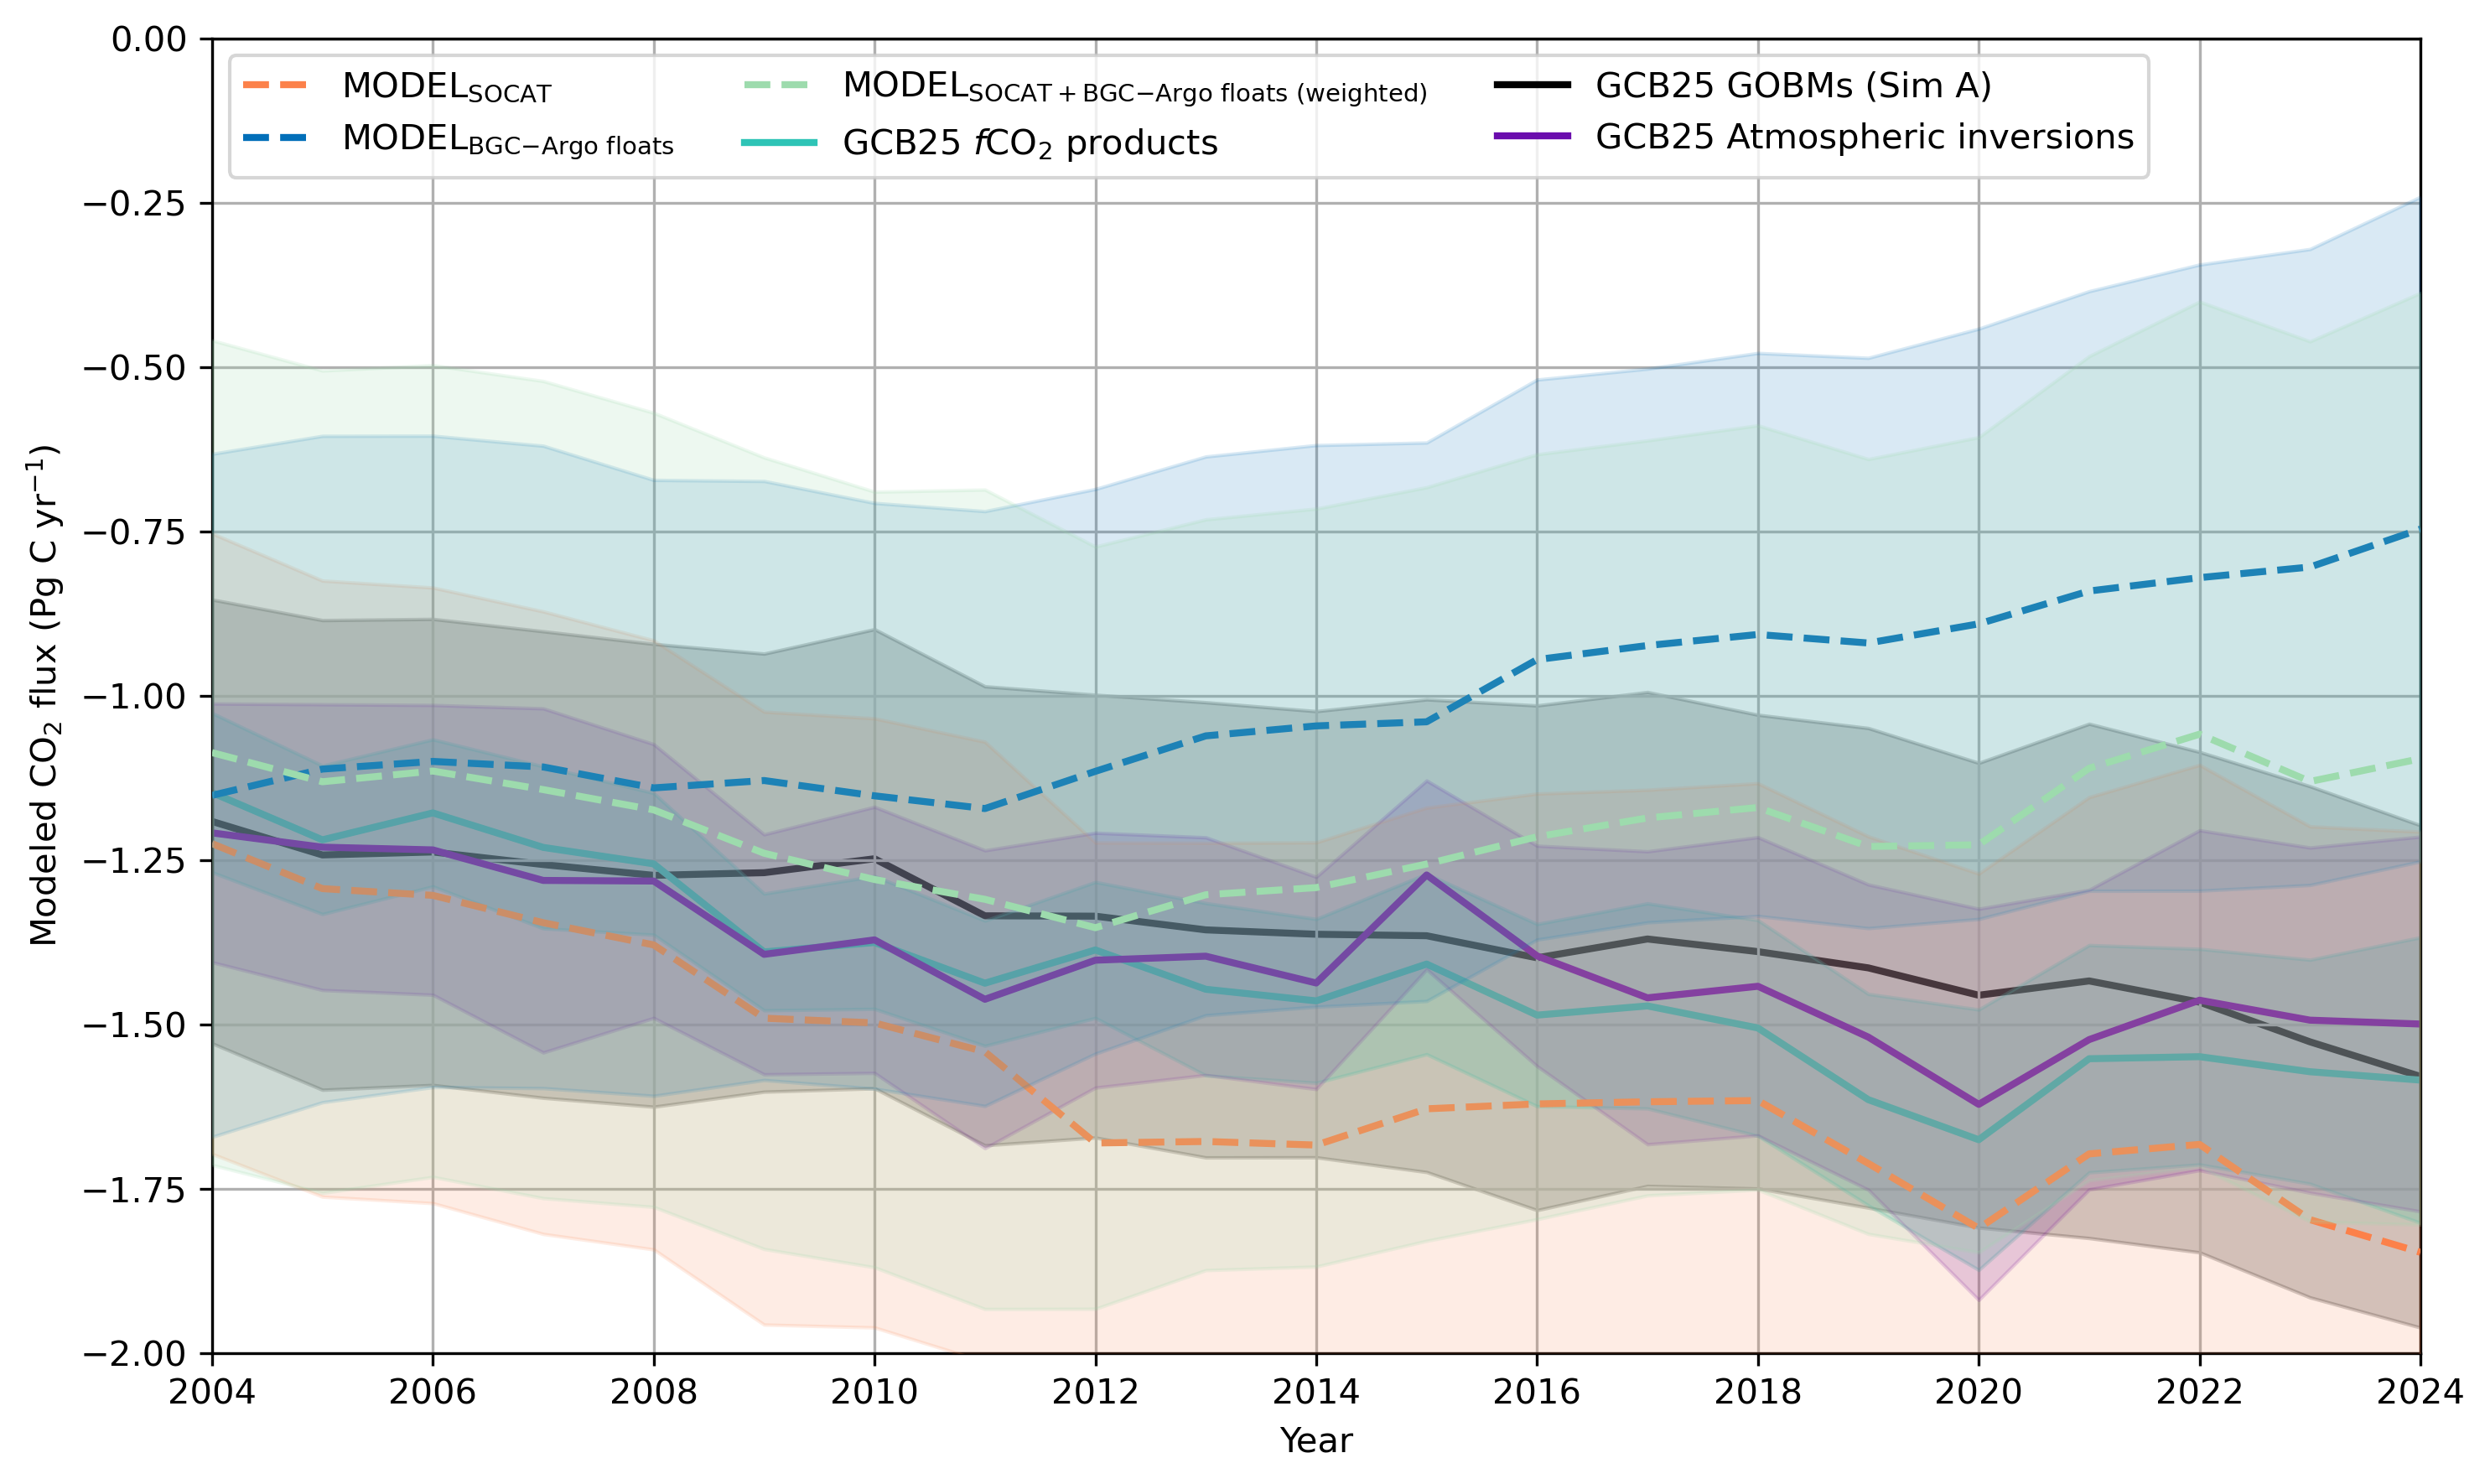

In [60]:
# ============================================================
# Figure X. Model comparison with GCB25 products, GOBMs, and inversions
# Assumes already available:
#   - ens_mean, ens_std
#   - fco2_ds
#   - gobm_ds
#   - yearly_flux_summary
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

YEAR_MIN, YEAR_MAX = 2004, 2024
FIG_PATH = (
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/figs/"
    "Fig5.png"
)
YLIM = (-2, 0.0)


def year_to_datetime(year_values):
    return pd.to_datetime(pd.Index(year_values).astype(str) + "-07-01")


def plot_with_band(ax, years, y, sigma, *, label, color, linestyle="-", lw=2, alpha=0.15, zorder=1):
    years = np.asarray(years).astype(int)
    order = np.argsort(years)
    years, y, sigma = years[order], np.asarray(y, float)[order], np.asarray(sigma, float)[order]
    line, = ax.plot(
        years,
        y,
        color=color,
        linestyle=linestyle,
        lw=lw,
        zorder=zorder,
        label=label,
    )
    ax.fill_between(
        years,
        y - sigma,
        y + sigma,
        color=color,
        alpha=alpha,
        zorder=zorder,
    )
    return line


# ------------------------------------------------------------
# Prepare datasets
# ------------------------------------------------------------

plot_df = yearly_flux_summary.loc[
    yearly_flux_summary["year"].between(YEAR_MIN, YEAR_MAX)
].copy()

ens_mean_plot = ens_mean.sel(year=slice(YEAR_MIN, YEAR_MAX))
ens_std_plot = ens_std.sel(year=slice(YEAR_MIN, YEAR_MAX))

years_inv = ens_mean_plot["year"].values
inv_mean = ens_mean_plot.values
inv_std = ens_std_plot.values

fco2_plot = fco2_ds.sel(year=slice(YEAR_MIN, YEAR_MAX))
years_gcb = fco2_plot["year"].values
fco2_mean = fco2_plot["fgco2_products"].mean("product").values
fco2_std = fco2_plot["fgco2_products"].std("product").values

gobm_plot = gobm_ds.sel(year=slice(YEAR_MIN, YEAR_MAX))
years_gobm = gobm_plot["year"].values
gobm_mean = gobm_plot["gobm_mean"].values
gobm_std = gobm_plot["gobm_std"].values

# ------------------------------------------------------------
# Series configuration
# ------------------------------------------------------------

MODEL_SERIES = [
    {
        "x": plot_df["year"].to_numpy(),
        "y": plot_df["SOCAT_predictions"].to_numpy(),
        "sigma": plot_df["SOCAT_predictions_sigma_PgC_yr"].to_numpy(),
        "label": r"MODEL$_{\mathrm{SOCAT}}$",
        "color": "#FC814A",
        "linestyle": "--",
        "alpha": 0.15,
        "zorder": 3,
    },
    {
        "x": plot_df["year"].to_numpy(),
        "y": plot_df["floats_predictions"].to_numpy(),
        "sigma": plot_df["floats_predictions_sigma_PgC_yr"].to_numpy(),
        "label": r"MODEL$_{\mathrm{BGC{-}Argo\ floats}}$",
        "color": "#016FB9",
        "linestyle": "--",
        "alpha": 0.15,
        "zorder": 4,
    },
    {
        "x": plot_df["year"].to_numpy(),
        "y": plot_df["combined_predictions_weighted"].to_numpy(),
        "sigma": plot_df["combined_predictions_weighted_sigma_PgC_yr"].to_numpy(),
        "label": r"MODEL$_{\mathrm{SOCAT+BGC{-}Argo\ floats\ (weighted)}}$",
        "color": "#9DDBAD",
        "linestyle": "--",
        "alpha": 0.18,
        "zorder": 5,
    },
    {
        "x": years_gcb,
        "y": fco2_mean,
        "sigma": fco2_std,
        "label": r"GCB25 $f\mathrm{CO}_2$ products",
        "color": "#2EC4B6",
        "linestyle": "-",
        "alpha": 0.25,
        "zorder": 2,
    },
    {
        "x": years_gobm,
        "y": gobm_mean,
        "sigma": gobm_std,
        "label": "GCB25 GOBMs (Sim A)",
        "color": "black",
        "linestyle": "-",
        "alpha": 0.2,
        "zorder": 1,
    },
    {
        "x": years_inv,
        "y": inv_mean,
        "sigma": inv_std,
        "label": "GCB25 Atmospheric inversions",
        "color": "#6A0DAD",
        "linestyle": "-",
        "alpha": 0.18,
        "zorder": 2,
    },
]

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

for cfg in MODEL_SERIES:
    plot_with_band(
        ax,
        cfg["x"],
        cfg["y"],
        cfg["sigma"],
        label=cfg["label"],
        color=cfg["color"],
        linestyle=cfg["linestyle"],
        alpha=cfg["alpha"],
        zorder=cfg["zorder"],
    )

ax.set_xlabel("Year")
ax.set_ylabel("Modeled CO$_2$ flux (Pg C yr$^{-1}$)")
ax.grid(True)
ax.axhline(0, color="k", lw=0.8)

# annual values plotted at their year; the lines run from 2004 to 2024
ax.set_xlim(YEAR_MIN, YEAR_MAX)
ax.set_xticks(range(YEAR_MIN, YEAR_MAX + 1, 2))
ax.set_ylim(*YLIM)

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles,
    labels,
    loc="upper left",
    frameon=True,
    ncols=3
)

fig.tight_layout()
fig.savefig(FIG_PATH, dpi=300, bbox_inches="tight")
plt.show()

### 6.2 Multi-year mean fluxes (manuscript Figure 6 and Table S2)

**Mean.** The 2004–2024 mean is the average of the 21 annual fluxes.

**Uncertainty of the mean (Monte Carlo).** For each data set, 200,000 sets of 21 annual fluxes are drawn, each year from a normal distribution with that year's flux and σ. The mean of each set is computed. The standard deviation of these 200,000 means is σ_mean, and their 2.5th–97.5th percentiles form the 95% confidence interval.

- Years are drawn independently, so random year-to-year errors partly cancel (σ_mean ≈ annual σ / √21). Errors that are the same every year would not cancel, so σ_mean is a lower bound.
- For the GCB rows, the annual σ is the spread across products, models or inversion members, not a measurement uncertainty.

**Significance.** A mean sink is considered significant when the whole 95% interval is below zero. P(mean < 0) is the fraction of Monte Carlo means below zero.

**Ranges.** Min–max of the 2004–2024 mean across individual fCO₂ products, across individual GOBMs, and across the inversion members that cover the full period. These ranges are printed for Table S2 but not drawn in the figure.

Bars show the means and black whiskers show ±σ_mean.

Inversion min-max range based on 6 full-period members

=== Table S2. Significance of multi-year mean Southern Ocean CO2 flux (2004–2024, south of 30°S) ===
Reported as mean ± σ_mean, with 95% CI from Monte Carlo propagation of annual uncertainties.

OBS$_{\mathrm{SOCAT}}$
  mean ± σ_mean = -1.63 ± 0.08 Pg C yr⁻¹
  95% CI        = -1.78 to -1.47 Pg C yr⁻¹
  P(mean < 0)   = 1.0000
  Significant sink? YES

MODEL$_{\mathrm{SOCAT}}$
  mean ± σ_mean = -1.58 ± 0.11 Pg C yr⁻¹
  95% CI        = -1.79 to -1.36 Pg C yr⁻¹
  P(mean < 0)   = 1.0000
  Significant sink? YES

OBS$_{\mathrm{BGC{-}Argo\ floats}}$
  mean ± σ_mean = -0.97 ± 0.48 Pg C yr⁻¹
  95% CI        = -1.91 to -0.04 Pg C yr⁻¹
  P(mean < 0)   = 0.9792
  Significant sink? YES

MODEL$_{\mathrm{BGC{-}Argo\ floats}}$
  mean ± σ_mean = -1.01 ± 0.10 Pg C yr⁻¹
  95% CI        = -1.20 to -0.81 Pg C yr⁻¹
  P(mean < 0)   = 1.0000
  Significant sink? YES

OBS$_{\mathrm{SOCAT+BGC{-}Argo\ floats}}$
  mean ± σ_mean = -1.22 ± 0.27 Pg C yr⁻¹
  95% CI

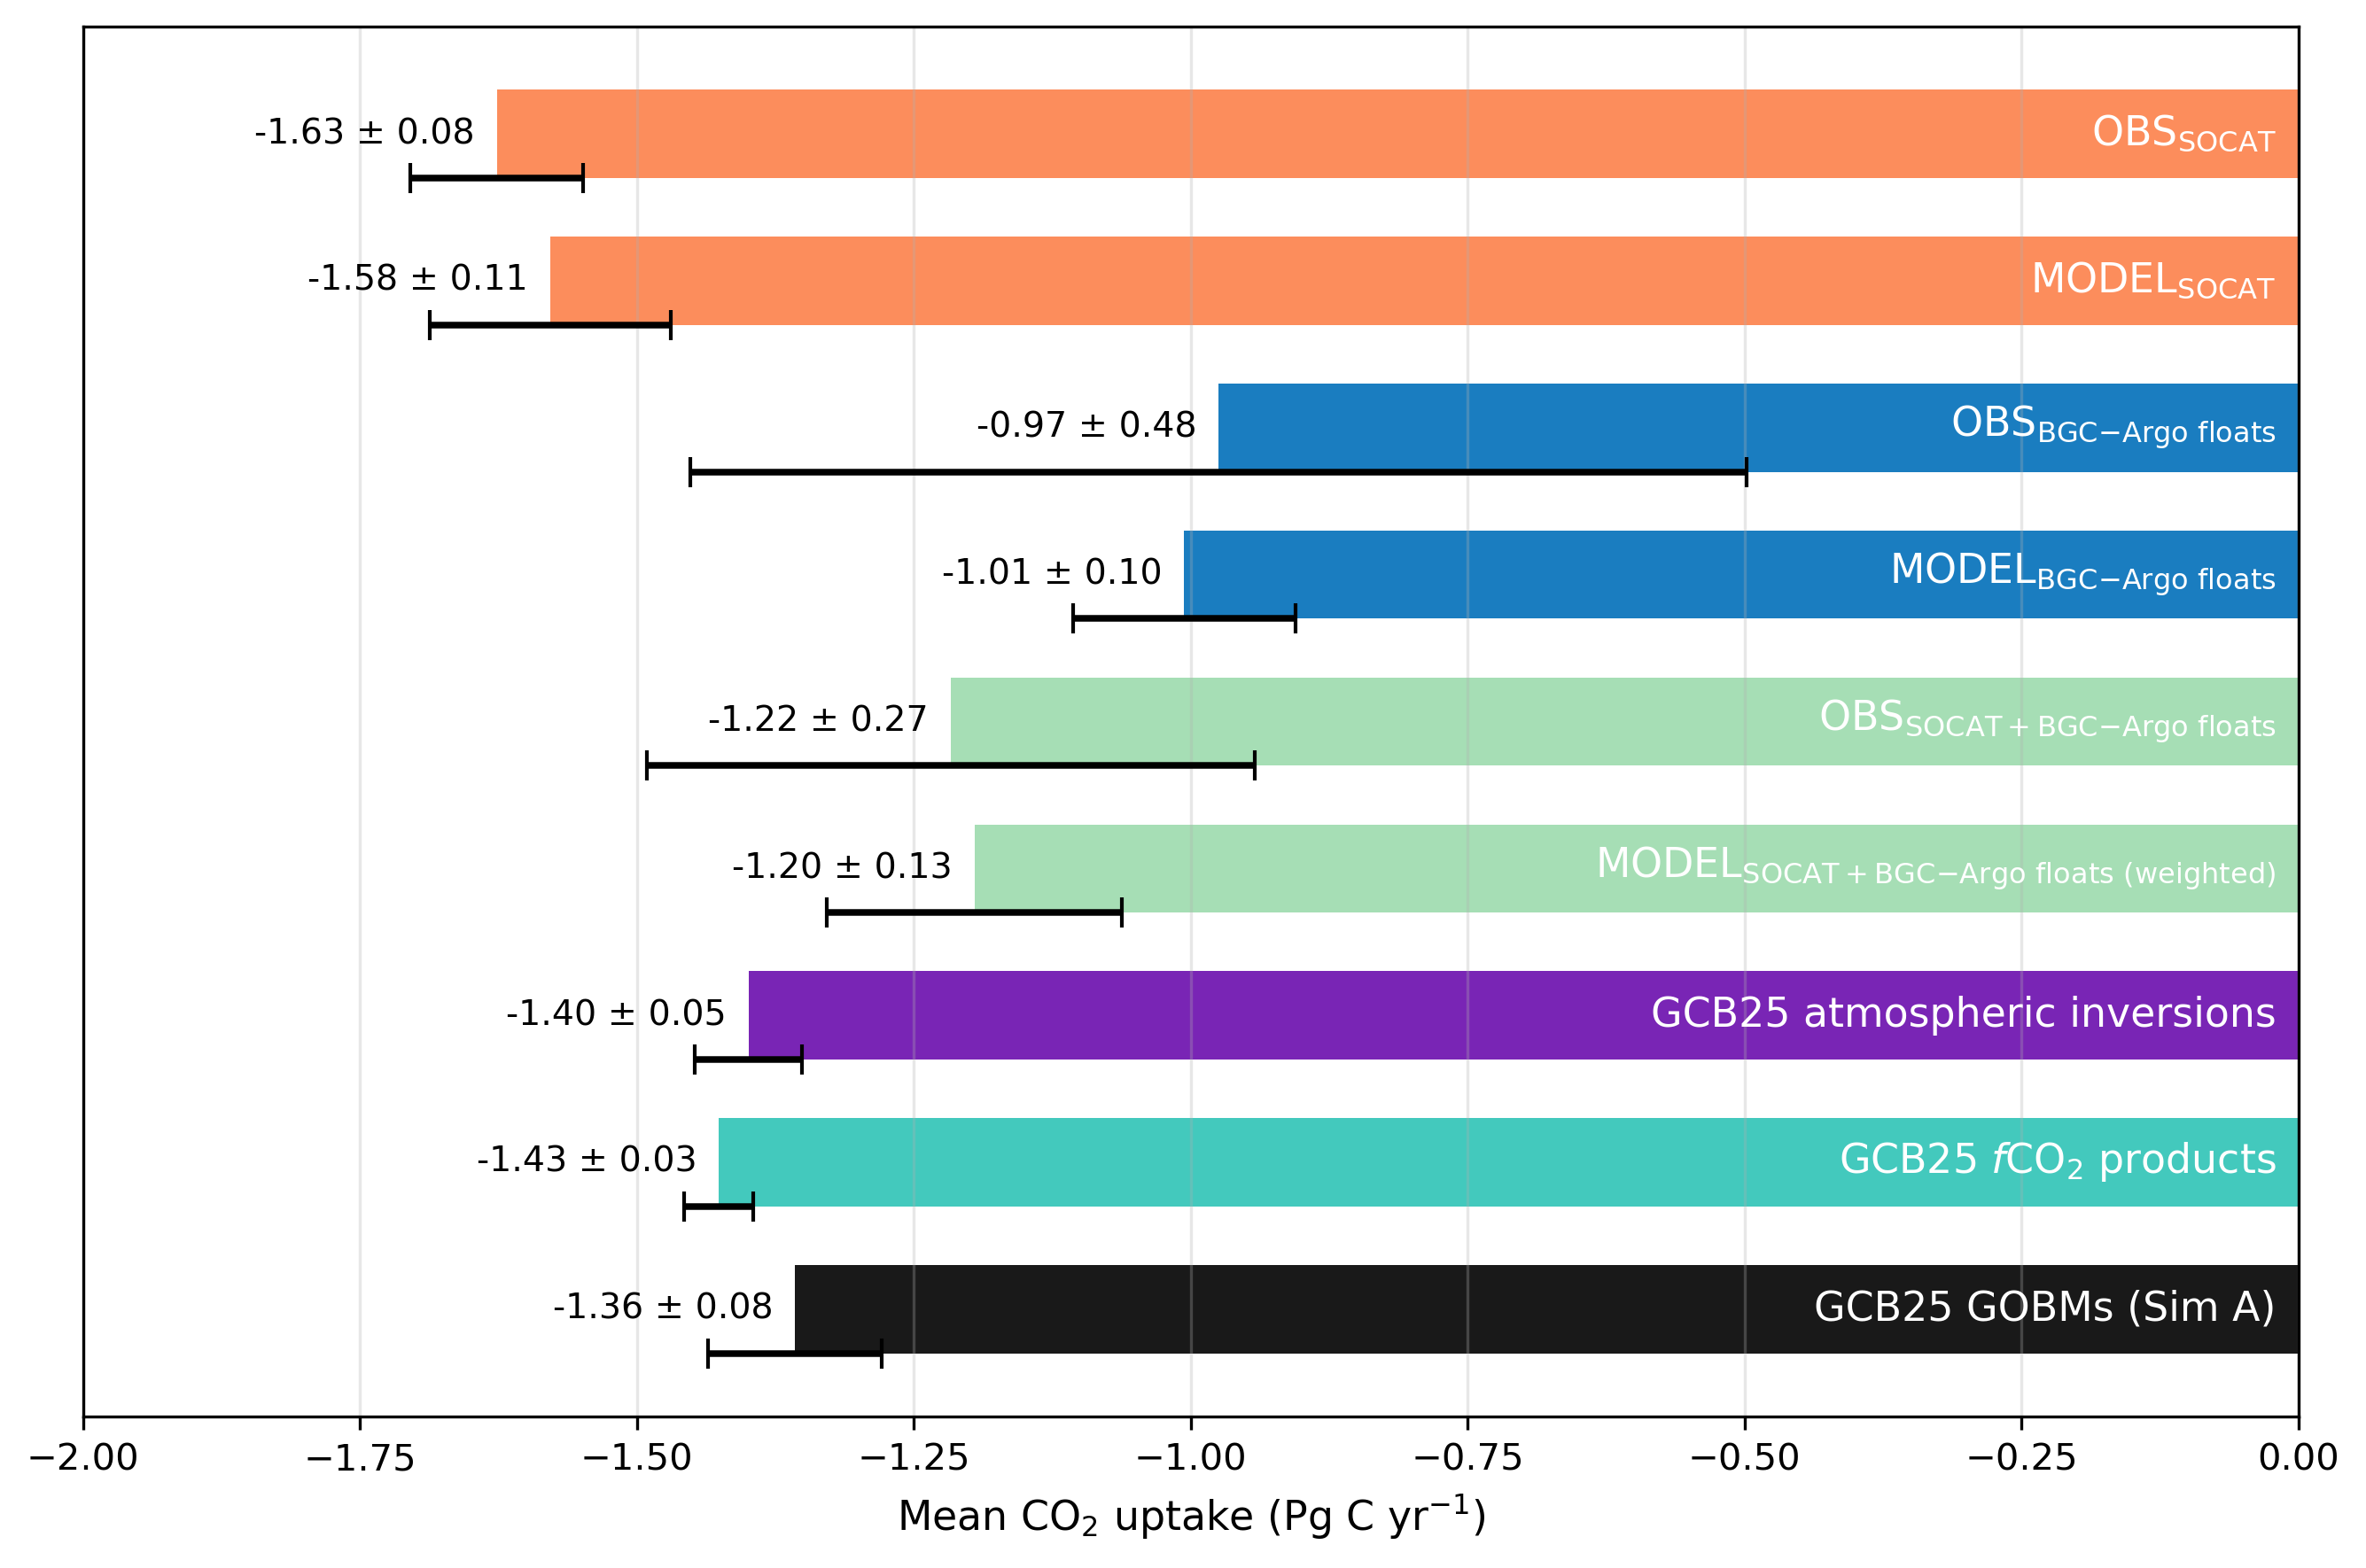


=== Multi-year mean Southern Ocean CO₂ uptake (2004–2024) ===
Reported as: mean ± σ_mean   (95% CI of multi-year mean)   [min-max range for GCB]

OBS$_{\mathrm{SOCAT}}$
  mean =  -1.63 Pg C yr⁻¹
  σ_mean =  0.08
  95% CI = [-1.78, -1.47]
  P(mean < 0) = 1.0000

MODEL$_{\mathrm{SOCAT}}$
  mean =  -1.58 Pg C yr⁻¹
  σ_mean =  0.11
  95% CI = [-1.79, -1.36]
  P(mean < 0) = 1.0000

OBS$_{\mathrm{BGC{-}Argo\ floats}}$
  mean =  -0.97 Pg C yr⁻¹
  σ_mean =  0.48
  95% CI = [-1.91, -0.04]
  P(mean < 0) = 0.9792

MODEL$_{\mathrm{BGC{-}Argo\ floats}}$
  mean =  -1.01 Pg C yr⁻¹
  σ_mean =  0.10
  95% CI = [-1.20, -0.81]
  P(mean < 0) = 1.0000

OBS$_{\mathrm{SOCAT+BGC{-}Argo\ floats}}$
  mean =  -1.22 Pg C yr⁻¹
  σ_mean =  0.27
  95% CI = [-1.75, -0.68]
  P(mean < 0) = 1.0000

MODEL$_{\mathrm{SOCAT+BGC{-}Argo\ floats\ (weighted)}}$
  mean =  -1.20 Pg C yr⁻¹
  σ_mean =  0.13
  95% CI = [-1.46, -0.93]
  P(mean < 0) = 1.0000

GCB25 atmospheric inversions
  mean =  -1.40 Pg C yr⁻¹
  σ_mean =  0.05
  9

In [61]:
# ============================================================
# SUMMARY BAR PLOT (OBS + MODELS + GCB)
# mean bars + ±1σ (σ_mean) errorbars (black) at bottom
# GCB rows also get a red min-max whisker (top) across
# individual products/models/members
# text = mean ± σ_mean  <-- now matches the black whiskers
#
# + PRINT TABLE S2 (mean, sigma_mean, CI95, P(mean<0))
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

YEAR_MIN, YEAR_MAX = 2004, 2024
N_MC = 200000
SEED = 42

# ============================================================
# Monte Carlo helper
# ============================================================

def mc_stats(Fy, sy, N=200000, seed=42):
    """
    Returns:
      mean_est   : multi-year mean of annual means
      sigma_mean : std of MC distribution of the multi-year mean
      ci95       : (2.5%, 97.5%) of MC distribution of the multi-year mean
      p_neg      : P(mean < 0) from MC draws (useful for Table S2)
    """
    Fy = np.asarray(Fy, dtype=float)
    sy = np.asarray(sy, dtype=float)

    m = np.isfinite(Fy) & np.isfinite(sy)
    Fy, sy = Fy[m], sy[m]
    if Fy.size == 0:
        return np.nan, np.nan, (np.nan, np.nan), np.nan

    rng = np.random.default_rng(seed)
    draws = rng.normal(loc=Fy, scale=sy, size=(N, Fy.size))
    means = draws.mean(axis=1)

    mean_est = Fy.mean()
    sigma_mean = means.std(ddof=0)
    ci95 = np.quantile(means, [0.025, 0.975])
    p_neg = (means < 0).mean()

    return mean_est, sigma_mean, (ci95[0], ci95[1]), p_neg


# ============================================================
# Basic checks
# ============================================================

required_yearly_cols = [
    "year",
    "SOCAT",
    "SOCAT_sigma_PgC_yr",
    "SOCAT_predictions",
    "SOCAT_predictions_sigma_PgC_yr",
    "floats",
    "floats_sigma_PgC_yr",
    "floats_predictions",
    "floats_predictions_sigma_PgC_yr",
    "combined",
    "combined_sigma_PgC_yr",
    "combined_predictions_weighted",
    "combined_predictions_weighted_sigma_PgC_yr",
]

missing_cols = [c for c in required_yearly_cols if c not in yearly_flux_summary.columns]
if missing_cols:
    raise KeyError(
        "yearly_flux_summary is missing required columns: "
        + ", ".join(missing_cols)
    )

for obj_name in ["fco2_ds", "gobm_ds", "ens_mean", "ens_std"]:
    if obj_name not in globals():
        raise NameError(f"Required object '{obj_name}' is not defined.")


# ============================================================
# Subset to 2004–2024
# ============================================================

df = yearly_flux_summary.copy()
df = df[(df["year"] >= YEAR_MIN) & (df["year"] <= YEAR_MAX)].copy()

fco2_plot = fco2_ds.sel(year=slice(YEAR_MIN, YEAR_MAX))
gobm_plot = gobm_ds.sel(year=slice(YEAR_MIN, YEAR_MAX))

mask_inv = (ens_mean["year"] >= YEAR_MIN) & (ens_mean["year"] <= YEAR_MAX)
inv_mean = ens_mean.values[mask_inv]
inv_std = ens_std.values[mask_inv]


# ============================================================
# GCB min-max ranges (spread across individual products/models/members
# of each dataset's OWN multi-year mean, 2004-2024)
# ============================================================

# fCO2 products: real, computed directly from fco2_ds
fco2_product_means = fco2_plot["fgco2_products"].mean("year").values
fco2_range = (float(np.nanmin(fco2_product_means)), float(np.nanmax(fco2_product_means)))

# GOBMs: range of the 2004-2024 mean across the individual models
gobm_model_means = gobm_plot["gobm_all"].mean("year").values
gobm_range = (float(np.nanmin(gobm_model_means)), float(np.nanmax(gobm_model_means)))

# Inversions: range of the 2004-2024 mean across the members that cover the
# whole period (members starting after 2004 are left out of the range so that
# all means refer to the same years)
_inv_full = member_masked_period.dropna("ensemble_member", how="any")
inv_member_means = _inv_full.mean("year").values
inv_range = (float(np.nanmin(inv_member_means)), float(np.nanmax(inv_member_means)))
print(f"Inversion min-max range based on {inv_member_means.size} full-period members")


# ============================================================
# BUILD ROWS IN NEW ORDER
# Each row: (label, mean, sigma_mean, (ci_low, ci_high), p_neg, color, range_lohi)
# range_lohi is None for OBS/MODEL rows, (min, max) for GCB rows
# ============================================================

rows = []

# ---- SOCAT ----
m, s, ci, pneg = mc_stats(
    df["SOCAT"].values,
    df["SOCAT_sigma_PgC_yr"].values,
    N=N_MC,
    seed=SEED,
)
rows.append((r"OBS$_{\mathrm{SOCAT}}$", m, s, ci, pneg, "#FC814A", None))

m, s, ci, pneg = mc_stats(
    df["SOCAT_predictions"].values,
    df["SOCAT_predictions_sigma_PgC_yr"].values,
    N=N_MC,
    seed=SEED,
)
rows.append((r"MODEL$_{\mathrm{SOCAT}}$", m, s, ci, pneg, "#FC814A", None))

# ---- FLOATS ----
m, s, ci, pneg = mc_stats(
    df["floats"].values,
    df["floats_sigma_PgC_yr"].values,
    N=N_MC,
    seed=SEED,
)
rows.append((r"OBS$_{\mathrm{BGC{-}Argo\ floats}}$", m, s, ci, pneg, "#016FB9", None))

m, s, ci, pneg = mc_stats(
    df["floats_predictions"].values,
    df["floats_predictions_sigma_PgC_yr"].values,
    N=N_MC,
    seed=SEED,
)
rows.append((r"MODEL$_{\mathrm{BGC{-}Argo\ floats}}$", m, s, ci, pneg, "#016FB9", None))

# ---- COMBINED ----
m, s, ci, pneg = mc_stats(
    df["combined"].values,
    df["combined_sigma_PgC_yr"].values,
    N=N_MC,
    seed=SEED,
)
rows.append((r"OBS$_{\mathrm{SOCAT+BGC{-}Argo\ floats}}$", m, s, ci, pneg, "#9DDBAD", None))

m, s, ci, pneg = mc_stats(
    df["combined_predictions_weighted"].values,
    df["combined_predictions_weighted_sigma_PgC_yr"].values,
    N=N_MC,
    seed=SEED,
)
rows.append((
    r"MODEL$_{\mathrm{SOCAT+BGC{-}Argo\ floats\ (weighted)}}$",
    m, s, ci, pneg, "#9DDBAD", None
))

# ---- GCB ----
m, s, ci, pneg = mc_stats(inv_mean, inv_std, N=N_MC, seed=SEED)
rows.append(("GCB25 atmospheric inversions", m, s, ci, pneg, "#6A0DAD", inv_range))

Fy = fco2_plot["fgco2_products"].mean("product").values
sy = fco2_plot["fgco2_products"].std("product").values
m, s, ci, pneg = mc_stats(Fy, sy, N=N_MC, seed=SEED)
rows.append(("GCB25 $f\\mathrm{CO}_2$ products", m, s, ci, pneg, "#2EC4B6", fco2_range))

m, s, ci, pneg = mc_stats(
    gobm_plot["gobm_mean"].values,
    gobm_plot["gobm_std"].values,
    N=N_MC,
    seed=SEED,
)
rows.append(("GCB25 GOBMs (Sim A)", m, s, ci, pneg, "k", gobm_range))


# ============================================================
# PRINT TABLE S2 CONTENT (publication-ready)
# ============================================================

print("\n=== Table S2. Significance of multi-year mean Southern Ocean CO2 flux (2004–2024, south of 30°S) ===")
print("Reported as mean ± σ_mean, with 95% CI from Monte Carlo propagation of annual uncertainties.\n")

table_rows = []
for label, mean_est, sigma_mean, (ci_l, ci_u), pneg, color, range_lohi in rows:
    sig = "YES" if (ci_l < 0) and (ci_u < 0) else "NO"
    table_rows.append({
        "Dataset": label,
        "Mean (Pg C yr-1)": mean_est,
        "σ_mean (Pg C yr-1)": sigma_mean,
        "95% CI low (Pg C yr-1)": ci_l,
        "95% CI high (Pg C yr-1)": ci_u,
        "Range min (Pg C yr-1)": range_lohi[0] if range_lohi else np.nan,
        "Range max (Pg C yr-1)": range_lohi[1] if range_lohi else np.nan,
        "P(mean < 0)": pneg,
        "Significant sink?": sig,
    })

    print(f"{label}")
    print(f"  mean ± σ_mean = {mean_est:.2f} ± {sigma_mean:.2f} Pg C yr⁻¹")
    print(f"  95% CI        = {ci_l:.2f} to {ci_u:.2f} Pg C yr⁻¹")
    if range_lohi:
        print(f"  min-max range = {range_lohi[0]:.2f} to {range_lohi[1]:.2f} Pg C yr⁻¹")
    print(f"  P(mean < 0)   = {pneg:.4f}")
    print(f"  Significant sink? {sig}\n")

df_S2 = pd.DataFrame(table_rows)


# ============================================================
# ARRAYS FOR PLOTTING (mirror order)
# ============================================================

labels_plot = [r[0] for r in rows][::-1]
means_plot = np.array([r[1] for r in rows], dtype=float)[::-1]
sigmas_plot = np.array([r[2] for r in rows], dtype=float)[::-1]
ci_low = np.array([r[3][0] for r in rows], dtype=float)[::-1]
ci_high = np.array([r[3][1] for r in rows], dtype=float)[::-1]
colors = [r[5] for r in rows][::-1]
ranges_plot = [r[6] for r in rows][::-1]

# black whiskers now show ±1σ (σ_mean), not the 95% CI
err_left = sigmas_plot
err_right = sigmas_plot


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6.0), dpi=300)
ypos = np.arange(len(labels_plot))
bar_height = 0.6

ax.barh(ypos, means_plot, color=colors, alpha=0.9, height=bar_height)

# ±1σ whiskers (black, bottom of each bar)
for i, (mval, el, er) in enumerate(zip(means_plot, err_left, err_right)):
    ax.errorbar(
        mval,
        i - bar_height / 2,
        xerr=np.array([[el], [er]]),
        fmt="none",
        ecolor="black",
        elinewidth=1.8,
        capsize=4,
        zorder=5,
    )

# Min-max whiskers for GCB rows only (red, top of each bar)
# for i, (mval, range_lohi) in enumerate(zip(means_plot, ranges_plot)):
#     if range_lohi is None:
#         continue
#     rmin, rmax = range_lohi
#     ax.errorbar(
#         mval,
#         i + bar_height / 2,
#         xerr=np.array([[mval - rmin], [rmax - mval]]),
#         fmt="none",
#         ecolor="red",
#         elinewidth=1.5,
#         capsize=4,
#         zorder=5,
#     )

# Labels
for i, (label, mval, smean) in enumerate(zip(labels_plot, means_plot, sigmas_plot)):
    ax.text(
        -0.02,
        i,
        label,
        va="center",
        ha="right",
        color="white",
        fontsize=11,
    )
    ax.text(
        mval - 0.02,
        i,
        f"{mval:.2f} ± {smean:.2f}",
        va="center",
        ha="right",
        fontsize=9.5,
        color="black",
    )

# Formatting
ax.set_yticks([])
ax.set_xlabel("Mean CO$_2$ uptake (Pg C yr$^{-1}$)", fontsize=11)
ax.set_xlim(-2.0, 0)
ax.grid(axis="x", alpha=0.3)

legend_handles = [
    Line2D([0], [0], color="black", lw=1.8, label=r"$\pm 1\sigma$ ($\sigma_{\mathrm{mean}}$)"),
    Line2D([0], [0], color="red", lw=1.5, label="Min–max across GCB products/models/members"),
]
# ax.legend(
#     handles=legend_handles,
#     loc="lower right",
#     frameon=False,
#     fontsize=8.5,
# )

plt.tight_layout()

fig.savefig(
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/figs/Fig6.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# PRINT NUMERICAL SUMMARY (same values used in bars)
# ============================================================

print("\n=== Multi-year mean Southern Ocean CO₂ uptake (2004–2024) ===")
print("Reported as: mean ± σ_mean   (95% CI of multi-year mean)   [min-max range for GCB]\n")

for label, mean_est, sigma_mean, (ci_l, ci_u), pneg, color, range_lohi in rows:
    print(f"{label}")
    print(f"  mean = {mean_est:6.2f} Pg C yr⁻¹")
    print(f"  σ_mean = {sigma_mean:5.2f}")
    print(f"  95% CI = [{ci_l:5.2f}, {ci_u:5.2f}]")
    if range_lohi:
        print(f"  min-max = [{range_lohi[0]:5.2f}, {range_lohi[1]:5.2f}]")
    print(f"  P(mean < 0) = {pneg:.4f}\n")

## 7. Trends

### 7.1 Linear trends, 2004–2024 (manuscript Table 1)

An ordinary least-squares line is fitted to the 21 annual fluxes of each data set (south of 30°S). The slope is reported in Pg C yr⁻² with its standard error and p-value. A negative slope means a strengthening sink.

The standard error assumes independent annual residuals, so it may be underestimated if the residuals are autocorrelated.

In [62]:
# ============================================================
# Linear trends in Southern Ocean CO2 uptake (2004–2024)
# MLP products, GCB products, GOBMs, and atmospheric inversions
# ============================================================

from scipy.stats import linregress
import numpy as np
import pandas as pd

YEAR_MIN, YEAR_MAX = 2004, 2024

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def restrict_years_df(df, year_col="year", year_min=YEAR_MIN, year_max=YEAR_MAX):
    return df.loc[df[year_col].between(year_min, year_max)].copy()


def restrict_years_xr(ds, year_min=YEAR_MIN, year_max=YEAR_MAX):
    return ds.sel(year=slice(year_min, year_max))


def compute_trend(years, values, label, category):
    years = np.asarray(years)
    values = np.asarray(values)

    valid = np.isfinite(years) & np.isfinite(values)
    years = years[valid]
    values = values[valid]

    slope, intercept, r_value, p_value, stderr = linregress(years, values)

    return {
        "category": category,
        "label": label,
        "n_years": len(years),
        "slope_PgC_yr2": slope,
        "stderr_PgC_yr2": stderr,
        "p_value": p_value,
        "r_value": r_value,
        "intercept": intercept,
    }


def print_trend_report(trends_df, year_min=YEAR_MIN, year_max=YEAR_MAX):
    print(f"\n=== Linear Trends in Southern Ocean CO₂ Uptake ({year_min}–{year_max}) ===\n")

    for category in ["Observations", "Models", "GCB", "Atmospheric inversions"]:
        subset = trends_df.loc[trends_df["category"] == category]
        if subset.empty:
            continue

        print(f"{category}:")
        for _, row in subset.iterrows():
            print(
                f"  {row['label']:<32} "
                f"{row['slope_PgC_yr2']:.4f} ± {row['stderr_PgC_yr2']:.4f} "
                f"Pg C yr⁻² (p = {row['p_value']:.2e})"
            )
        print()

    print("--- Full table ---")
    print(trends_df.to_string(index=False))


# ------------------------------------------------------------
# Prepare datasets
# ------------------------------------------------------------

mlp_df = restrict_years_df(yearly_flux_summary, year_min=YEAR_MIN, year_max=YEAR_MAX)
years_mlp = mlp_df["year"].to_numpy()

fco2_plot = restrict_years_xr(fco2_ds, year_min=YEAR_MIN, year_max=YEAR_MAX)
gobm_plot = restrict_years_xr(gobm_ds, year_min=YEAR_MIN, year_max=YEAR_MAX)
inv_plot = restrict_years_xr(ens_mean, year_min=YEAR_MIN, year_max=YEAR_MAX)

# ------------------------------------------------------------
# Define trend inputs
# ------------------------------------------------------------

trend_specs = [
    {
        "category": "Observations",
        "label": "SOCAT observed",
        "years": years_mlp,
        "values": mlp_df["SOCAT"].to_numpy(),
    },
    {
        "category": "Observations",
        "label": "FLOATS observed",
        "years": years_mlp,
        "values": mlp_df["floats"].to_numpy(),
    },
    {
        "category": "Observations",
        "label": "SOCAT+BGC-Argo observed",
        "years": years_mlp,
        "values": mlp_df["combined"].to_numpy(),
    },
    {
        "category": "Models",
        "label": "SOCAT model",
        "years": years_mlp,
        "values": mlp_df["SOCAT_predictions"].to_numpy(),
    },
    {
        "category": "Models",
        "label": "FLOATS model",
        "years": years_mlp,
        "values": mlp_df["floats_predictions"].to_numpy(),
    },
    {
        "category": "Models",
        "label": "SOCAT+BGC-Argo model (weighted)",
        "years": years_mlp,
        "values": mlp_df["combined_predictions_weighted"].to_numpy(),
    },
    {
        "category": "GCB",
        "label": "GCB fCO₂ products",
        "years": fco2_plot["year"].values,
        "values": fco2_plot["fgco2_products"].mean("product").values,
    },
    {
        "category": "GCB",
        "label": "GCB GOBMs (Sim A)",
        "years": gobm_plot["year"].values,
        "values": gobm_plot["gobm_mean"].values,
    },
    {
        "category": "Atmospheric inversions",
        "label": "Atmospheric inversions",
        "years": inv_plot["year"].values,
        "values": inv_plot.values,
    },
]

# ------------------------------------------------------------
# Compute trends
# ------------------------------------------------------------

trends = pd.DataFrame(
    compute_trend(
        spec["years"],
        spec["values"],
        label=spec["label"],
        category=spec["category"],
    )
    for spec in trend_specs
)

# Optional: preserve a nice category order
category_order = {
    "Observations": 0,
    "Models": 1,
    "GCB": 2,
    "Atmospheric inversions": 3,
}
trends = (
    trends.assign(_order=trends["category"].map(category_order))
    .sort_values(["_order", "label"])
    .drop(columns="_order")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print_trend_report(trends, year_min=YEAR_MIN, year_max=YEAR_MAX)


=== Linear Trends in Southern Ocean CO₂ Uptake (2004–2024) ===

Observations:
  FLOATS observed                  0.0411 ± 0.0116 Pg C yr⁻² (p = 2.19e-03)
  SOCAT observed                   -0.0503 ± 0.0061 Pg C yr⁻² (p = 9.83e-08)
  SOCAT+BGC-Argo observed          -0.0038 ± 0.0070 Pg C yr⁻² (p = 5.94e-01)

Models:
  FLOATS model                     0.0202 ± 0.0018 Pg C yr⁻² (p = 8.54e-10)
  SOCAT model                      -0.0266 ± 0.0026 Pg C yr⁻² (p = 4.76e-09)
  SOCAT+BGC-Argo model (weighted)  0.0019 ± 0.0031 Pg C yr⁻² (p = 5.46e-01)

GCB:
  GCB GOBMs (Sim A)                -0.0157 ± 0.0010 Pg C yr⁻² (p = 1.02e-12)
  GCB fCO₂ products                -0.0223 ± 0.0020 Pg C yr⁻² (p = 1.09e-09)

Atmospheric inversions:
  Atmospheric inversions           -0.0151 ± 0.0023 Pg C yr⁻² (p = 2.21e-06)

--- Full table ---
              category                           label  n_years  slope_PgC_yr2  stderr_PgC_yr2      p_value   r_value  intercept
          Observations                 FLO

### 7.2 Decadal trends in the biome domain (manuscript Table 2)

Trends of the three reconstructions are computed over 2004–2018, 2004–2012 and 2015–2024 using the biome-domain series (Section 1.5), and reported in Pg C yr⁻¹ decade⁻¹ (slope × 10).

For 2004–2018, each trend is compared with the pCO₂-product trend of Hauck et al. (2023a): −0.26 ± 0.06 Pg C yr⁻¹ decade⁻¹ for 2001–2018, where ± is the spread across products. Hauck et al. report sink growth (positive = stronger sink), so their value is sign-flipped to match the flux-trend convention used here. The z-score is

z = (trend − reference) / √(SE² + spread²).

|z| < 2 means the two trends are consistent.

In [63]:
from scipy.stats import linregress
import numpy as np
import pandas as pd

# ============================================================
# What this script reports
# ------------------------------------------------------------
# - We fit a linear trend of FLUX vs YEAR within each window.
# - Flux convention: negative = uptake.
# - We REPORT the flux trend dF/dt in units of Pg C yr^-1 decade^-1.
#   (This is just the fitted per-year slope expressed per decade.)
# - We DO NOT multiply by -1 anywhere (no "sink-growth" sign flip).
# - z-scores are ONLY computed for 2004-2018 and compare to Hauck et al.
#   Hauck reports sink-growth (+ = stronger sink), so we convert Hauck to
#   flux-trend convention by flipping the sign of the reference.
#
# DOMAIN: uses biomes_yearly_flux_summary (Fay & McKinley 2014 biome
# domain, ~35S), matching the domain Hauck et al. (2023a) use.
# ============================================================

# ==========================
# Helpers
# ==========================
def fit_trend(years, flux):
    """Return slope, stderr, p for flux = a*year + b. slope is per YEAR."""
    slope, _, _, p, stderr = linregress(years.astype(float), flux.astype(float))
    return slope, stderr, p

def summarize_window_flux_trend(label, years, flux, y0, y1, ref_val=None, ref_unc=None):
    """
    Fit trend over [y0, y1] and report:
      - trend_dec: dF/dt in Pg C yr^-1 decade^-1  (NEGATIVE => strengthening uptake)
      - trend_dec_se: SE of trend_dec
      - p: p-value of slope (same regardless of unit scaling)
      - deltaF: total change in flux across window (Pg C yr^-1), using fitted slope
      - z: optional z-score vs reference (only when ref provided)
    """
    m = (years >= y0) & (years <= y1)
    yrs = years[m]
    y   = flux[m]

    slope, stderr, p = fit_trend(yrs, y)  # slope per year: Pg C yr^-2

    trend_dec    = slope * 10.0
    trend_dec_se = stderr * 10.0
    deltaF = slope * (y1 - y0)

    z = None
    if (ref_val is not None) and (ref_unc is not None):
        z = (trend_dec - ref_val) / np.sqrt(trend_dec_se**2 + ref_unc**2)

    return dict(
        label=label, y0=y0, y1=y1,
        trend_dec=trend_dec, trend_dec_se=trend_dec_se,
        p=p, deltaF=deltaF, n=int(np.sum(m)),
        ref_val=ref_val, ref_unc=ref_unc, z=z,
    )

# ==========================
# Windows
# ==========================
windows = {
    "2004–2018 (Hauck et al., 2023a)": (2004, 2018),
    "2004–2012": (2004, 2012),
    "2015–2024": (2015, 2024),
}

# ==========================
# Hauck et al. (2023a) references
# Hauck reports SINK-GROWTH (positive = stronger sink) in Pg C yr^-1 decade^-1.
# We are reporting FLUX-TREND dF/dt (negative = stronger sink),
# so reference values must be SIGN-FLIPPED.
# ==========================
hauck_pco2_sinkgrowth, hauck_pco2_unc = 0.26, 0.06
hauck_gobm_sinkgrowth, hauck_gobm_unc = 0.11, 0.03

hauck_pco2_fluxtrend = -hauck_pco2_sinkgrowth
hauck_gobm_fluxtrend = -hauck_gobm_sinkgrowth

# ==========================
# Series getters
# ==========================
def df_series(df, y0, y1, col):
    m = (df["year"] >= y0) & (df["year"] <= y1)
    return df.loc[m, "year"].values, df.loc[m, col].values

# ==========================
# Model columns
# ==========================
my_models = {
    "SOCAT model": "SOCAT_predictions",
    "FLOATS model": "floats_predictions",
    "SOCAT+BGC-Argo model (weighted)": "combined_predictions_weighted",
}

# ==========================
# Build the results table
# ==========================
if "biomes_yearly_flux_summary" not in globals():
    raise NameError(
        "'biomes_yearly_flux_summary' is not defined. Run the earlier "
        "cell that builds the biome-restricted flux series before "
        "running this cell."
    )

rows = []
for win_name, (y0, y1) in windows.items():
    for label, col in my_models.items():
        yrs, y = df_series(biomes_yearly_flux_summary, y0, y1, col)

        if y0 == 2004 and y1 == 2018:
            ref_val, ref_unc = hauck_pco2_fluxtrend, hauck_pco2_unc
        else:
            ref_val, ref_unc = None, None

        r = summarize_window_flux_trend(label, yrs, y, y0, y1, ref_val=ref_val, ref_unc=ref_unc)
        r["window"] = win_name
        rows.append(r)

results_df = pd.DataFrame(rows)

# ==========================
# Readable console report, grouped by window
# ==========================
print("=" * 88)
print("DECADAL TREND COMPARISON -- biome domain (~35S)")
print("=" * 88)

for win_name in windows.keys():
    sub = results_df.loc[results_df["window"] == win_name]
    print(f"\n{win_name}  (n={sub['n'].iloc[0]} yr)")
    print("-" * 88)
    print(
        sub[["label", "trend_dec", "trend_dec_se", "p", "z"]]
        .rename(columns={
            "label": "Dataset",
            "trend_dec": "Trend (Pg C/yr/decade)",
            "trend_dec_se": "SE",
            "p": "p-value",
            "z": "z (vs Hauck)",
        })
        .to_string(index=False, float_format=lambda x: f"{x:.3f}")
    )

# ==========================
# Word-friendly TSV block (unchanged structure, for copy-paste into a table)
# ==========================
def cell(trend, se, p, z):
    if p is None:
        p_txt = "NA"
    elif p == 0:
        p_txt = "0"
    else:
        exp = int(np.floor(np.log10(abs(p))))
        mant = p / (10**exp)
        p_txt = f"{mant:.2f} × 10{exp:+d}".replace("+", "⁺").replace("-", "⁻")
    z_txt = f"{z:+.2f}" if z is not None else "NA"
    return f"{trend:+.3f} ± {se:.3f} ({p_txt}; {z_txt})"

print("\n" + "=" * 88)
print("WORD-PASTE TABLE (TSV)")
print("=" * 88)
cols = list(windows.keys())
pivot = {label: {} for label in my_models.keys()}
for _, r in results_df.iterrows():
    pivot[r["label"]][r["window"]] = cell(r["trend_dec"], r["trend_dec_se"], r["p"], r["z"])

print("Dataset\t" + "\t".join(cols))
for label in my_models.keys():
    print(label + "\t" + "\t".join(pivot[label][c] for c in cols))

DECADAL TREND COMPARISON -- biome domain (~35S)

2004–2018 (Hauck et al., 2023a)  (n=15 yr)
----------------------------------------------------------------------------------------
                        Dataset  Trend (Pg C/yr/decade)    SE  p-value  z (vs Hauck)
                    SOCAT model                  -0.335 0.046    0.000        -0.989
                   FLOATS model                   0.141 0.036    0.002         5.717
SOCAT+BGC-Argo model (weighted)                  -0.102 0.047    0.051         2.065

2004–2012  (n=9 yr)
----------------------------------------------------------------------------------------
                        Dataset  Trend (Pg C/yr/decade)    SE  p-value  z (vs Hauck)
                    SOCAT model                  -0.551 0.048    0.000           NaN
                   FLOATS model                  -0.075 0.038    0.087           NaN
SOCAT+BGC-Argo model (weighted)                  -0.380 0.038    0.000           NaN

2015–2024  (n=10 yr)
-------

## 8. Seasonal pCO₂ difference maps (manuscript Figure 7)

### 8.1 Seasonal mean pCO₂ per grid cell

The SOCAT-only and combined (weighted) prediction matrices are read again and restricted to 2004–2024, the same complete years used for the fluxes. This replaces the tables loaded in Section 2.1, which no longer matter at this point because all fluxes have already been computed. Each month is labelled with its austral season (DJF, MAM, JJA, SON). The mean predicted pCO₂ in each grid cell and season is computed for both reconstructions, and their difference is taken as SOCAT-only minus combined. Negative values mean the combined reconstruction has higher pCO₂.

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import Normalize

# ============================================================
# 1) LOAD PREDICTIONS
# ============================================================

predictions_socat = pd.read_csv(
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/PREDICTION_MATRIX_v2/matrix_predictions/"
    "pco2_prediction_matrix_SOCAT_only_MCensemble.csv"
)

predictions_combined_weighted = pd.read_csv(
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/PREDICTION_MATRIX_v2/matrix_predictions/"
    "pco2_prediction_matrix_SOCAT_AND_FLOATS_weighted_MCensemble.csv"
)

# ============================================================
# 2) ADD DJF/MAM/JJA/SON SEASON LABELS
# ============================================================

def assign_season(month):
    if month in [12, 1, 2]:
        return "DJF"
    elif month in [3, 4, 5]:
        return "MAM"
    elif month in [6, 7, 8]:
        return "JJA"
    elif month in [9, 10, 11]:
        return "SON"
    else:
        return np.nan

for df in (predictions_socat, predictions_combined_weighted):
    df["month_center"] = pd.to_datetime(df["month_center"], errors="coerce")
    df["month"] = df["month_center"].dt.month
    df["season"] = df["month"].apply(assign_season)

# Same analysis period as the flux results: complete years 2004-2024 only
predictions_socat = predictions_socat.loc[
    predictions_socat["month_center"].dt.year.between(2004, 2024)].copy()
predictions_combined_weighted = predictions_combined_weighted.loc[
    predictions_combined_weighted["month_center"].dt.year.between(2004, 2024)].copy()
print("Fig. 7 prediction years:",
      predictions_socat["month_center"].dt.year.min(), "-",
      predictions_socat["month_center"].dt.year.max())

# ============================================================
# 3) SEASONAL MEAN PER GRID CELL
# ============================================================

def seasonal_mean_pred(df, pred_col="ensemble_pco2_pred"):
    if {"latitude", "longitude"}.issubset(df.columns):
        lat_col, lon_col = "latitude", "longitude"
    elif {"lat_center", "lon_center"}.issubset(df.columns):
        lat_col, lon_col = "lat_center", "lon_center"
    else:
        raise KeyError("No valid latitude/longitude columns found in dataframe.")

    out = (
        df.dropna(subset=["season", pred_col, lat_col, lon_col])
          .groupby(["season", lat_col, lon_col], as_index=False)[pred_col]
          .mean()
          .rename(columns={
              lat_col: "latitude",
              lon_col: "longitude",
              pred_col: "pco2_pred"
          })
    )
    return out

seasonal_socat = seasonal_mean_pred(predictions_socat)
seasonal_cw = seasonal_mean_pred(predictions_combined_weighted)

# ============================================================
# 4) BUILD DATA TO PLOT: SOCAT − COMBINED WEIGHTED
# ============================================================

df_seasonal = seasonal_socat.merge(
    seasonal_cw,
    on=["season", "latitude", "longitude"],
    suffixes=("_socat", "_cw"),
    how="inner"
)

df_seasonal["delta_pco2"] = (
    df_seasonal["pco2_pred_socat"] - df_seasonal["pco2_pred_cw"]
)

Fig. 7 prediction years: 2004 - 2024


### 8.2 Plot the maps

- One polar map per season, coloured by the pCO₂ difference. The colour scale is symmetric and capped at the 99th percentile of the absolute differences. The true minimum and maximum are written at the ends of the colour bar.
- Purple shading marks sea ice: cells where the climatological sea-ice concentration reaches at least 15% in any month of the season (autumn, winter and spring only).
- The dashed line is the Polar Front (Orsi et al., 1995).

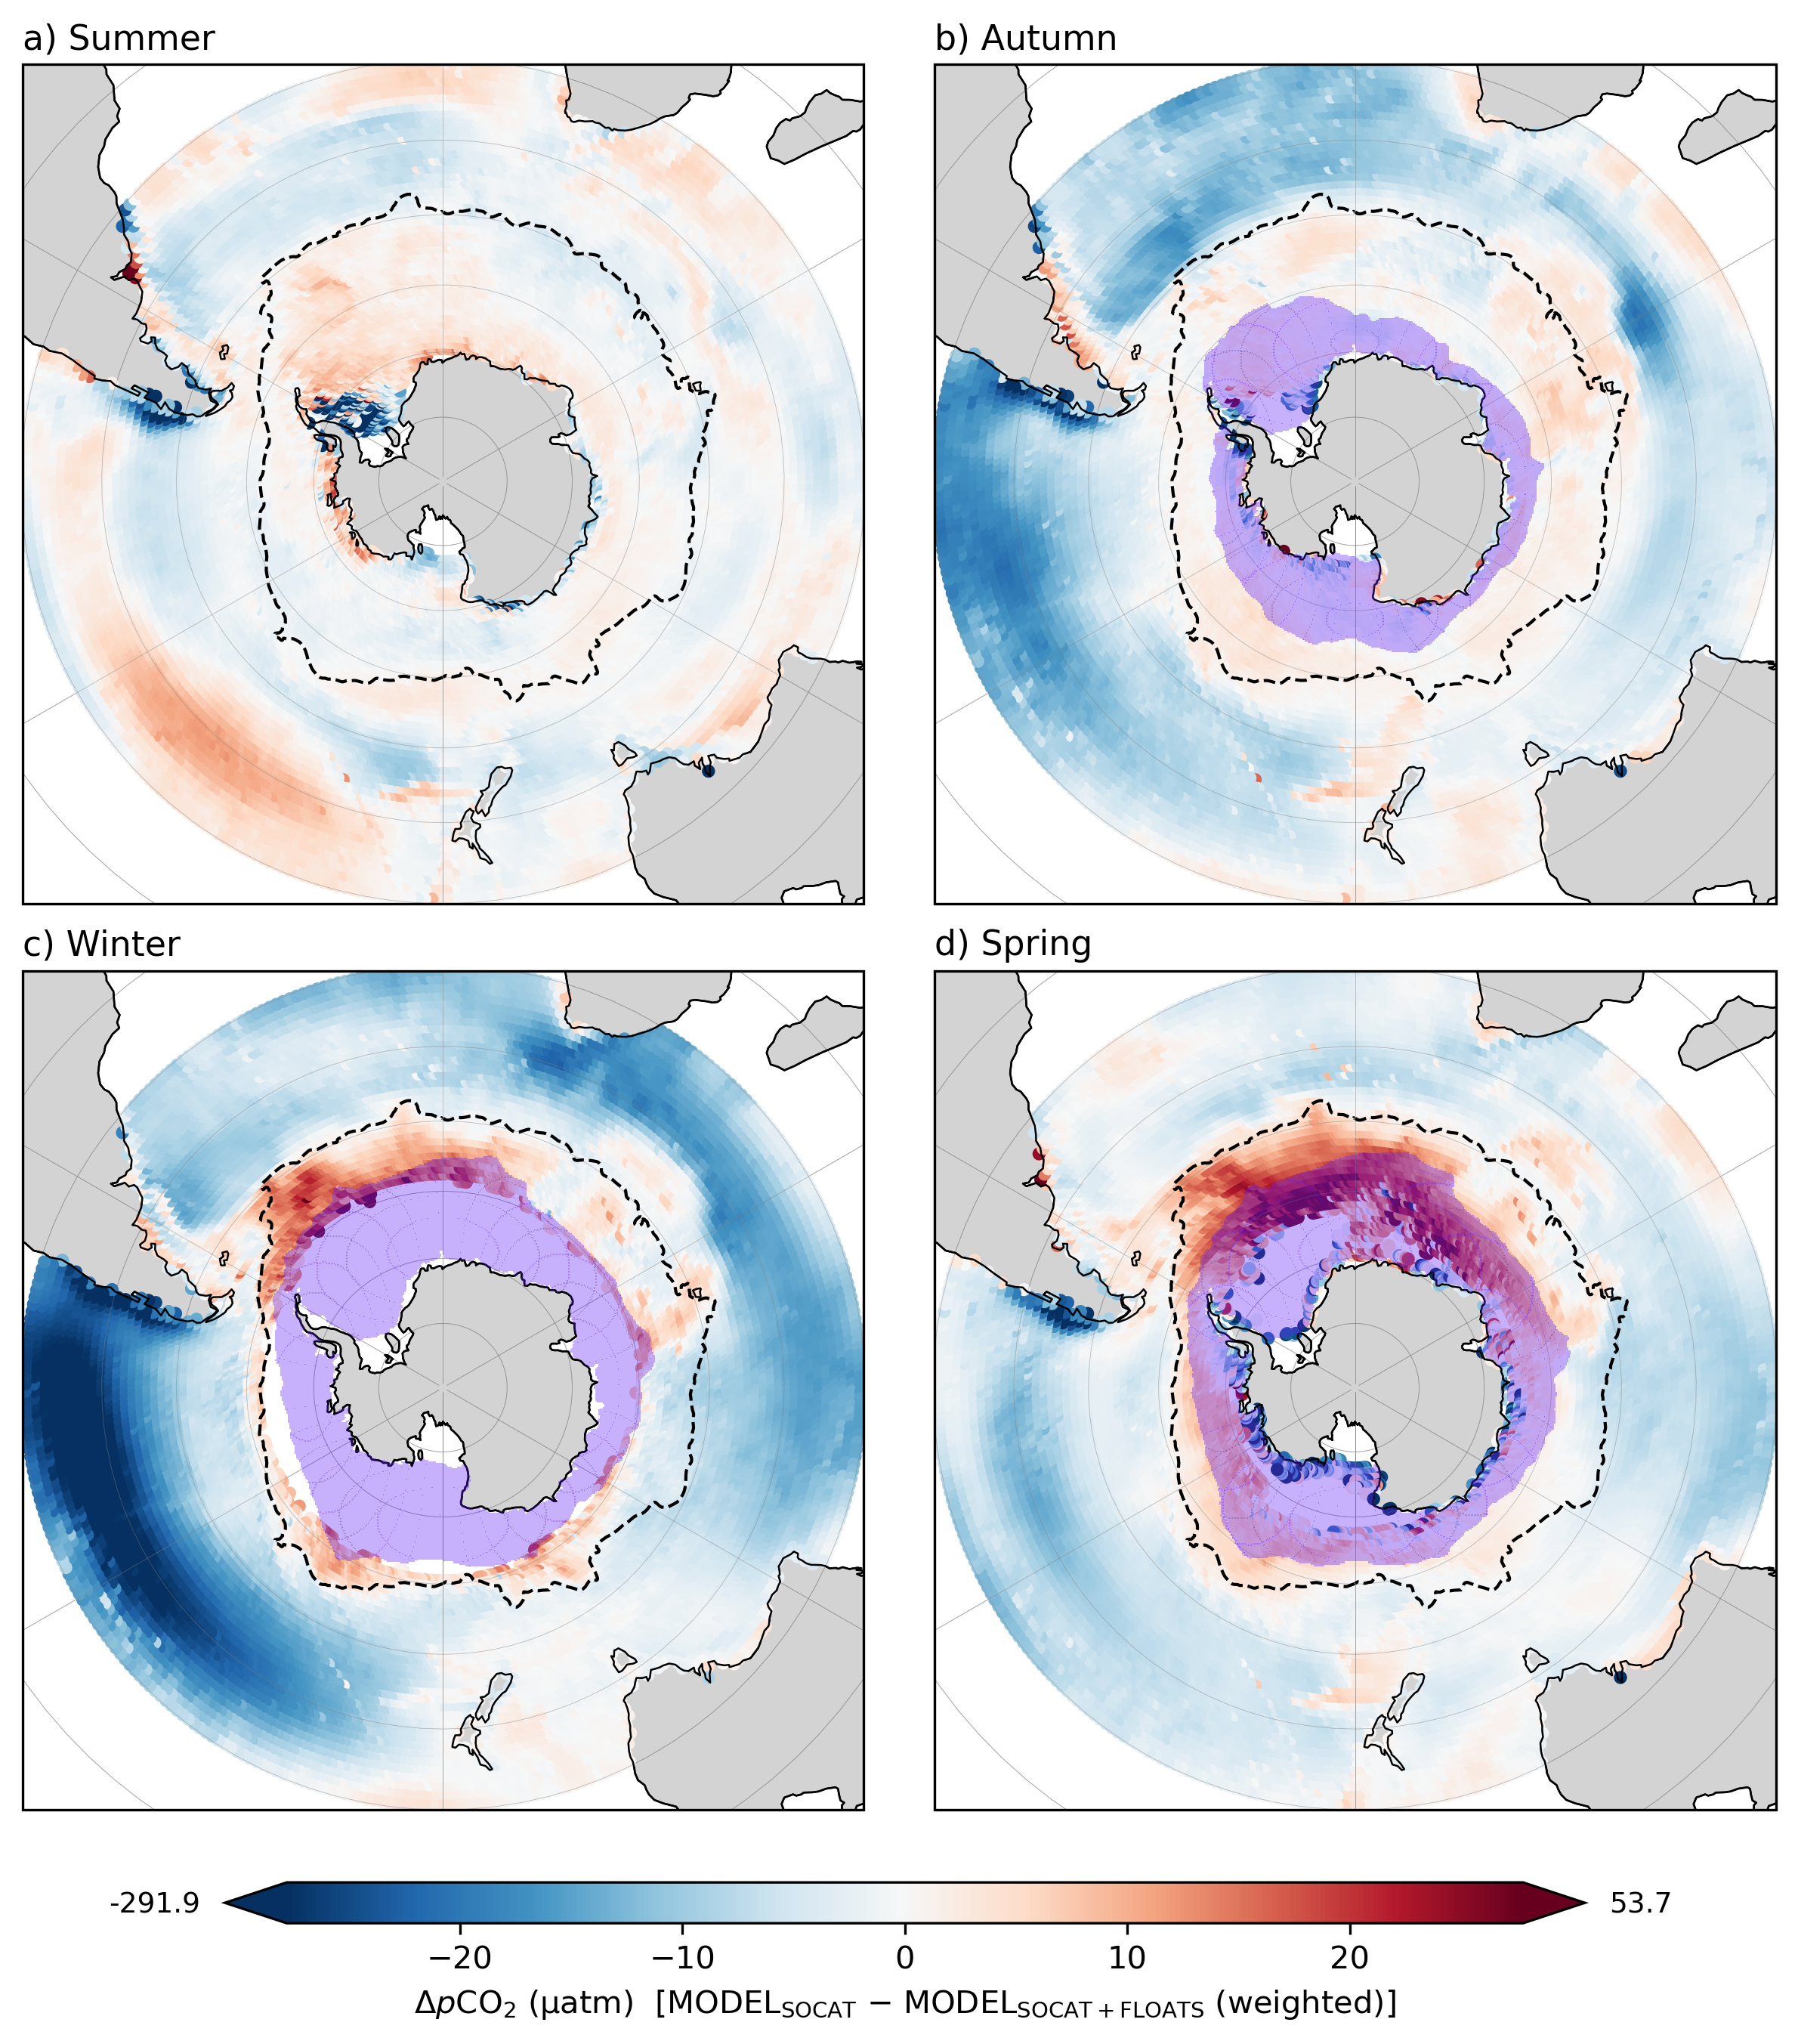

In [65]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import Normalize, ListedColormap

# ============================================================
# LOAD DATA
# ============================================================

fronts = xr.load_dataset(
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/data/fronts/62985.nc"
)

# Monthly sea-ice climatology DataArray (dims: month, yc, xc; units: percent)
seaice = xr.load_dataset("/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/data/fronts/sic_climatology_stats_sh_1991-2020.nc")
seaice_mmean = seaice.mmean


# ============================================================
# HELPERS: Orsi fronts plotting (handles 0..360 lon, NaNs, dateline jumps)
# ============================================================

def lon360_to_lon180(lon):
    lon = np.asarray(lon)
    return ((lon + 180) % 360) - 180

def plot_front_line(ax, lon, lat, *, jump_deg=20, **plot_kwargs):
    """
    Plot a front polyline safely on a global/polar map:
      - drops NaNs
      - converts lon 0..360 -> -180..180
      - splits line where longitude jumps (dateline / gaps) to avoid long chords
    """
    lon = np.asarray(lon).astype(float)
    lat = np.asarray(lat).astype(float)

    m = np.isfinite(lon) & np.isfinite(lat)
    lon = lon[m]
    lat = lat[m]

    lon = lon360_to_lon180(lon)
    if lon.size < 2:
        return

    dlon = np.abs(np.diff(lon))
    breaks = np.where(dlon > jump_deg)[0] + 1
    idxs = np.concatenate(([0], breaks, [lon.size]))

    for a, b in zip(idxs[:-1], idxs[1:]):
        if b - a < 2:
            continue
        ax.plot(
            lon[a:b], lat[a:b],
            transform=ccrs.PlateCarree(),
            **plot_kwargs
        )


# ============================================================
# HELPERS: Sea-ice seasonal MAX mask (ice-only fill, no contours)
# ============================================================

SEASON_TO_MONTHS = {
    "DJF": [12, 1, 2],
    "MAM": [3, 4, 5],
    "JJA": [6, 7, 8],
    "SON": [9, 10, 11],
}

def seasonal_max_from_monthly_clim(seaice_mmean, season):
    """
    Returns 2D seasonal MAX (grid-cell-wise) across the 3 months in the season.
    seaice_mmean values are percent (0..100).
    """
    months = SEASON_TO_MONTHS[season]
    return seaice_mmean.sel(month=months).max("month", skipna=True)

ICE_CMAP = ListedColormap(["#601ef9"])  # soft purple

def plot_ice_mask_seasonal_max_iceonly(
    ax,
    seaice_mmean,
    season,
    *,
    threshold_percent=15.0,
    alpha=0.35,
    zorder=12
):
    """
    Plot ONLY the ice cells (>= threshold_percent) as a yellow semi-transparent mask.
    Non-ice is NaN => fully transparent (avoids the 'purple polygon' footprint).
    Uses the seasonal MAX across the 3 months.
    """
    sic_max = seasonal_max_from_monthly_clim(seaice_mmean, season)

    lon2d = sic_max["lon"].values
    lat2d = sic_max["lat"].values

    ice = (sic_max.values >= threshold_percent)
    ice_only = np.where(ice, 1.0, np.nan)  # only ice plotted

    ax.pcolormesh(
        lon2d, lat2d, ice_only,
        transform=ccrs.PlateCarree(),
        shading="auto",
        cmap=ICE_CMAP,
        vmin=0, vmax=1,
        alpha=alpha,
        zorder=zorder
    )


# ============================================================
# PLOTTING FUNCTION (4 SEASONS)
# ============================================================

def plot_seasonal_difference_maps(
    df_seasonal,
    title_prefix,
    output_path,
    fronts=None,
    seaice_mmean=None,
    ice_threshold_percent=15.0,
    ice_alpha=0.35
):

    # Southern Hemisphere season order + labels
    season_order  = ["DJF", "MAM", "JJA", "SON"]
    season_labels = {
        "DJF": "Summer",
        "MAM": "Autumn",
        "JJA": "Winter",
        "SON": "Spring",
    }

    panel_letters = ["a", "b", "c", "d"]

    vmax = np.nanpercentile(np.abs(df_seasonal["delta_pco2"].values), 99)
    vmin = -vmax
    norm = Normalize(vmin=vmin, vmax=vmax)
    cmap = "RdBu_r"
    true_max = np.nanmax(df_seasonal["delta_pco2"].values)
    true_min = np.nanmin(df_seasonal["delta_pco2"].values)

    fig, axs = plt.subplots(
        2, 2,
        figsize=(10, 10),
        dpi=300,
        subplot_kw={"projection": ccrs.SouthPolarStereo()}
    )

    fig.subplots_adjust(hspace=0.08, wspace=0.08)
    axs = axs.flatten()

    for i, (ax, season) in enumerate(zip(axs, season_order)):

        ax.set_extent([-180, 180, -90, -30], crs=ccrs.PlateCarree())

        # Base map
        ax.coastlines(resolution="110m", linewidth=0.6)
        ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=0)
        ax.gridlines(draw_labels=False, linewidth=0.2, color="gray", alpha=0.5)

        df_s = df_seasonal[df_seasonal["season"] == season]

        # Main scatter
        sc = ax.scatter(
            df_s["longitude"],
            df_s["latitude"],
            c=df_s["delta_pco2"],
            s=10,
            cmap=cmap,
            norm=norm,
            transform=ccrs.PlateCarree(),
            zorder=2
        )

        # ------------------------------------------------------------
        # OVERLAY: Sea-ice presence mask (JJA + MAM + SON)
        # ------------------------------------------------------------
        if seaice_mmean is not None and season in {"MAM", "JJA", "SON"}:
            plot_ice_mask_seasonal_max_iceonly(
                ax,
                seaice_mmean,
                season,
                threshold_percent=ice_threshold_percent,
                alpha=ice_alpha,
                zorder=12
            )
        # ------------------------------------------------------------
        # OVERLAY: Orsi Polar Front (PF)
        # ------------------------------------------------------------
        if fronts is not None:
            plot_front_line(
                ax,
                fronts["LonPF"].values,
                fronts["LatPF"].values,
                jump_deg=20,
                linewidth=1.0,
                linestyle="--",
                color="k",
                zorder=15
            )

        # Features on top
        ax.add_feature(cfeature.LAND, facecolor="none", edgecolor="none", zorder=8)

        ax.gridlines(
            draw_labels=False,
            linewidth=0.2,
            color="gray",
            alpha=0.5,
            zorder=9
        )

        ax.coastlines(resolution="110m", linewidth=0.6, zorder=10)

        # Panel label
        ax.text(
            0, 1.05,
            f"{panel_letters[i]}) {season_labels[season]}",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=11,
        )

    # ============================================================
    # COLORBAR
    # ============================================================
    cax = fig.add_axes([0.215, 0.06, 0.60, 0.018])

    cbar = fig.colorbar(sc, cax=cax, orientation="horizontal", extend="both")
    cbar.set_label(
        r"$\Delta p$CO$_2$ (µatm)  [MODEL$_{\mathrm{SOCAT}}$ − MODEL$_{\mathrm{SOCAT+FLOATS}}$ (weighted)]"
    )

    cbar.ax.text(
        -0.07, 0.45, f"{true_min:.1f}",
        transform=cbar.ax.transAxes, va="center", ha="right", fontsize=9
    )
    cbar.ax.text(
        1.07, 0.45, f"{true_max:.1f}",
        transform=cbar.ax.transAxes, va="center", ha="left", fontsize=9
    )

    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


# ============================================================
# CALL
# ============================================================

plot_seasonal_difference_maps(
    df_seasonal,
    "SOCAT − Combined weighted predictions",
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/figs/"
    "Fig7.png",
    fronts=fronts,
    seaice_mmean=seaice_mmean,
    ice_threshold_percent=15.0,  # 15% is the standard "extent" threshold
    ice_alpha=0.35               
)

## 9. Trend robustness (Supplementary Tables S3 and S4)

**a) Start and end years (Table S3).** The 2004–2024 trend of each reconstruction is refitted after removing one or two years from the start, or one or two years from the end, keeping the other end fixed. Stable slopes show that the trend does not depend on the exact choice of period.

**b) First vs. last years (Table S4).** The mean flux of the first 3 (or 5) years is compared with the mean flux of the last 3 (or 5) years. The difference (last − first) shows the change in the sink without assuming a linear trend. A negative difference means a stronger sink at the end of the record.

In [66]:
# ============================================================
# Robustness checks for Table 3 trends (STANDALONE, MODELS ONLY)
# a) Sensitivity of the OLS trend to moving the start/end year by 1-2 yr
# b) Change between first vs. last 3-yr and 5-yr mean flux
#
# Restricted to the three reconstruction models:
#   SOCAT model, FLOATS model, SOCAT+BGC-Argo model (weighted)
#
# Only requires the core data object already produced earlier in the
# notebook: yearly_flux_summary
# ============================================================

from scipy.stats import linregress
import numpy as np
import pandas as pd

YEAR_MIN, YEAR_MAX = 2004, 2024
MAX_SHIFT = 2  # trim up to 2 years from either end, one year at a time

SUPP_TABLE_PATH_A = (
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/tables/"
    "TableS_trend_sensitivity.csv"
)
SUPP_TABLE_PATH_B = (
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/tables/"
    "TableS_first_last_mean_change.csv"
)

if "yearly_flux_summary" not in globals():
    raise NameError(
        "'yearly_flux_summary' is not defined. Run the earlier data-loading "
        "cells (through the cell that builds yearly_flux_summary) before "
        "running this cell."
    )


# ------------------------------------------------------------
# Rebuild the reconstruction inputs (models only)
# ------------------------------------------------------------

def _restrict_years_df(df, year_col="year", year_min=YEAR_MIN, year_max=YEAR_MAX):
    return df.loc[df[year_col].between(year_min, year_max)].copy()


mlp_df = _restrict_years_df(yearly_flux_summary, year_min=YEAR_MIN, year_max=YEAR_MAX)
years_mlp = mlp_df["year"].to_numpy()

trend_specs = [
    {
        "category": "Models",
        "label": "SOCAT model",
        "years": years_mlp,
        "values": mlp_df["SOCAT_predictions"].to_numpy(),
    },
    {
        "category": "Models",
        "label": "FLOATS model",
        "years": years_mlp,
        "values": mlp_df["floats_predictions"].to_numpy(),
    },
    {
        "category": "Models",
        "label": "SOCAT+BGC-Argo model (weighted)",
        "years": years_mlp,
        "values": mlp_df["combined_predictions_weighted"].to_numpy(),
    },
]

MODEL_LABELS = ["SOCAT model", "FLOATS model", "SOCAT+BGC-Argo model (weighted)"]


def _clean_sorted(years, values):
    years = np.asarray(years, dtype=float)
    values = np.asarray(values, dtype=float)
    valid = np.isfinite(years) & np.isfinite(values)
    years, values = years[valid], values[valid]
    order = np.argsort(years)
    return years[order], values[order]


# ------------------------------------------------------------
# a) Start/end-year sensitivity of the linear trend
# ------------------------------------------------------------

def trend_start_end_sensitivity(years, values, label, category, max_shift=MAX_SHIFT):
    """
    Refits the OLS trend (flux vs. year) after trimming 1-2 years from the
    start and, separately, from the end of the series. The other endpoint
    is held fixed for each perturbation so the effect of each boundary can
    be isolated. Reports the slope, its SE, and the p-value for every
    perturbation (baseline full-period fit plus each trimmed window).
    """
    years, values = _clean_sorted(years, values)
    if len(years) < 3:
        return pd.DataFrame([dict(
            category=category, label=label, perturbation="baseline (full period)",
            y0=np.nan, y1=np.nan, n_years=len(years),
            slope_PgC_yr2=np.nan, stderr_PgC_yr2=np.nan, p_value=np.nan,
        )])

    y0_full, y1_full = years.min(), years.max()
    slope0, _, _, p0, se0 = linregress(years, values)

    rows = [dict(
        category=category, label=label, perturbation="baseline (full period)",
        y0=int(y0_full), y1=int(y1_full), n_years=len(years),
        slope_PgC_yr2=slope0, stderr_PgC_yr2=se0, p_value=p0,
    )]

    # Move the START year later by 1-2 yr (end fixed)
    for ds in range(1, max_shift + 1):
        y0 = y0_full + ds
        m = (years >= y0) & (years <= y1_full)
        if y0 >= y1_full or m.sum() < 3:
            continue
        s, _, _, p, se = linregress(years[m], values[m])
        rows.append(dict(
            category=category, label=label, perturbation=f"start +{ds}yr",
            y0=int(y0), y1=int(y1_full), n_years=int(m.sum()),
            slope_PgC_yr2=s, stderr_PgC_yr2=se, p_value=p,
        ))

    # Move the END year earlier by 1-2 yr (start fixed)
    for de in range(1, max_shift + 1):
        y1 = y1_full - de
        m = (years >= y0_full) & (years <= y1)
        if y1 <= y0_full or m.sum() < 3:
            continue
        s, _, _, p, se = linregress(years[m], values[m])
        rows.append(dict(
            category=category, label=label, perturbation=f"end -{de}yr",
            y0=int(y0_full), y1=int(y1), n_years=int(m.sum()),
            slope_PgC_yr2=s, stderr_PgC_yr2=se, p_value=p,
        ))

    return pd.DataFrame(rows)


trend_sensitivity_df = pd.concat(
    [
        trend_start_end_sensitivity(spec["years"], spec["values"], spec["label"], spec["category"])
        for spec in trend_specs
    ],
    ignore_index=True,
)

print("=" * 78)
print("A) SENSITIVITY OF THE LINEAR TREND TO START/END YEAR (trimming 1-2 yr)")
print("=" * 78)
for label, sub in trend_sensitivity_df.groupby("label", sort=False):
    print(f"\n{label}")
    print(
        sub[["perturbation", "y0", "y1", "n_years",
             "slope_PgC_yr2", "stderr_PgC_yr2", "p_value"]]
        .to_string(index=False, float_format=lambda x: f"{x:.4f}")
    )

# ------------------------------------------------------------
# b) Change between first vs. last N-year mean flux
# ------------------------------------------------------------

def first_last_mean_change(years, values, label, category, window):
    """
    Compares the mean flux over the first `window` years of the record to
    the mean flux over the last `window` years. Returns NaNs (with a note)
    if the record is too short for the two windows to be non-overlapping.
    """
    years, values = _clean_sorted(years, values)
    n = len(years)

    if n < 2 * window:
        return dict(
            category=category, label=label, window_years=window,
            first_period=None, last_period=None,
            first_mean=np.nan, last_mean=np.nan, delta=np.nan,
            note=f"insufficient data (n={n} < 2x{window})",
        )

    first_years, last_years = years[:window], years[-window:]
    first_mean, last_mean = values[:window].mean(), values[-window:].mean()
    delta = last_mean - first_mean

    return dict(
        category=category, label=label, window_years=window,
        first_period=f"{int(first_years[0])}-{int(first_years[-1])}",
        last_period=f"{int(last_years[0])}-{int(last_years[-1])}",
        first_mean=first_mean, last_mean=last_mean, delta=delta,
        note="",
    )


flux_change_df = pd.DataFrame(
    [
        first_last_mean_change(spec["years"], spec["values"], spec["label"], spec["category"], window)
        for spec in trend_specs
        for window in (3, 5)
    ]
)

print("\n" + "=" * 78)
print("B) CHANGE BETWEEN FIRST AND LAST N-YEAR MEAN FLUX (Pg C yr-1)")
print("=" * 78)
print(
    flux_change_df[["label", "window_years", "first_period", "last_period",
                     "first_mean", "last_mean", "delta", "note"]]
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

A) SENSITIVITY OF THE LINEAR TREND TO START/END YEAR (trimming 1-2 yr)

SOCAT model
          perturbation   y0   y1  n_years  slope_PgC_yr2  stderr_PgC_yr2  p_value
baseline (full period) 2004 2024       21        -0.0266          0.0026   0.0000
            start +1yr 2005 2024       20        -0.0252          0.0028   0.0000
            start +2yr 2006 2024       19        -0.0241          0.0030   0.0000
              end -1yr 2004 2023       20        -0.0265          0.0029   0.0000
              end -2yr 2004 2022       19        -0.0269          0.0032   0.0000

FLOATS model
          perturbation   y0   y1  n_years  slope_PgC_yr2  stderr_PgC_yr2  p_value
baseline (full period) 2004 2024       21         0.0202          0.0018   0.0000
            start +1yr 2005 2024       20         0.0211          0.0019   0.0000
            start +2yr 2006 2024       19         0.0226          0.0019   0.0000
              end -1yr 2004 2023       20         0.0193          0.0019   0.0000


## Compare to Bushinsky et al 2019

In [67]:
sub = biomes_yearly_flux_summary.query("2015 <= year <= 2017")
for lab, col in [("SOCAT", "SOCAT_predictions"),
                 ("floats", "floats_predictions"),
                 ("combined", "combined_predictions_weighted")]:
    m = sub[col].mean()
    s = sub[f"{col}_sigma_PgC_yr"].mean()
    print(f"{lab:9s} {m:.2f} ± {s:.2f}")

SOCAT     -1.24 ± 0.39
floats    -0.83 ± 0.35
combined  -0.98 ± 0.48
